## ==========================================================================
## PROJECT OVERVIEW - TRAINING
## ==========================================================================
##
## This notebook trains a YOLO-based object detection model on a basketball dataset. The proposed model is designed to detect a few object classes: the players, the referees and the net.
##
## The objective is to develop a detector and compare its performance against a pre-trained multi-class basketball detection model obtained from GitHub.
##
## The resulting model will later be evaluated in terms of both detection accuracy and computational efficiency.
## ==========================================================================

## 1 · INSTALL DEPENDENCIES

### 1.1 · Install packages and libraries

In [ ]:
%%capture install_log
# Install all required packages quietly
!pip install ultralytics roboflow supervision opencv-python PyYAML tqdm matplotlib pandas imagehash Pillow

### 1.2 · Import modules

In [ ]:
from google.colab import drive, userdata
from math import pi
from pathlib import Path
from datetime import datetime
from roboflow import Roboflow
from tabulate import tabulate
from typing import Any, Dict, List, Optional
from tqdm.notebook import tqdm
from ultralytics import YOLO

import csv, datetime, glob, json, logging, random, os, shutil, subprocess, re, sys, time, torch, yaml

import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


# ── Logging configuration ──────────────────────────────────────────────────
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s [%(levelname)s] %(message)s',
    handlers=[logging.StreamHandler(sys.stdout)]
)
logger = logging.getLogger(__name__)
logger.info("Imports OK.")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


## 2 · GPU & ENVIRONMENT VERIFICATION

In [ ]:
def verify_environment() -> Dict[str, Any]:
    """Check GPU availability, VRAM, and print a concise environment report."""
    info: Dict[str, Any] = {
        "python_version": sys.version.split()[0],
        "torch_version": torch.__version__,
        "cuda_available": torch.cuda.is_available(),
        "gpu_count": torch.cuda.device_count() if torch.cuda.is_available() else 0,
    }

    if info["cuda_available"]:
        idx = torch.cuda.current_device()
        vram_gb = torch.cuda.get_device_properties(idx).total_memory / 1e9
        info["gpu_name"]   = torch.cuda.get_device_name(idx)
        info["vram_gb"]    = round(vram_gb, 2)
        info["cuda_version"] = torch.version.cuda
        logger.info(f"✅  GPU: {info['gpu_name']} — {info['vram_gb']} GB VRAM")
    else:
        logger.warning("⚠️  No GPU detected — training will be very slow on CPU.")

    for k, v in info.items():
        print(f"  {k:20s}: {v}")
    return info

env_info = verify_environment()

  python_version      : 3.12.13
  torch_version       : 2.11.0+cu128
  cuda_available      : True
  gpu_count           : 1
  gpu_name            : Tesla T4
  vram_gb             : 15.64
  cuda_version        : 12.8


## 3 · USER CONFIGURATION

**Paramaters Table**: The table below shows the parameters used for all the versions.

| Category | Parameter | v1 | v2 | v3 | v4 | v5 | Reason for Change / Note |
|:---|:---|:---:|:---:|:---:|:---:|:---:|:---|
| **Core** | `model` | yolo26s.pt | yolo26s.pt | yolo26s.pt | yolo26s.pt | v4 checkpoint | v5 is a refinement stage from v4 |
| **Core** | `data` |  pla_ref_bal_net_6870.yolo26  | pla_ref_bal_net_6870.yolo26  | pla_ref_bal_net... | pla_ref_bal_net_6870.yolo26 | pla_ref_bal_net_6870.yolo26 | Updated dataset maintained |
| **Core** | `epochs` | 60 | 60 | 60 | 100 | 8 | Extended search/training in v4; short fine-tuning in v5 |
| **Core** | `batch` | 16 | 32 | 16 | Auto (8–32 VRAM dependent) | ½ of v4 batch (min 4) | Adaptive VRAM utilization; reduced for high-resolution refinement |
| **Core** | `imgsz` | 512 | 640 | 960 | 640 | 960 | v4 optimized at standard resolution; v5 refines localization at high resolution |
| **Core** | `device` | '0' | '0' | '0' | Auto CUDA/CPU | Auto CUDA/CPU | Environment-aware device selection |
| **Performance** | `workers` | 8 | 2 | 2 | 2 | 2 | Reduced to prevent CPU/RAM bottlenecks |
| **Performance** | `amp` | True | True | True | True | True | Mixed precision retained |
| **Optimizer** | `optimizer` | SGD | SGD | SGD | SGD | SGD | Unchanged |
| **Optimizer** | `lr0` | 0.01 | 0.01 | 0.01 | 0.00883 | 0.0001 | Very low LR in v5 for stable refinement |
| **Optimizer** | `lrf` | 0.01 | 0.01 | 0.01 | 0.01 | 0.1 | Higher final LR ratio for short refinement |
| **Optimizer** | `momentum` | 0.937 | 0.937 | 0.937 | 0.937 | 0.937 | Unchanged |
| **Optimizer** | `weight_decay` | 0.0005 | 0.0005 | 0.0005 | 0.00267 | 0.00267 | Increased after hyperparameter optimization |
| **Optimizer** | `warmup_epochs` | 2.0 | 3.0 | 3.0 | 3.0 | 0.0 | Warmup removed during refinement |
| **Regularization** | `patience` | 10 | 10 | 15 | 20 | 20 | More tolerance for convergence |
| **Regularization** | `dropout` | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | Unchanged |
| **Augmentation** | `augment` | True | True | True | True | True | Unchanged |
| **Augmentation** | `hsv_h` | 0.015 | 0.015 | 0.015 | 0.015 | 0.01 | Reduced during refinement |
| **Augmentation** | `hsv_s` | 0.3 | 0.7 | 0.7 | 0.4648 | 0.20 | Lighter color augmentation in v5 |
| **Augmentation** | `hsv_v` | 0.2 | 0.4 | 0.4 | 0.5893 | 0.20 | Lighter color augmentation in v5 |
| **Augmentation** | `degrees` | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | Unchanged |
| **Augmentation** | `translate` | 0.05 | 0.1 | 0.1 | 0.1 | 0.03 | Reduced for fine localization |
| **Augmentation** | `scale` | 0.3 | 0.5 | 0.5 | 0.2976 | 0.10 | Reduced in refinement stage |
| **Augmentation** | `shear` | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | Unchanged |
| **Augmentation** | `flipud` | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | Unchanged |
| **Augmentation** | `fliplr` | 0.5 | 0.5 | 0.5 | 0.5 | 0.5 | Unchanged |
| **Augmentation** | `mosaic` | 0.5 | 0.75 | 0.75 | 0.0 | 0.0 | Disabled in v5 to avoid synthetic samples |
| **Augmentation** | `mixup` | 0.0 | 0.3 | 0.0 | 0.0 | 0.0 | Reintroduced by optimization in v4, removed for refinement |
| **Augmentation** | `copy_paste` | — | — | — | 0.1847 | 0.0 | Added via hyperparameter search; disabled in refinement |
| **Augmentation** | `erasing` | — | — | — | 0.4084 | 0.0 | Added via hyperparameter search; disabled in refinement |
| **Augmentation** | `close_mosaic` | 10 | 10 | 15 | 10 | 0 | Mosaic scheduling removed in refinement |
| **Logging** | `save_period` | 5 | 5 | 5 | 5 | 5 | Unchanged |
| **Logging** | `project` | p1 | yolo_npr | yolo_npr | PROJECT | PROJECT | Consistent workspace organization |
| **Logging** | `name` | train_v1 | train_v2 | train_v3 | train_v4 | train_v5 | Experiment tracking |
| **Logging** | `exist_ok` | True | True | True | True | True | Unchanged |
| **Logging** | `verbose` | True | True | True | True | True | Unchanged |
| **Loss** | `box` | 10.0 | 10.0 | 15.0 | 11.1868 | 11.1868 | Hyperparameter-optimized localization weight |
| **Loss** | `cls` | 0.5 | 0.5 | 0.5 | 0.5 | 0.5 | Unchanged |
| **Loss** | `dfl` | 2.0 | 2.0 | 3.5 | 3.0044 | 3.0044 | Optimized distribution focal loss |
| **Loss** | `cls_pw` | — | — | — | 0.2141 | 0.2141 | Added through hyperparameter optimization to rebalance classification loss |


In [ ]:
PROJECT= "yolo_npr"
NAME="train_v1"

drive.mount('/content/drive')

# If True -> load hyperparameters from YAML file
USE_YAML_CONFIG = False

# Path of YAML config to load
YAML_CONFIG_PATH = Path("/content/drive/MyDrive/DeepLearning")/ PROJECT/ NAME /"cfg.yaml"

# If True -> save final HYPERPARAMS dict as YAML
SAVE_CONFIG_TO_YAML = False

# Output YAML path
OUTPUT_YAML_PATH = Path("/content/drive/MyDrive/DeepLearning")/ PROJECT/ NAME /"cfg.yaml"

Mounted at /content/drive


In [ ]:
# ╔══════════════════════════════════════════════════════════════╗
# ║               TRAINING HYPERPARAMETERS                       ║
# ╚══════════════════════════════════════════════════════════════╝

# Auto-size batch size VRAM is available
_vram = env_info.get("vram_gb", 0)

# Better auto-batch logic for T4 / A100 / L4
if _vram >= 20:
    _auto_batch = 32
elif _vram >= 15:
    _auto_batch = 24
elif _vram >= 10:
    _auto_batch = 16
else:
    _auto_batch = 8

DEFAULT_HYPERPARAMS: Dict[str, Any] = {

    # ── Core ──────────────────────────────────────────────────

    # Number of training epochs. One epoch corresponds to a full pass
    # over the training dataset.
    "epochs"         : 100,

    # Batch size. If set to an auto-computed value, YOLO selects the
    # largest batch that fits in available GPU memory.
    "batch"          : _auto_batch,

    # Input image resolution used for both training and validation.
    # Higher values improve small-object detection at higher cost.
    "imgsz"          : 640,

    # Training device. Uses the first CUDA GPU if available,
    # otherwise falls back to CPU execution.
    "device"         : 0 if env_info["cuda_available"] else "cpu",


    # ── Performance ───────────────────────────────────────────

    # Number of dataloader worker processes used for image loading
    # and preprocessing.
    "workers"        : 2,

    # Enables Automatic Mixed Precision (FP16) to reduce memory usage
    # and accelerate training on compatible GPUs.
    "amp"            : True,


     # ── Optimizer ─────────────────────────────────────────────

    # Optimization algorithm used to update model weights.
    # SGD often provides stable convergence for detection tasks.
    "optimizer"      : "SGD",

    # Initial learning rate at the start of training.
    # Controls the size of weight updates.
    "lr0"            : 0.008834728294932552,

    # Final learning-rate multiplier relative to lr0.
    # Defines how aggressively the scheduler decays the LR.
    "lrf"            : 0.01,

    # Momentum coefficient for SGD. Helps smooth optimization
    # and accelerates convergence.
    "momentum"       : 0.937,

    # L2 regularization applied to model weights to reduce overfitting
    # and improve generalization.
    "weight_decay"   : 0.002674334070427234,

    # Number of warmup epochs during which learning rate and momentum
    # are gradually ramped up.
    "warmup_epochs"  : 3.0,


    # ── Regularisation ────────────────────────────────────────

    # Early stopping patience. Training stops if validation metrics
    # do not improve for this many epochs.
    "patience"       : 20,

    # Dropout probability applied inside supported model layers.
    # Helps prevent overfitting.
    "dropout"        : 0.0,


    # ── Augmentation ──────────────────────────────────────────

    # Enables data augmentation during training.
    "augment"        : True,


    # Color augmentation

    # Random hue shift applied to training images.
    # Improves robustness to color variations.
    "hsv_h"          : 0.015,

    # Random saturation scaling factor.
    # Simulates different lighting and camera conditions.
    "hsv_s"          : 0.4648425468530146,

    # Random brightness/value scaling factor.
    # Improves robustness to illumination changes.
    "hsv_v"          : 0.5893485640054585,


    # Geometric augmentation

    # Maximum random image rotation in degrees.
    # Useful when objects may appear rotated.
    "degrees"        : 0.0,

    # Maximum random translation as a fraction of image size.
    # Simulates object displacement in the frame.
    "translate"      : 0.1,

    # Random scaling factor applied to images.
    # Helps the model learn scale invariance.
    "scale"          : 0.2976211904474125,

    # Maximum shear transformation.
    # Introduces perspective-like distortions.
    "shear"          : 0.0,


    # Flips

    # Probability of vertical flipping.
    # Usually disabled for natural-image detection tasks.
    "flipud"         : 0.0,

    # Probability of horizontal flipping.
    # Commonly beneficial when object orientation is symmetric.
    "fliplr"         : 0.5,


    # Advanced augmentation

    # Probability of applying Mosaic augmentation, which combines
    # four images into a single training sample.
    "mosaic"         : 0.4445828380599819,

    # Probability of MixUp augmentation, blending two images
    # and their labels together.
    "mixup"          : 0.10924524530367041,

    # Probability of Copy-Paste augmentation, which copies labeled
    # objects between images.
    "copy_paste"     : 0.18470321376991491,

    # Randomly removes image regions during training to improve
    # robustness to occlusions.
    "erasing"        : 0.4084070605877672,


    # Mosaic scheduling

    # Number of final epochs during which Mosaic is disabled.
    # Allows the model to fine-tune on more realistic images.
    "close_mosaic"   : 10,


    # ── Checkpointing & Logging ───────────────────────────────

    # Save a checkpoint every N epochs.
    # Useful for monitoring and recovery.
    "save_period"    : 5,

    # Root directory where training runs are stored.
    "project"        : PROJECT,

    # Name of the current experiment/run.
    "name"           : NAME,

    # Allows overwriting an existing run directory if it already exists.
    "exist_ok"       : True,

    # Enables detailed training logs and progress output.
    "verbose"        : True,


    # ── Loss tuning ───────────────────────────────────────────

    # Weight assigned to the bounding-box regression loss.
    # Higher values prioritize localization accuracy.
    "box"            : 11.186818225886567,

    # Weight assigned to the classification loss.
    # Controls the importance of correct class prediction.
    "cls"            : 0.5,

    # Weight assigned to Distribution Focal Loss (DFL),
    # used for more precise bounding-box localization.
    "dfl"            : 3.0044258325445217,

    # Positive-class weighting factor for classification loss.
    # Can help address class imbalance.
    "cls_pw"         : 0.21406536956886552,
}

dataset_name = 'pla_ref_bal_net_6870.yolo26'

# Model selection
MODEL_WEIGHTS = "yolo26s.pt"   # use yolo26m.pt if VRAM >= 16GB

print(f"Batch size set to: {DEFAULT_HYPERPARAMS['batch']} (VRAM: {_vram} GB)")
print("✅ Updated hyperparameters loaded")
print("Best achieved mAP50-95(B): 0.71875")

Batch size set to: 24 (VRAM: 15.64 GB)
✅ Updated hyperparameters loaded
Best achieved mAP50-95(B): 0.71875


In [ ]:
REFINE_HYPERPARAMS = {

    # ── Core ─────────────────────────────────────
    "epochs"        : 8,
    "batch"         : max(4, DEFAULT_HYPERPARAMS["batch"] // 2),
    "imgsz"         : 960,

    # ── Optimizer ────────────────────────────────
    "optimizer"     : "SGD",
    "lr0"           : 1e-4,
    "lrf"           : 0.1,
    "momentum"      : 0.937,
    "weight_decay"  : 0.002674334070427234,
    "warmup_epochs" : 0.0,

    # ── Regularisation ───────────────────────────
    "dropout"       : 0.0,
    "patience"      : 20,

    # ── Augmentation ─────────────────────────────
    "augment"       : True,

    # light color augmentation only
    "hsv_h"         : 0.01,
    "hsv_s"         : 0.20,
    "hsv_v"         : 0.20,

    # light geometry only
    "degrees"       : 0.0,
    "translate"     : 0.03,
    "scale"         : 0.10,
    "shear"         : 0.0,

    # flips still useful in sports
    "flipud"        : 0.0,
    "fliplr"        : 0.5,

    # disable synthetic augmentations
    "mosaic"        : 0.0,
    "mixup"         : 0.0,
    "copy_paste"    : 0.0,
    "erasing"       : 0.0,

    "close_mosaic"  : 0,

    # ── Loss ─────────────────────────────────────
    "box"           : 11.186818225886567,
    "cls"           : 0.5,
    "dfl"           : 3.0044258325445217,
    "cls_pw"        : 0.21406536956886552,

        # ── Checkpointing & Logging ───────────────────────────────
    "save_period"    : 5,
    "project"        : PROJECT,
    "name"           : NAME,
    "exist_ok"       : True,
    "verbose"        : True,
}

## 4 · MODEL INITIALIZATION

In [ ]:
def load_model(weights: str = "yolo26s.pt") -> YOLO:
    """
    Download (if needed) and load YOLOv11 pretrained weights.
    Prints a brief architecture summary.
    """
    logger.info(f"Loading model: {weights}")
    model = YOLO(weights)   # auto-downloads from Ultralytics HUB on first call

    # ── Parameter count ──────────────────────────────────────────────────
    total_params  = sum(p.numel() for p in model.model.parameters())
    train_params  = sum(p.numel() for p in model.model.parameters() if p.requires_grad)

    logger.info(f"Architecture    : {model.type}")
    logger.info(f"Total params    : {total_params:,}")
    logger.info(f"Trainable params: {train_params:,}")
    return model

model = load_model(MODEL_WEIGHTS)

## 5 · DATASET ACQUISITION

### 5.1 · Load the right path to the dataset

In [ ]:
# =========================================================
# CONFIG
# =========================================================

DATASET_NAME = dataset_name

# Possible dataset locations
POSSIBLE_DATASET_DIRS = [
    Path(f"/content/drive/MyDrive/DeepLearningProject/datasets/{DATASET_NAME}"),
    Path(f"/content/drive/Shareddrives/DeepLearningProject/datasets/{DATASET_NAME}"),
    Path(f"/content/drive/SharedWithMe/DeepLearningProject/datasets/{DATASET_NAME}"),
]

# Expected structure
EXPECTED_ITEMS = [
    "train",
    "data.yaml",
    "README.roboflow.txt"
]

# =========================================================
# MOUNT DRIVE
# =========================================================

drive.mount('/content/drive')

# =========================================================
# VALIDATION
# =========================================================

def dataset_is_valid(dataset_dir: Path) -> bool:
    """
    Check if dataset exists and contains expected structure.
    """
    if not dataset_dir.exists():
        return False

    for item in EXPECTED_ITEMS:
        if not (dataset_dir / item).exists():
            return False

    return True

# =========================================================
# FIND DATASET
# =========================================================

def find_dataset() -> Path:
    """
    Search dataset in all possible locations.
    """
    for path in POSSIBLE_DATASET_DIRS:
        if dataset_is_valid(path):
            return path

    return None

# =========================================================
# INSPECT CONTENTS
# =========================================================

def inspect_dataset(dataset_dir: Path):
    """
    Print dataset structure.
    """
    print("\nDataset root contents:")
    for item in sorted(dataset_dir.iterdir()):
        print(" -", item.name)

    train_dir = dataset_dir / "train"
    if train_dir.exists():
        print("\nTrain folder contents:")
        for item in sorted(train_dir.iterdir()):
            print(" -", item.name)

# =========================================================
# MAIN
# =========================================================

def get_dataset() -> Path:

    dataset_dir = find_dataset()

    if dataset_dir is None:
        print("\n❌ Dataset not found in any known location.")
        print("\nChecked paths:")
        for p in POSSIBLE_DATASET_DIRS:
            print(" -", p)

        print("Please add the directory DeepLearningProject directory to MyDrive directory with a shortcut, or change the path in the code")

        raise FileNotFoundError("Dataset missing or invalid structure.")

    print("\n✅ Dataset found!")
    print(f"Path: {dataset_dir}")

    inspect_dataset(dataset_dir)

    return dataset_dir

# =========================================================
# RUN
# =========================================================

dataset_path = get_dataset()

print("\nFINAL DATASET PATH:")
print(dataset_path)

### 5.2 · Check if the dataset is divided in the typical 3 subsets. If not, create the partition

In [ ]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# ─────────────────────────────────────────────
# Helpers
# ─────────────────────────────────────────────

def list_images(folder: Path):
    return [p for p in folder.iterdir() if p.suffix.lower() in IMG_EXTS]


def count_subset(dataset_path: Path):
    def count(p: Path):
        return len(list(p.glob("*"))) if p.exists() else 0

    return {
        "train_images": count(dataset_path / "train" / "images"),
        "train_labels": count(dataset_path / "train" / "labels"),
        "valid_images": count(dataset_path / "valid" / "images"),
        "valid_labels": count(dataset_path / "valid" / "labels"),
        "test_images": count(dataset_path / "test" / "images"),
        "test_labels": count(dataset_path / "test" / "labels"),
    }


def print_stats(title: str, stats: dict):
    total_img = stats["train_images"] + stats["valid_images"] + stats["test_images"]

    print(f"\n{title}")
    print(f"   Train: {stats['train_images']} imgs | {stats['train_labels']} labels")
    print(f"   Valid: {stats['valid_images']} imgs | {stats['valid_labels']} labels")
    print(f"   Test : {stats['test_images']} imgs | {stats['test_labels']} labels")
    print(f"   TOTAL images: {total_img}\n")


def move_pair(img_path: Path, src_img: Path, src_lbl: Path,
              dst_img: Path, dst_lbl: Path):

    dst_img.mkdir(parents=True, exist_ok=True)
    dst_lbl.mkdir(parents=True, exist_ok=True)

    shutil.move(str(img_path), str(dst_img / img_path.name))

    label = src_lbl / f"{img_path.stem}.txt"
    if label.exists():
        shutil.move(str(label), str(dst_lbl / label.name))
    else:
        print(f"⚠️ Missing label: {label.name}")


# ─────────────────────────────────────────────
# Main split logic
# ─────────────────────────────────────────────

def verify_and_split_dataset(dataset_path: Path, seed: int = 42):

    train_img = dataset_path / "train" / "images"
    train_lbl = dataset_path / "train" / "labels"

    val_img = dataset_path / "valid" / "images"
    val_lbl = dataset_path / "valid" / "labels"

    test_img = dataset_path / "test" / "images"
    test_lbl = dataset_path / "test" / "labels"

    # ── BEFORE STATS ─────────────────────────
    before = count_subset(dataset_path)
    print_stats("BEFORE SPLIT", before)

    # ── check if split already exists ────────
    if val_img.exists() and test_img.exists():
        print("✅ Dataset already has valid/test folders. No split needed.")
        return

    print("⚠️ valid/test missing → creating 80/10/10 split from train...")

    images = list_images(train_img)
    if not images:
        raise FileNotFoundError(f"No images found in {train_img}")

    random.seed(seed)
    random.shuffle(images)

    n = len(images)

    # FIX: ensure test is never lost due to rounding
    n_train = int(n * 0.8)
    n_val = int(n * 0.1)
    n_test = n - n_train - n_val  # force remainder into test

    train_set = images[:n_train]
    val_set = images[n_train:n_train + n_val]
    test_set = images[n_train + n_val:]

    print("Split plan:")
    print(f"   Train: {len(train_set)}")
    print(f"   Valid: {len(val_set)}")
    print(f"   Test : {len(test_set)}")

    # ── MOVE FILES ───────────────────────────
    for img in val_set:
        move_pair(img, train_img, train_lbl, val_img, val_lbl)

    for img in test_set:
        move_pair(img, train_img, train_lbl, test_img, test_lbl)

    # ── AFTER STATS ──────────────────────────
    after = count_subset(dataset_path)
    print_stats("AFTER SPLIT", after)

    print("✅ Dataset split completed successfully.")


# ─────────────────────────────────────────────
# YAML validation
# ─────────────────────────────────────────────

def validate_data_yaml(dataset_path: Path) -> Path:

    yaml_path = dataset_path / "data.yaml"

    if yaml_path.exists():
        with yaml_path.open() as f:
            cfg = yaml.safe_load(f)

        print(f"✅ data.yaml found — classes: {cfg.get('nc', '?')}")
        return yaml_path

    print("⚠️ data.yaml missing → creating default one")

    cfg = {
        "train": str(dataset_path / "train" / "images"),
        "val": str(dataset_path / "valid" / "images"),
        "test": str(dataset_path / "test" / "images"),
        "nc": 1,
        "names": ["object"],
    }

    with yaml_path.open("w") as f:
        yaml.dump(cfg, f)

    return yaml_path


# ─────────────────────────────────────────────
# RUN
# ─────────────────────────────────────────────

verify_and_split_dataset(dataset_path)

data_yaml_path = validate_data_yaml(dataset_path)

print(f"\ndata.yaml path: {data_yaml_path}")

### 5.3 · Check the class annotations

They must be "net", "player" and "referee". If "ball" is also there, then this code removes all occurrencies and remaps them with one of the other classes (this happens for the .yaml file too).

In [ ]:
from pathlib import Path
import yaml

# ─────────────────────────────────────────────
# CONFIG
# ─────────────────────────────────────────────

# Original classes from your dataset:
# 0 = basketball
# 1 = net
# 2 = player
# 3 = referee

REMOVE_CLASS_NAME = "basketball"
REMOVE_CLASS_ID = 0

# New classes after removing basketball
NEW_CLASS_NAMES = [
    "net",
    "player",
    "referee"
]

# Class remapping:
# old_id → new_id
CLASS_MAPPING = {
    1: 0,   # net
    2: 1,   # player
    3: 2    # referee
}


# ─────────────────────────────────────────────
# Helpers
# ─────────────────────────────────────────────

def count_annotations(label_path: Path):

    if not label_path.exists():
        return 0

    with label_path.open("r") as f:
        return len([line for line in f.readlines() if line.strip()])


# ─────────────────────────────────────────────
# Clean YOLO label file
# ─────────────────────────────────────────────

def clean_label_file(label_path: Path):

    removed_count = 0
    kept_count = 0

    if not label_path.exists():
        return removed_count, kept_count

    with label_path.open("r") as f:
        lines = f.readlines()

    cleaned_lines = []

    for line in lines:

        parts = line.strip().split()

        if len(parts) == 0:
            continue

        old_class_id = int(parts[0])

        # REMOVE basketball class
        if old_class_id == REMOVE_CLASS_ID:
            removed_count += 1
            continue

        # REMAP remaining classes
        new_class_id = CLASS_MAPPING[old_class_id]

        parts[0] = str(new_class_id)

        cleaned_lines.append(" ".join(parts) + "\n")
        kept_count += 1

    # overwrite label file
    with label_path.open("w") as f:
        f.writelines(cleaned_lines)

    return removed_count, kept_count


# ─────────────────────────────────────────────
# Main cleaning function
# ─────────────────────────────────────────────

def remove_basketball_class(dataset_path: Path):

    subsets = ["train", "valid", "test"]

    total_files = 0
    total_removed = 0
    total_kept = 0

    print("\n" + "=" * 60)
    print("STARTING DATASET CLEANING")
    print("=" * 60)

    for subset in subsets:

        label_dir = dataset_path / subset / "labels"

        if not label_dir.exists():
            print(f"\n⚠️ Missing folder: {label_dir}")
            continue

        label_files = list(label_dir.glob("*.txt"))

        print(f"\nProcessing subset: {subset}")
        print(f"   Found {len(label_files)} label files")

        subset_removed = 0
        subset_kept = 0

        for idx, label_file in enumerate(label_files, start=1):

            removed, kept = clean_label_file(label_file)

            subset_removed += removed
            subset_kept += kept

            total_removed += removed
            total_kept += kept
            total_files += 1

            # progress every 100 files
            if idx % 100 == 0 or idx == len(label_files):

                progress = (idx / len(label_files)) * 100

                print(
                    f"   [{idx}/{len(label_files)}] "
                    f"{progress:.1f}% completed"
                )

        print(f"\n   ✅ Finished {subset}")
        print(f"      Removed basketball annotations: {subset_removed}")
        print(f"      Remaining annotations       : {subset_kept}")

    print("\n" + "=" * 60)
    print("✅ DATASET CLEANING COMPLETED")
    print("=" * 60)

    print(f"\nFINAL SUMMARY")
    print(f"   Processed label files : {total_files}")
    print(f"   Removed annotations   : {total_removed}")
    print(f"   Remaining annotations : {total_kept}")


# ─────────────────────────────────────────────
# Update data.yaml
# ─────────────────────────────────────────────

def update_data_yaml(dataset_path: Path):

    yaml_path = dataset_path / "data.yaml"

    if not yaml_path.exists():
        raise FileNotFoundError(f"❌ data.yaml not found: {yaml_path}")

    print("\nUpdating data.yaml ...")

    with yaml_path.open("r") as f:
        cfg = yaml.safe_load(f)

    print("\nOLD YAML CONFIG")
    print(f"   nc    : {cfg['nc']}")
    print(f"   names : {cfg['names']}")

    # update yaml
    cfg["nc"] = len(NEW_CLASS_NAMES)
    cfg["names"] = NEW_CLASS_NAMES

    with yaml_path.open("w") as f:
        yaml.dump(cfg, f, sort_keys=False)

    print("\nNEW YAML CONFIG")
    print(f"   nc    : {cfg['nc']}")
    print(f"   names : {cfg['names']}")

    print("\n✅ data.yaml updated successfully")


# ─────────────────────────────────────────────
# OPTIONAL VALIDATION
# ─────────────────────────────────────────────

def validate_labels(dataset_path: Path):

    print("\nValidating labels...")

    subsets = ["train", "valid", "test"]

    invalid_classes = set()

    for subset in subsets:

        label_dir = dataset_path / subset / "labels"

        if not label_dir.exists():
            continue

        for label_file in label_dir.glob("*.txt"):

            with label_file.open("r") as f:
                lines = f.readlines()

            for line in lines:

                parts = line.strip().split()

                if len(parts) == 0:
                    continue

                class_id = int(parts[0])

                if class_id >= len(NEW_CLASS_NAMES):
                    invalid_classes.add(class_id)

    if len(invalid_classes) == 0:
        print("✅ All labels are valid")
    else:
        print(f"❌ Invalid class IDs found: {invalid_classes}")


# ─────────────────────────────────────────────
# RUN
# ─────────────────────────────────────────────

#remove_basketball_class(dataset_path)

#update_data_yaml(dataset_path)

#validate_labels(dataset_path)

print("\nDataset is ready for training.")

### 5.4 · Dataset validation

In [ ]:
# ── Validate that dataset nc == model nc (before training starts) ──────────
def check_class_count_consistency(data_yaml: Path, model: YOLO) -> None:
    """Assert that the YAML class count matches what the model expects."""
    with data_yaml.open() as f:
        cfg = yaml.safe_load(f)
    yaml_nc  = cfg.get("nc", -1)
    # For a freshly-loaded pretrained model nc will be updated at training start,
    # so we just log the value for awareness; mismatch is handled by Ultralytics.
    logger.info(f"Dataset nc={yaml_nc}  |  Model will be fine-tuned to nc={yaml_nc}")

check_class_count_consistency(data_yaml_path, model)

## 6 · DATASET QUALITY ANALYSIS

### 6.0 · Analysis Imports & Global Config

In [ ]:
!pip install imagehash Pillow

In [ ]:
from collections import defaultdict
import cv2, glob, warnings
import matplotlib.patches as mpatches
import seaborn as sns

try:
    import imagehash
    from PIL import Image as PILImage
    _IMAGEHASH_OK = True
except ImportError:
    _IMAGEHASH_OK = False
    print("⚠️  imagehash / Pillow not found — duplicate detection will be skipped.")
    print("   Install with: pip install imagehash Pillow")

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"figure.dpi": 120, "axes.titlesize": 13, "axes.labelsize": 11})

# ── Class names (must match data.yaml) ─────────────────────────────────────
CLASS_NAMES = ["net", "player", "referee"] # WARNING: Order must be the same used in the yaml
CLASS_COLORS = ["#2ecc71", "#e74c3c", "#3498db"]   # green / red / blue

# ── Resolved dataset path (set by Section 5) ────────────────────────────────
DATASET_ROOT = Path("/content/drive/MyDrive/DeepLearningProject/datasets")/dataset_name
SPLITS       = ["train", "valid", "test"]

print(f"Dataset root : {DATASET_ROOT}")
print(f"Classes      : {CLASS_NAMES}")

Dataset root : /content/drive/MyDrive/DeepLearningProject/datasets/pla_ref_bal_net_6870.yolo26
Classes      : ['net', 'player', 'referee']


### 6.1 · Dataset Loading

Parse every YOLO `.txt` annotation file across all splits and build a flat DataFrame for downstream analyses.

In [ ]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def load_yolo_annotations(
    dataset_root: Path,
    splits=SPLITS,
    class_names=CLASS_NAMES
) -> pd.DataFrame:
    """
    Walk dataset_root/{split}/images + labels and parse YOLO annotations.

    Returns a DataFrame with columns:
        split, image_path, label_path, img_w, img_h,
        class_id, class_name, xc, yc, bw, bh
    """

    start_time = time.time()

    rows = []
    missing_labels = []

    total_images = 0
    total_annotations = 0

    for split in splits:

        img_dir = dataset_root / split / "images"
        lbl_dir = dataset_root / split / "labels"

        if not img_dir.exists():
            print(f"⚠️ Split '{split}' does not exist")
            print("img path searched:"+ str(img_dir))
            continue

        image_files = [
            p for p in sorted(img_dir.iterdir())
            if p.suffix.lower() in IMG_EXTS
        ]

        print(f"\nProcessing split: {split}")
        print(f"Found {len(image_files):,} images")

        # Progress bar
        for img_path in tqdm(
            image_files,
            desc=f"{split}",
            unit="img"
        ):

            total_images += 1

            lbl_path = lbl_dir / (img_path.stem + ".txt")

            # Read image dimensions
            img = cv2.imread(str(img_path))

            if img is None:
                print(f"\n⚠️ Could not read image: {img_path}")
                continue

            img_h, img_w = img.shape[:2]

            if not lbl_path.exists():
                missing_labels.append(img_path.name)
                continue

            with lbl_path.open() as f:
                lines = [l.strip() for l in f if l.strip()]

            # Negative image (no objects)
            if not lines:
                rows.append({
                    "split": split,
                    "image_path": str(img_path),
                    "label_path": str(lbl_path),
                    "img_w": img_w,
                    "img_h": img_h,
                    "class_id": None,
                    "class_name": None,
                    "xc": None,
                    "yc": None,
                    "bw": None,
                    "bh": None,
                })
                continue

            for line in lines:

                parts = line.split()

                if len(parts) != 5:
                    print(f"\n⚠️ Invalid annotation in {lbl_path}: {line}")
                    continue

                cid, xc, yc, bw, bh = int(parts[0]), *map(float, parts[1:])

                cname = (
                    class_names[cid]
                    if cid < len(class_names)
                    else f"cls_{cid}"
                )

                rows.append({
                    "split": split,
                    "image_path": str(img_path),
                    "label_path": str(lbl_path),
                    "img_w": img_w,
                    "img_h": img_h,
                    "class_id": cid,
                    "class_name": cname,
                    "xc": xc,
                    "yc": yc,
                    "bw": bw,
                    "bh": bh,
                })

                total_annotations += 1

    df = pd.DataFrame(rows)

    if missing_labels:
        print(
            f"\n⚠️ {len(missing_labels):,} images have no label file "
            f"(first 5: {missing_labels[:5]})"
        )

    # Derived columns
    ann = df["class_id"].notna()

    df.loc[ann, "area_ratio"] = (
        df.loc[ann, "bw"] * df.loc[ann, "bh"]
    )

    df.loc[ann, "aspect_ratio"] = (
        df.loc[ann, "bw"] /
        df.loc[ann, "bh"].replace(0, np.nan)
    )

    df.loc[ann, "px_w"] = (
        df.loc[ann, "bw"] * df.loc[ann, "img_w"]
    )

    df.loc[ann, "px_h"] = (
        df.loc[ann, "bh"] * df.loc[ann, "img_h"]
    )

    elapsed = time.time() - start_time

    print("\n" + "=" * 60)
    print(f"✅ Finished loading dataset")
    print(f"Total images processed: {total_images:,}")
    print(f"Total annotations: {total_annotations:,}")
    print(f"Total time: {elapsed:.2f} sec")
    print(f"Splits loaded: {df['split'].unique().tolist()}")
    print("=" * 60)

    return df


# Run
df_all = load_yolo_annotations(DATASET_ROOT)

df_ann = df_all[df_all["class_id"].notna()].copy()

print(
    df_ann[
        ["split", "class_name", "area_ratio", "aspect_ratio"]
    ].describe().round(4)
)


Processing split: train
Found 5,282 images


train:   0%|          | 0/5282 [00:00<?, ?img/s]


Processing split: valid
Found 660 images


valid:   0%|          | 0/660 [00:00<?, ?img/s]


Processing split: test
Found 661 images


test:   0%|          | 0/661 [00:00<?, ?img/s]


⚠️ 3 images have no label file (first 5: ['BKN_NOP_FGM_5_mp4-0011_jpg (1).rf.kQnmMSrcTk6ajecXmcDG.jpg', 'BKN_NOP_FGM_6_mp4-0007_jpg (1).rf.FNAtMdvOYNPMSPQ2wB8e.jpg', 'BKN_NOP_FGM_6_mp4-0008_jpg (1).rf.vkRB3qNTUHMSQ15S6FQJ.jpg'])

✅ Finished loading dataset
Total images processed: 6,603
Total annotations: 72,391
Total time: 5490.85 sec
Splits loaded: ['train', 'valid', 'test']
       area_ratio  aspect_ratio
count  72391.0000    72391.0000
mean       0.0147        0.3119
std        0.0092        0.1321
min        0.0004        0.0560
25%        0.0095        0.2269
50%        0.0137        0.2729
75%        0.0184        0.3504
max        0.5151        1.8093


**Comment**:

This information still tells us little about the quality of this dataset; perhaps it is better to check the images without annotations and those under a certain percentage threshold of occupied space.

### 6.2 · Class Distribution

Analysis of the total class distributions (not per image) on the 3 subsets.

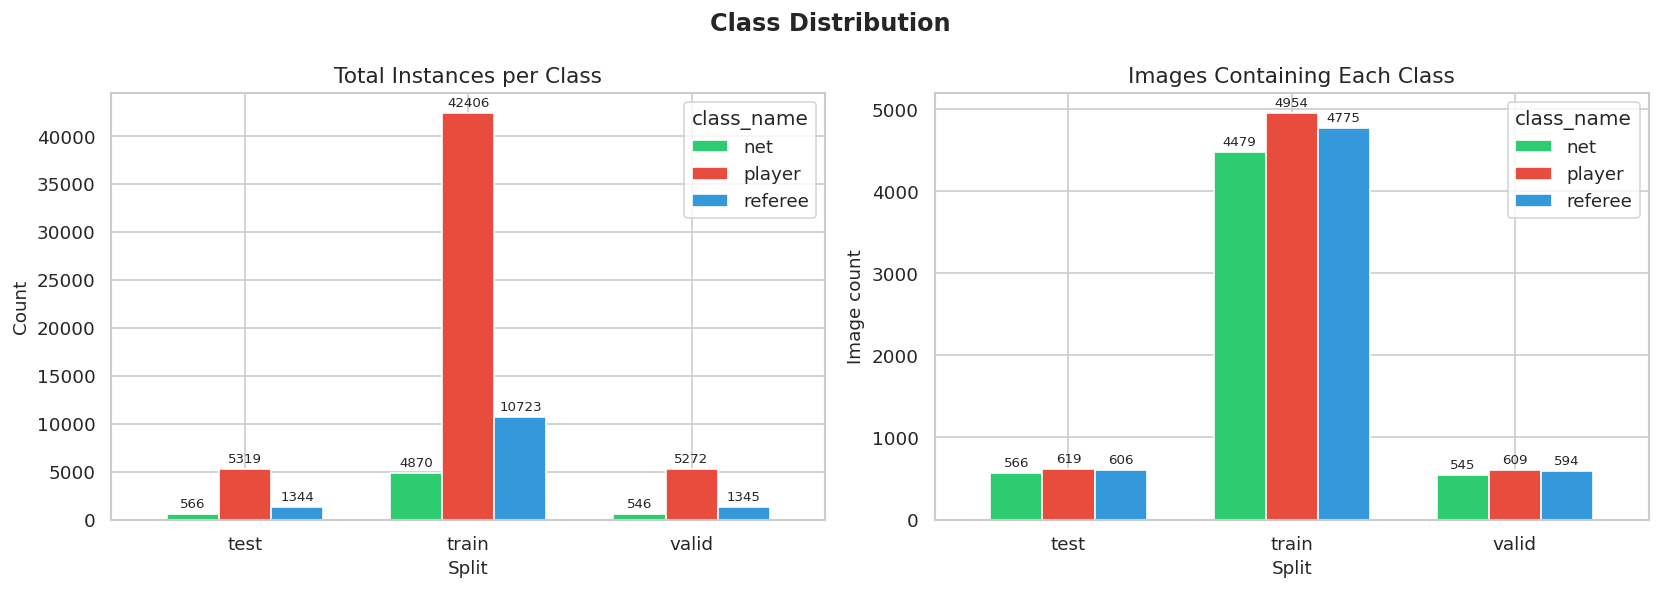

Class summary:             instances  images  instances_pct
class_name                                  
net              5982    5590            8.3
player          52997    6182           73.2
referee         13412    5975           18.5


In [ ]:
def plot_class_distribution(df_ann: pd.DataFrame,
                              class_names=CLASS_NAMES,
                              colors=CLASS_COLORS):
    """Bar charts: instance count and image count per class × split."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle("Class Distribution", fontweight="bold")

    # ── Instance counts ────────────────────────────────────────────────────
    inst = df_ann.groupby(["split","class_name"]).size().unstack(fill_value=0)
    inst = inst.reindex(columns=class_names, fill_value=0)
    inst.plot(kind="bar", ax=axes[0], color=colors[:len(class_names)], edgecolor="white", width=0.7)
    axes[0].set_title("Total Instances per Class")
    axes[0].set_xlabel("Split"); axes[0].set_ylabel("Count")
    axes[0].tick_params(axis="x", rotation=0)
    for container in axes[0].containers:
        axes[0].bar_label(container, fmt="%d", fontsize=8, padding=2)

    # ── Image counts ───────────────────────────────────────────────────────
    img_cnt = (df_ann.groupby(["split","class_name"])["image_path"]
               .nunique().unstack(fill_value=0)
               .reindex(columns=class_names, fill_value=0))
    img_cnt.plot(kind="bar", ax=axes[1], color=colors[:len(class_names)], edgecolor="white", width=0.7)
    axes[1].set_title("Images Containing Each Class")
    axes[1].set_xlabel("Split"); axes[1].set_ylabel("Image count")
    axes[1].tick_params(axis="x", rotation=0)
    for container in axes[1].containers:
        axes[1].bar_label(container, fmt="%d", fontsize=8, padding=2)

    plt.tight_layout()
    plt.show()

    # Summary table
    summary = df_ann.groupby("class_name").agg(
        instances=("class_id","count"),
        images=("image_path","nunique")
    ).reindex(class_names)
    summary["instances_pct"] = (summary["instances"] / summary["instances"].sum() * 100).round(1)
    print("Class summary:", summary.to_string())

plot_class_distribution(df_ann)

**Comment**:

Obviously, since there are 10 players, 3 referees, and 2 baskets (usually only 1 in focus), the distribution is unbalanced with respect to the players. However, the unequal ratio in terms of the number of objects is not that drastic, although a true evaluation should consider the ratios between the total areas and not simply the count of instances per class.

### 6.3 · Bounding Box Size Analysis

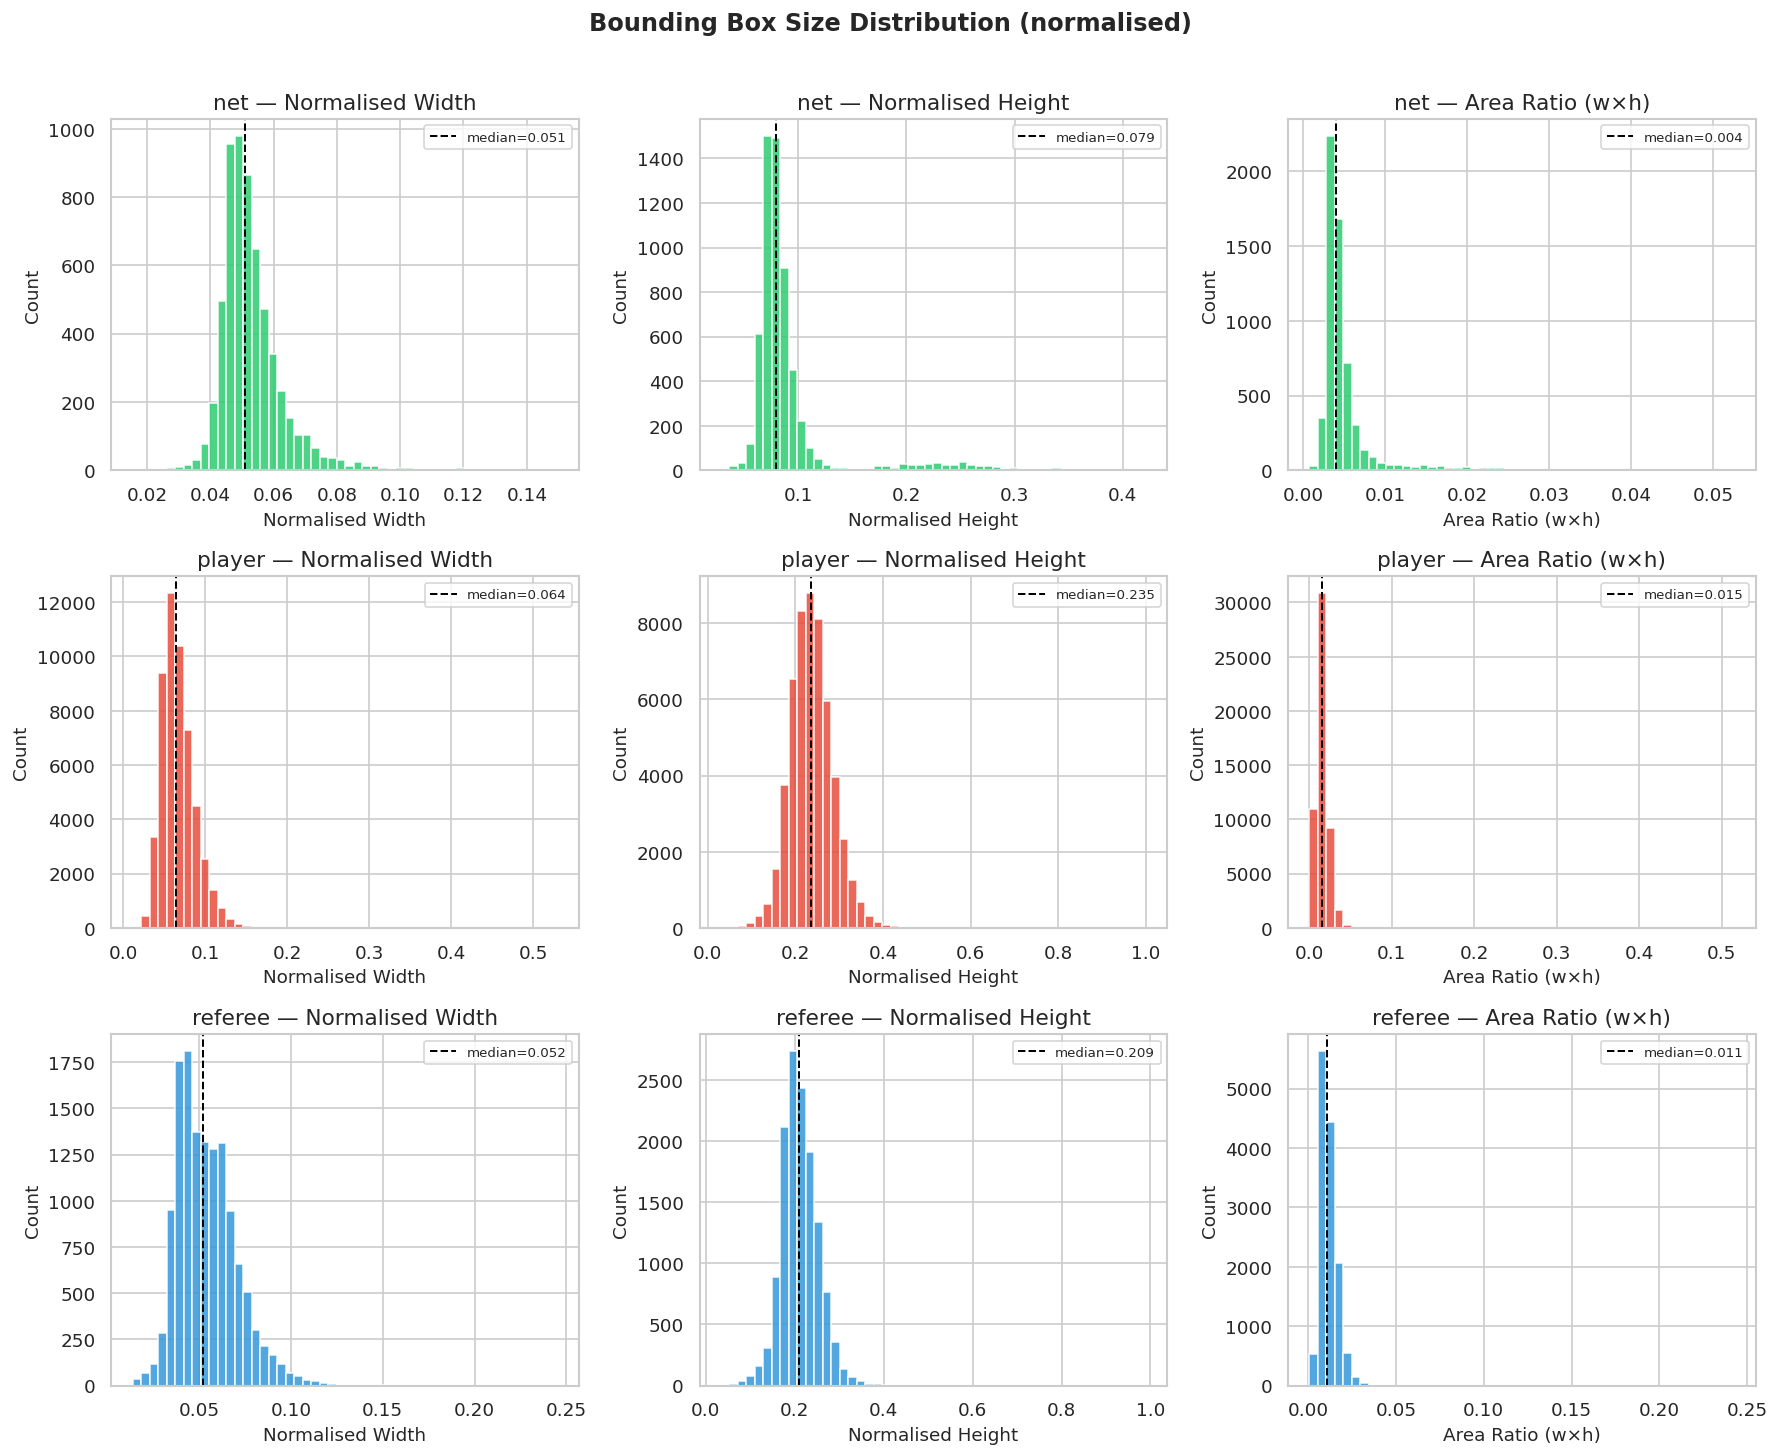

In [ ]:
def plot_bbox_size(df_ann: pd.DataFrame, class_names=CLASS_NAMES, colors=CLASS_COLORS):
    """Histograms of normalised width, height, and area ratio per class."""
    fig, axes = plt.subplots(len(class_names), 3,
                             figsize=(15, 4 * len(class_names)), squeeze=False)
    fig.suptitle("Bounding Box Size Distribution (normalised)", fontweight="bold", y=1.01)

    metrics = [("bw", "Normalised Width"),
               ("bh", "Normalised Height"),
               ("area_ratio", "Area Ratio (w×h)")]

    for r, cname in enumerate(class_names):
        sub = df_ann[df_ann["class_name"] == cname]
        for c, (col, label) in enumerate(metrics):
            axes[r][c].hist(sub[col].dropna(), bins=50,
                            color=colors[r], edgecolor="white", alpha=0.85)
            axes[r][c].set_title(f"{cname} — {label}")
            axes[r][c].set_xlabel(label)
            axes[r][c].set_ylabel("Count")
            med = sub[col].median()
            axes[r][c].axvline(med, color="black", linestyle="--", linewidth=1.2,
                               label=f"median={med:.3f}")
            axes[r][c].legend(fontsize=8)

    plt.tight_layout()
    plt.show()

plot_bbox_size(df_ann)

**Comment**:

BBox with low variance because NBA shots are fairly standard (same camera, similar distance, and angle).

Pros:

- More stable and faster training;
- Model learns scales more easily;
- Excellent performance in the NBA domain (standard broadcast);
- Easier anchor/scale matching.

Cons:

- Less robust to camera changes (higher/lateral angles, different FOVs);
- Possible overfitting to the "broadcast style";
- Degrades on non-standard datasets or shots.

### 6.4 · Aspect Ratio Analysis

In this section, we explore the appearance of the BBox for each class. A width/height ratio is calculated, therefore:
- val < 1 -> vertical bbox
- val = 1 -> square bbox
- val > 1 -> horizontal bbox

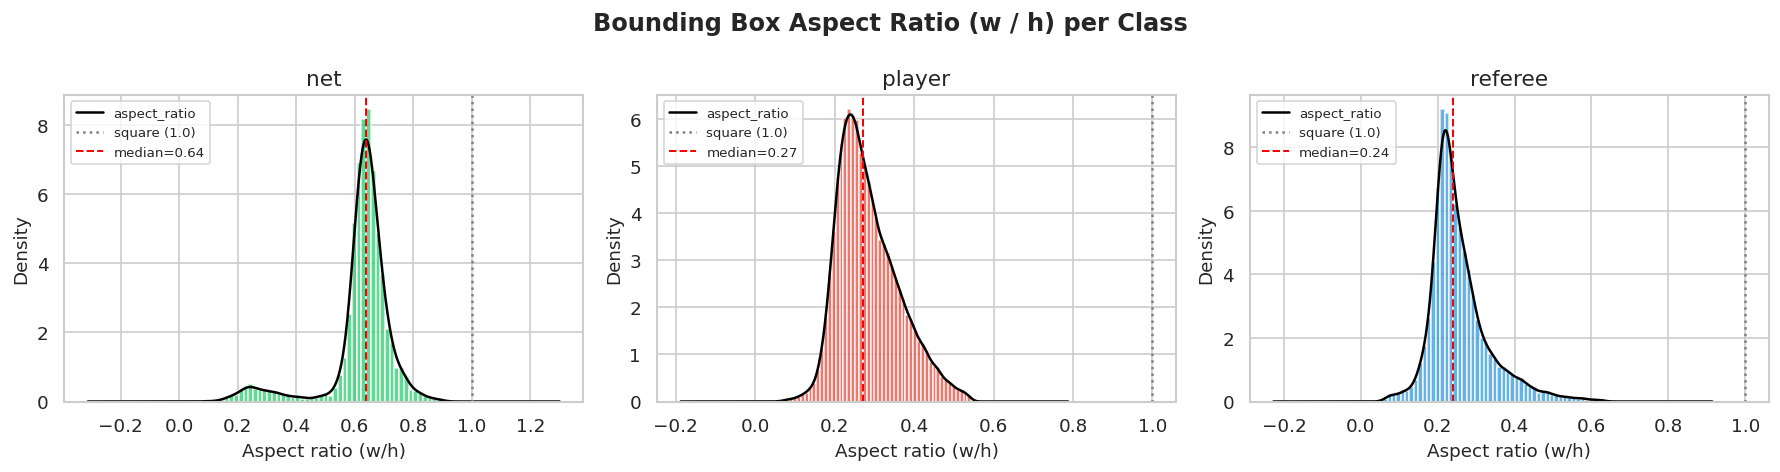

In [ ]:
def plot_aspect_ratio(df_ann: pd.DataFrame, class_names=CLASS_NAMES, colors=CLASS_COLORS):
    """KDE + histogram of bbox aspect ratio (w/h) per class."""
    fig, axes = plt.subplots(1, len(class_names),
                             figsize=(5 * len(class_names), 4), sharey=False)
    fig.suptitle("Bounding Box Aspect Ratio (w / h) per Class", fontweight="bold")

    for ax, cname, color in zip(axes, class_names, colors):
        sub = df_ann.loc[df_ann["class_name"] == cname, "aspect_ratio"].dropna()
        sub = sub[sub < sub.quantile(0.99)]          # clip extreme outliers for display
        ax.hist(sub, bins=50, color=color, edgecolor="white", alpha=0.75, density=True)
        sub.plot.kde(ax=ax, color="black", linewidth=1.5)
        ax.axvline(1.0, color="gray", linestyle=":", label="square (1.0)")
        ax.axvline(sub.median(), color="red", linestyle="--", linewidth=1.2,
                   label=f"median={sub.median():.2f}")
        ax.set_title(cname)
        ax.set_xlabel("Aspect ratio (w/h)")
        ax.set_ylabel("Density")
        ax.legend(fontsize=8)

    plt.tight_layout()
    plt.show()

plot_aspect_ratio(df_ann)

**Comment** :
- net -> The rate appears very consistent, with few elements far from the median, perhaps due to different camera angles or zoom.

- player -> Of the three classes, this is the one that shows the most variance. This is due to the fact that players are often in motion with different body positions, which can lead to slightly more varied rates in the bbox. Despite this, the bbox remains vertical, with a median rate very close to that of the referee class.

- referee -> Referees are also often in motion (running/walking), but their movements are often less complex. This is evident in the bbox rate, which is less varied than that of the players but more so than that of the basket.

### 6.5 · Object Density per Image

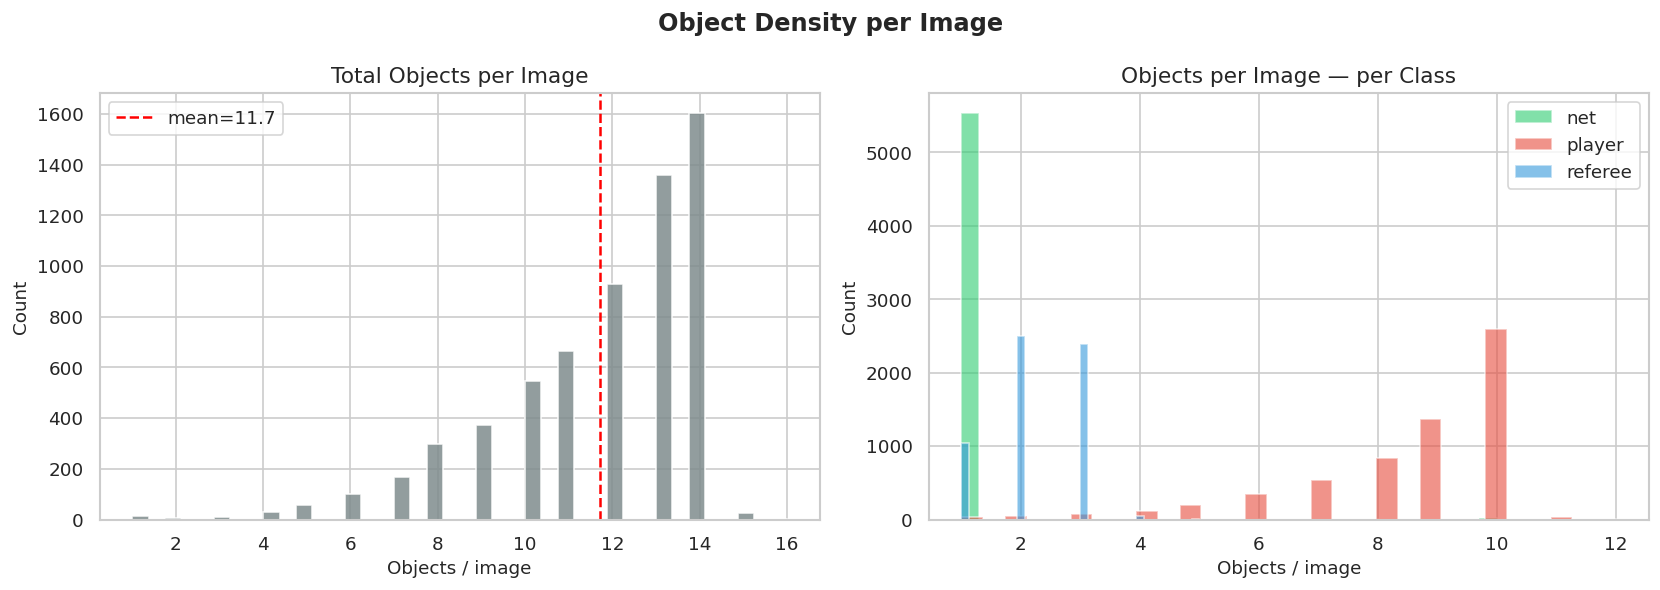

Mean objects / image : 11.71
Max  objects / image : 16
Median               : 12.0


In [ ]:
def plot_object_density(df_all: pd.DataFrame,
                          df_ann: pd.DataFrame,
                          class_names=CLASS_NAMES,
                          colors=CLASS_COLORS):
    """Overall objects-per-image histogram + per-class breakdown."""
    # Total objects per image
    total_per_img = (df_ann.groupby("image_path")["class_id"]
                     .count()
                     .reset_index(name="n_objects"))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle("Object Density per Image", fontweight="bold")

    axes[0].hist(total_per_img["n_objects"], bins=40,
                 color="#7f8c8d", edgecolor="white", alpha=0.85)
    axes[0].set_title("Total Objects per Image")
    axes[0].set_xlabel("Objects / image")
    axes[0].set_ylabel("Count")
    mean_d = total_per_img["n_objects"].mean()
    axes[0].axvline(mean_d, color="red", linestyle="--",
                    label=f"mean={mean_d:.1f}")
    axes[0].legend()

    # Per-class objects per image
    for cname, color in zip(class_names, colors):
        per_img = (df_ann[df_ann["class_name"] == cname]
                   .groupby("image_path")["class_id"].count())
        axes[1].hist(per_img, bins=30, alpha=0.6, label=cname, color=color,
                     edgecolor="white")
    axes[1].set_title("Objects per Image — per Class")
    axes[1].set_xlabel("Objects / image")
    axes[1].set_ylabel("Count")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

    print(f"Mean objects / image : {mean_d:.2f}")
    print(f"Max  objects / image : {total_per_img['n_objects'].max()}")
    print(f"Median               : {total_per_img['n_objects'].median()}")

plot_object_density(df_all, df_ann)

**Comment**:
- As previously mentioned, we expect a maximum of 10 players, but depending on the type of action, fewer players may be on screen; 2 baskets (nets), of which only one is in frame at a time; 3 referees, but often only 2 are in frame. Therefore, a maximum of 15 objects per image.

- Given the previous assumptions, the dataset appears to adhere fairly closely to them, with some outliers.

### 6.6 · Spatial Heatmaps

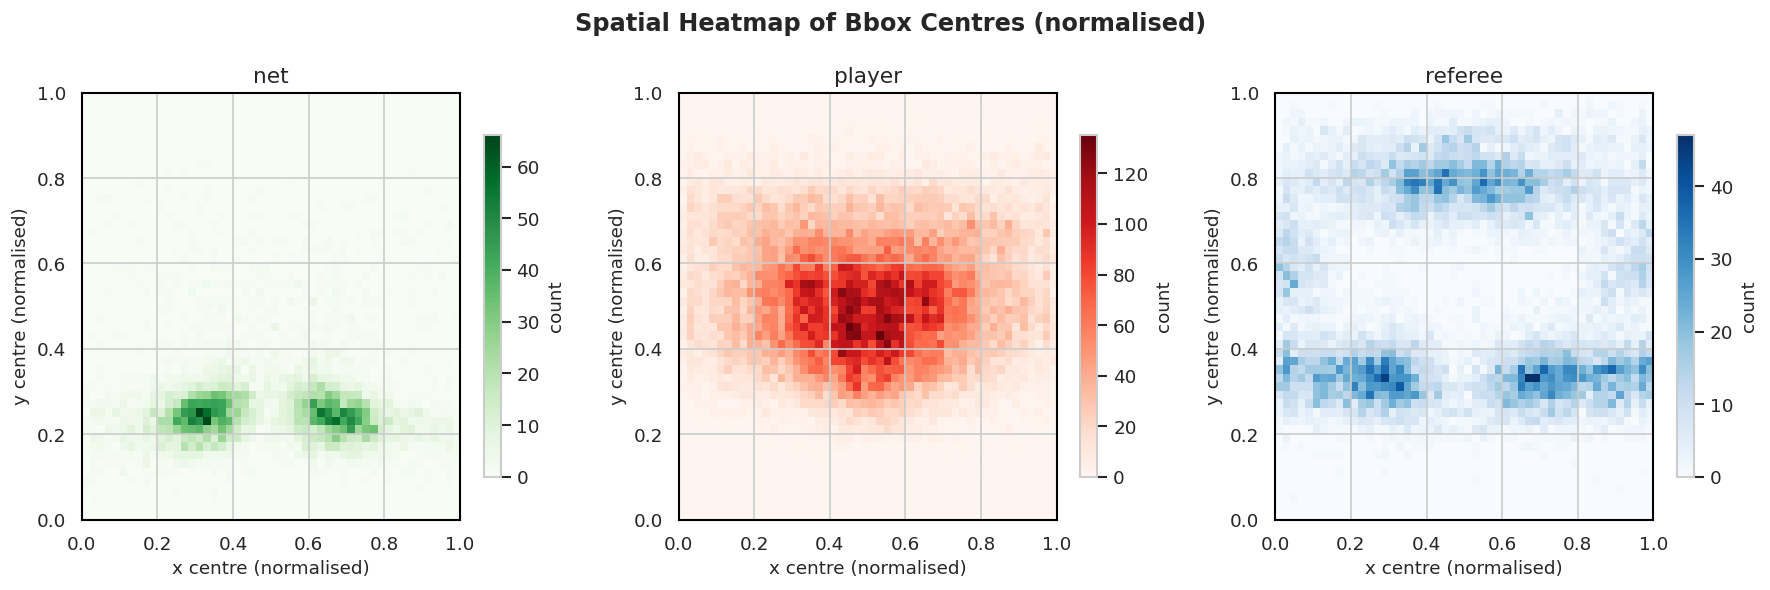

In [ ]:
def plot_spatial_heatmaps(df_ann: pd.DataFrame,
                            class_names=CLASS_NAMES,
                            bins: int = 50):
    """KDE heatmap of normalised bbox centres (xc, yc) per class."""
    fig, axes = plt.subplots(1, len(class_names),
                             figsize=(5 * len(class_names), 5))
    fig.suptitle("Spatial Heatmap of Bbox Centres (normalised)", fontweight="bold")

    cmaps = ["Greens", "Reds", "Blues"]

    for ax, cname, cmap in zip(axes, class_names, cmaps):
        sub = df_ann[df_ann["class_name"] == cname][["xc","yc"]].dropna()
        if sub.empty:
            ax.set_title(f"{cname} — no data"); continue

        h, xedges, yedges = np.histogram2d(
            sub["xc"], sub["yc"], bins=bins, range=[[0,1],[0,1]])
        h_smooth = h.T               # transpose so (y, x)

        im = ax.imshow(h_smooth, origin="lower", extent=[0,1,0,1],
                       aspect="auto", cmap=cmap)
        ax.set_title(cname)
        ax.set_xlabel("x centre (normalised)")
        ax.set_ylabel("y centre (normalised)")
        fig.colorbar(im, ax=ax, shrink=0.8, label="count")

        # Overlay image-frame outline
        for spine in ax.spines.values():
            spine.set_edgecolor("black")

    plt.tight_layout()
    plt.show()

plot_spatial_heatmaps(df_ann)

**Comment**:
- You can immediately see the positions of the players and referees in the images. You can already reconstruct the outline of the court.

- The positioning of the basket is unclear, but it was likely reversed because the coordinate convention in images sets y=0 as the upper limit and y=1 as the lower limit.

### 6.7 · Occlusion Proxy Analysis (Intra-Image IoU)

To analyze bbox overlap, we use the IoU metric, which allows us to numerically express the degree of bbox overlap:

- IoU = 0 → no overlap
(bboxes are completely separated);
- IoU = 1 → perfect overlap;
(bboxes coincide exactly)
- 0 < IoU < 1 → partial overlap.

Occlusion proxy:   0%|          | 0/2000 [00:00<?, ?it/s]

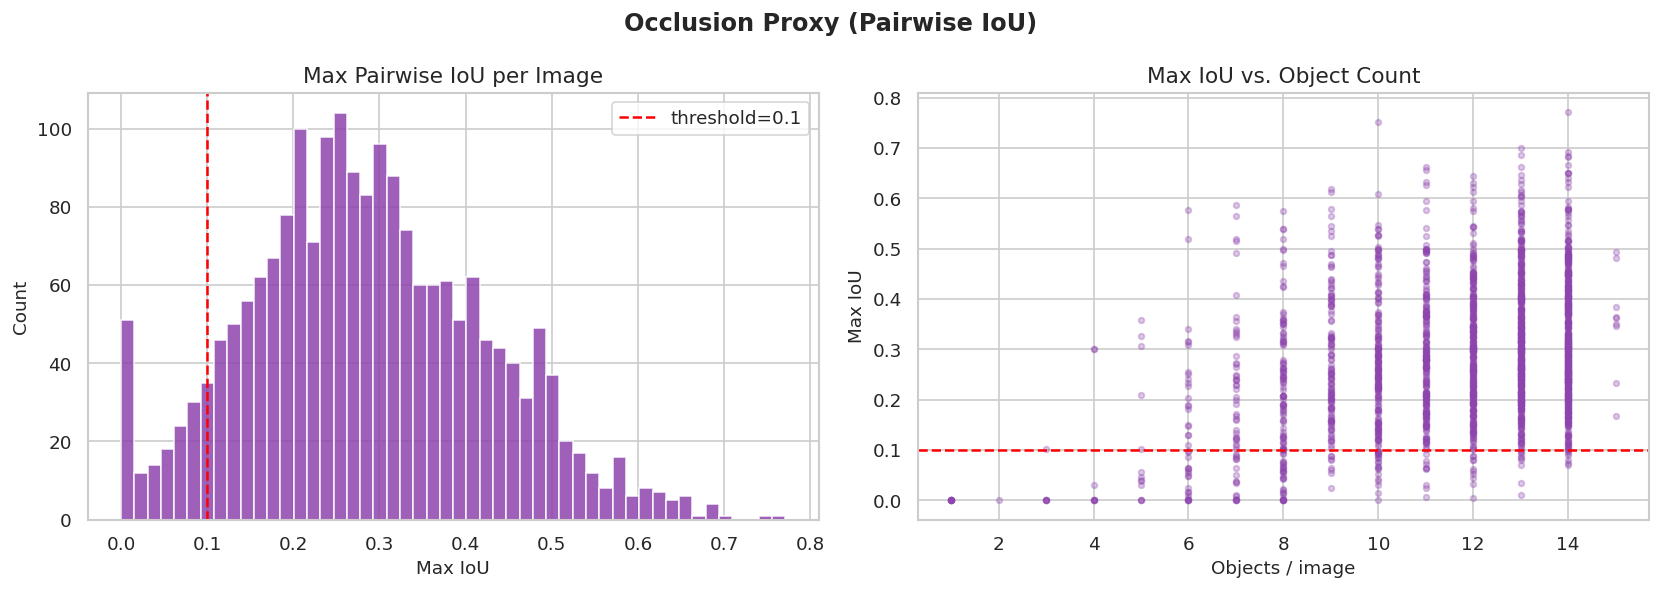

Crowded frames (max_iou ≥ 0.1): 1838 / 2000  (91.9 %)
Top crowded images:
                                                                                                                                          image_path  max_iou  n_objects
/content/drive/MyDrive/DeepLearningProject/datasets/pla_ref_bal_net_6870.yolo26/train/images/CHA_NOP_FGM_20_mp4-0002_jpg.rf.fptWVtBi5xNy6BMzhIpC.jpg 0.771159         14
 /content/drive/MyDrive/DeepLearningProject/datasets/pla_ref_bal_net_6870.yolo26/train/images/DET_ORL_FGM_6_mp4-0006_jpg.rf.Mb4LpcprFdquTv2bt2v2.jpg 0.752280         10
 /content/drive/MyDrive/DeepLearningProject/datasets/pla_ref_bal_net_6870.yolo26/train/images/BKN_NOP_FGM_2_mp4-0004_jpg.rf.qjTdyu4Jy6zJRQQYSDGO.jpg 0.699544         13
/content/drive/MyDrive/DeepLearningProject/datasets/pla_ref_bal_net_6870.yolo26/train/images/BKN_NOP_FGM_14_mp4-0001_jpg.rf.Ml3TQRTIuhKYN5oknuAH.jpg 0.692467         14
 /content/drive/MyDrive/DeepLearningProject/datasets/pla_ref_bal_net_6870.yolo26/

In [ ]:
def iou_pair(b1, b2):
    """IoU between two YOLO normalised boxes [xc, yc, w, h]."""
    x1_min = b1[0] - b1[2] / 2;  x1_max = b1[0] + b1[2] / 2
    y1_min = b1[1] - b1[3] / 2;  y1_max = b1[1] + b1[3] / 2
    x2_min = b2[0] - b2[2] / 2;  x2_max = b2[0] + b2[2] / 2
    y2_min = b2[1] - b2[3] / 2;  y2_max = b2[1] + b2[3] / 2

    ix = max(0, min(x1_max, x2_max) - max(x1_min, x2_min))
    iy = max(0, min(y1_max, y2_max) - max(y1_min, y2_min))
    inter = ix * iy
    union = b1[2]*b1[3] + b2[2]*b2[3] - inter
    return inter / union if union > 0 else 0.0


def compute_occlusion_proxy(df_ann: pd.DataFrame,
                             iou_thresh: float = 0.1,
                             max_images: int = 2000) -> pd.DataFrame:
    """
    For each image compute max pairwise IoU among all bboxes.
    Returns a DataFrame: image_path, max_iou, n_objects.
    """
    records = []
    images  = df_ann["image_path"].unique()[:max_images]

    for img_path in tqdm(images, desc="Occlusion proxy"):
        sub = df_ann[df_ann["image_path"] == img_path][["xc","yc","bw","bh"]].dropna()
        boxes = sub.values.tolist()
        n = len(boxes)
        max_iou = 0.0
        for i in range(n):
            for j in range(i+1, n):
                iou = iou_pair(boxes[i], boxes[j])
                max_iou = max(max_iou, iou)
        records.append({"image_path": img_path, "max_iou": max_iou, "n_objects": n})

    return pd.DataFrame(records)


def plot_occlusion_proxy(df_occ: pd.DataFrame, iou_thresh: float = 0.1):
    crowded = df_occ[df_occ["max_iou"] >= iou_thresh]
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle("Occlusion Proxy (Pairwise IoU)", fontweight="bold")

    axes[0].hist(df_occ["max_iou"], bins=50, color="#8e44ad",
                 edgecolor="white", alpha=0.85)
    axes[0].axvline(iou_thresh, color="red", linestyle="--",
                    label=f"threshold={iou_thresh}")
    axes[0].set_title("Max Pairwise IoU per Image")
    axes[0].set_xlabel("Max IoU"); axes[0].set_ylabel("Count"); axes[0].legend()

    axes[1].scatter(df_occ["n_objects"], df_occ["max_iou"],
                    alpha=0.3, s=12, color="#8e44ad")
    axes[1].axhline(iou_thresh, color="red", linestyle="--")
    axes[1].set_title("Max IoU vs. Object Count")
    axes[1].set_xlabel("Objects / image"); axes[1].set_ylabel("Max IoU")

    plt.tight_layout()
    plt.show()

    print(f"Crowded frames (max_iou ≥ {iou_thresh}): "
          f"{len(crowded)} / {len(df_occ)}  "
          f"({100*len(crowded)/max(len(df_occ),1):.1f} %)")
    if not crowded.empty:
        print("Top crowded images:")
        print(crowded.nlargest(5,"max_iou")[["image_path","max_iou","n_objects"]].to_string(index=False))


df_occlusion = compute_occlusion_proxy(df_ann)
plot_occlusion_proxy(df_occlusion)

**Comment**:

In an NBA game, we often see scenes of overlapping players, due to the nature of the sport. However, some precision is required. In most shots, the camera is positioned at a certain angle and distance to minimize overlap due to perspective. Most players in most plays have low overlap, at most attacker vs. defender. Players close to the ball, especially in plays near the basket, are those most affected by overlap.

The dataset meets the game assumptions, with the maximum IoU varying quite a bit but only exceeding 0.5 in a few cases.

Furthermore, the second graph shows how, as the scene becomes more crowded, the IoU level also increases.


### 6.8 · Duplicate / Near-Duplicate Detection

In [ ]:
def detect_near_duplicates(df_all: pd.DataFrame,
                             hash_size: int = 8,
                             max_diff: int = 5) -> pd.DataFrame:
    """
    Compute perceptual hash (pHash) for each unique image.
    Returns a DataFrame of near-duplicate pairs (hamming distance ≤ max_diff).
    """
    if not _IMAGEHASH_OK:
        print("⚠️  imagehash not available — skipping duplicate detection.")
        return pd.DataFrame()

    img_paths = df_all["image_path"].unique()
    hashes = {}
    for p in tqdm(img_paths, desc="Hashing images"):
        try:
            h = imagehash.phash(PILImage.open(p), hash_size=hash_size) # utilizzo un hash che riassume le principali feature per fare
                                                                      # il confronto immagine per immagine di tutto il dataset
                                                                      # che pixel by pixel sarebbe impossibile
            hashes[p] = h
        except Exception:
            pass

    paths  = list(hashes.keys())
    pairs  = []
    for i in range(len(paths)):
        for j in range(i+1, len(paths)):
            dist = hashes[paths[i]] - hashes[paths[j]]
            if dist <= max_diff:
                pairs.append({"img_a": paths[i], "img_b": paths[j],
                               "hamming": dist})
    df_pairs = pd.DataFrame(pairs)

    print(f"Near-duplicate pairs found (hamming ≤ {max_diff}): {len(df_pairs)}")
    if not df_pairs.empty:
        print(df_pairs.head(10).to_string(index=False))
    else:
        print("✅  No near-duplicates detected.")
    return df_pairs


df_duplicates = detect_near_duplicates(df_all) # df_duplicates contiene il path delle due immagini
                                                # simili e la misura della distanza (hamming)

Hashing images:   0%|          | 0/6600 [00:00<?, ?it/s]

Near-duplicate pairs found (hamming ≤ 5): 586
                                                                                                                                               img_a                                                                                                                                                img_b  hamming
/content/drive/MyDrive/DeepLearningProject/datasets/pla_ref_bal_net_6870.yolo26/train/images/ATL_HOU_FGM_11_mp4-0007_jpg.rf.7uiydrYJndJAEYFcQrz6.jpg /content/drive/MyDrive/DeepLearningProject/datasets/pla_ref_bal_net_6870.yolo26/train/images/ATL_HOU_FGM_11_mp4-0008_jpg.rf.S4cMUsTUoy0IC8wNkPMI.jpg        4
/content/drive/MyDrive/DeepLearningProject/datasets/pla_ref_bal_net_6870.yolo26/train/images/ATL_HOU_FGM_14_mp4-0001_jpg.rf.pVOf6cwqVm743cbHY1iS.jpg /content/drive/MyDrive/DeepLearningProject/datasets/pla_ref_bal_net_6870.yolo26/valid/images/ATL_HOU_FGM_14_mp4-0000_jpg.rf.3AllpmUpDo6pOZIbg38U.jpg        2
/content/drive/MyDrive/DeepLearni

**Commento**:

The dataset contains elements that appear to be duplicates (images that appear too similar to each other), in this case 585, or approximately 8-9% of the entire dataset. This is because many images come from the same batch.
These images may not provide any benefit to the model's training, or worse, they could lead to overfitting.

A filter based on hamming distance could be implemented.

### 6.9 · Train / Val Leakage Check

This code checks for data leakage between the training/validation/test phases, i.e., if identical or nearly identical images end up in different splits. It analyzes the images from the list created in the previous section, checking where they appear in the dataset.

In [ ]:
def check_split_leakage(df_duplicates: pd.DataFrame,
                          df_all: pd.DataFrame) -> None:
    """
    Flag near-duplicate pairs that appear in different splits
    (e.g. an image in train is near-identical to one in val → data leakage).
    """
    if df_duplicates.empty:
        print("No duplicates to check — leakage risk: minimal.")
        return

    path_to_split = df_all.drop_duplicates("image_path").set_index("image_path")["split"]
    df_dup = df_duplicates.copy()
    df_dup["split_a"] = df_dup["img_a"].map(path_to_split)
    df_dup["split_b"] = df_dup["img_b"].map(path_to_split)
    leakage = df_dup[df_dup["split_a"] != df_dup["split_b"]]

    print(f"Cross-split near-duplicate pairs (leakage candidates): {len(leakage)}")
    if not leakage.empty:
        print("⚠️  Potential leakage detected:")
        print(leakage.to_string(index=False))
    else:
        print("✅  No cross-split near-duplicates found.")


# Filename-stem overlap check (fast, no hashing required)
def check_stem_overlap(df_all: pd.DataFrame) -> None:
    """Detect identical file stems across splits (common in frame-extracted videos)."""
    stem_split = defaultdict(set)
    for _, row in df_all.drop_duplicates("image_path").iterrows():
        stem = Path(row["image_path"]).stem
        stem_split[stem].add(row["split"])

    conflicts = {s: splits for s, splits in stem_split.items() if len(splits) > 1}
    print(f"File-stem overlap across splits: {len(conflicts)} conflicts")
    if conflicts:
        for stem, splits in list(conflicts.items())[:10]:
            print(f"  {stem}: {splits}")
    else:
        print("✅  No file-stem overlap found.")


check_stem_overlap(df_all)
check_split_leakage(df_duplicates, df_all)

File-stem overlap across splits: 0 conflicts
✅  No file-stem overlap found.
Cross-split near-duplicate pairs (leakage candidates): 175
⚠️  Potential leakage detected:
                                                                                                                                               img_a                                                                                                                                                img_b  hamming split_a split_b
/content/drive/MyDrive/DeepLearningProject/datasets/pla_ref_bal_net_6870.yolo26/train/images/ATL_HOU_FGM_14_mp4-0001_jpg.rf.pVOf6cwqVm743cbHY1iS.jpg /content/drive/MyDrive/DeepLearningProject/datasets/pla_ref_bal_net_6870.yolo26/valid/images/ATL_HOU_FGM_14_mp4-0000_jpg.rf.3AllpmUpDo6pOZIbg38U.jpg        2   train   valid
/content/drive/MyDrive/DeepLearningProject/datasets/pla_ref_bal_net_6870.yolo26/train/images/ATL_HOU_FGM_16_mp4-0001_jpg.rf.izf2mwjENuWW7cLs7e44.jpg   /content/drive/MyDrive/DeepLearningP

**Comment**:

There are 175 images in this section in total, which, if we consider an equal division between the valid and test sets, represents approximately 12-13% for both subsets. It's best to replace them in the validation and test sets.

### 6.10 · Image Statistics

Image stats:   0%|          | 0/3000 [00:00<?, ?it/s]

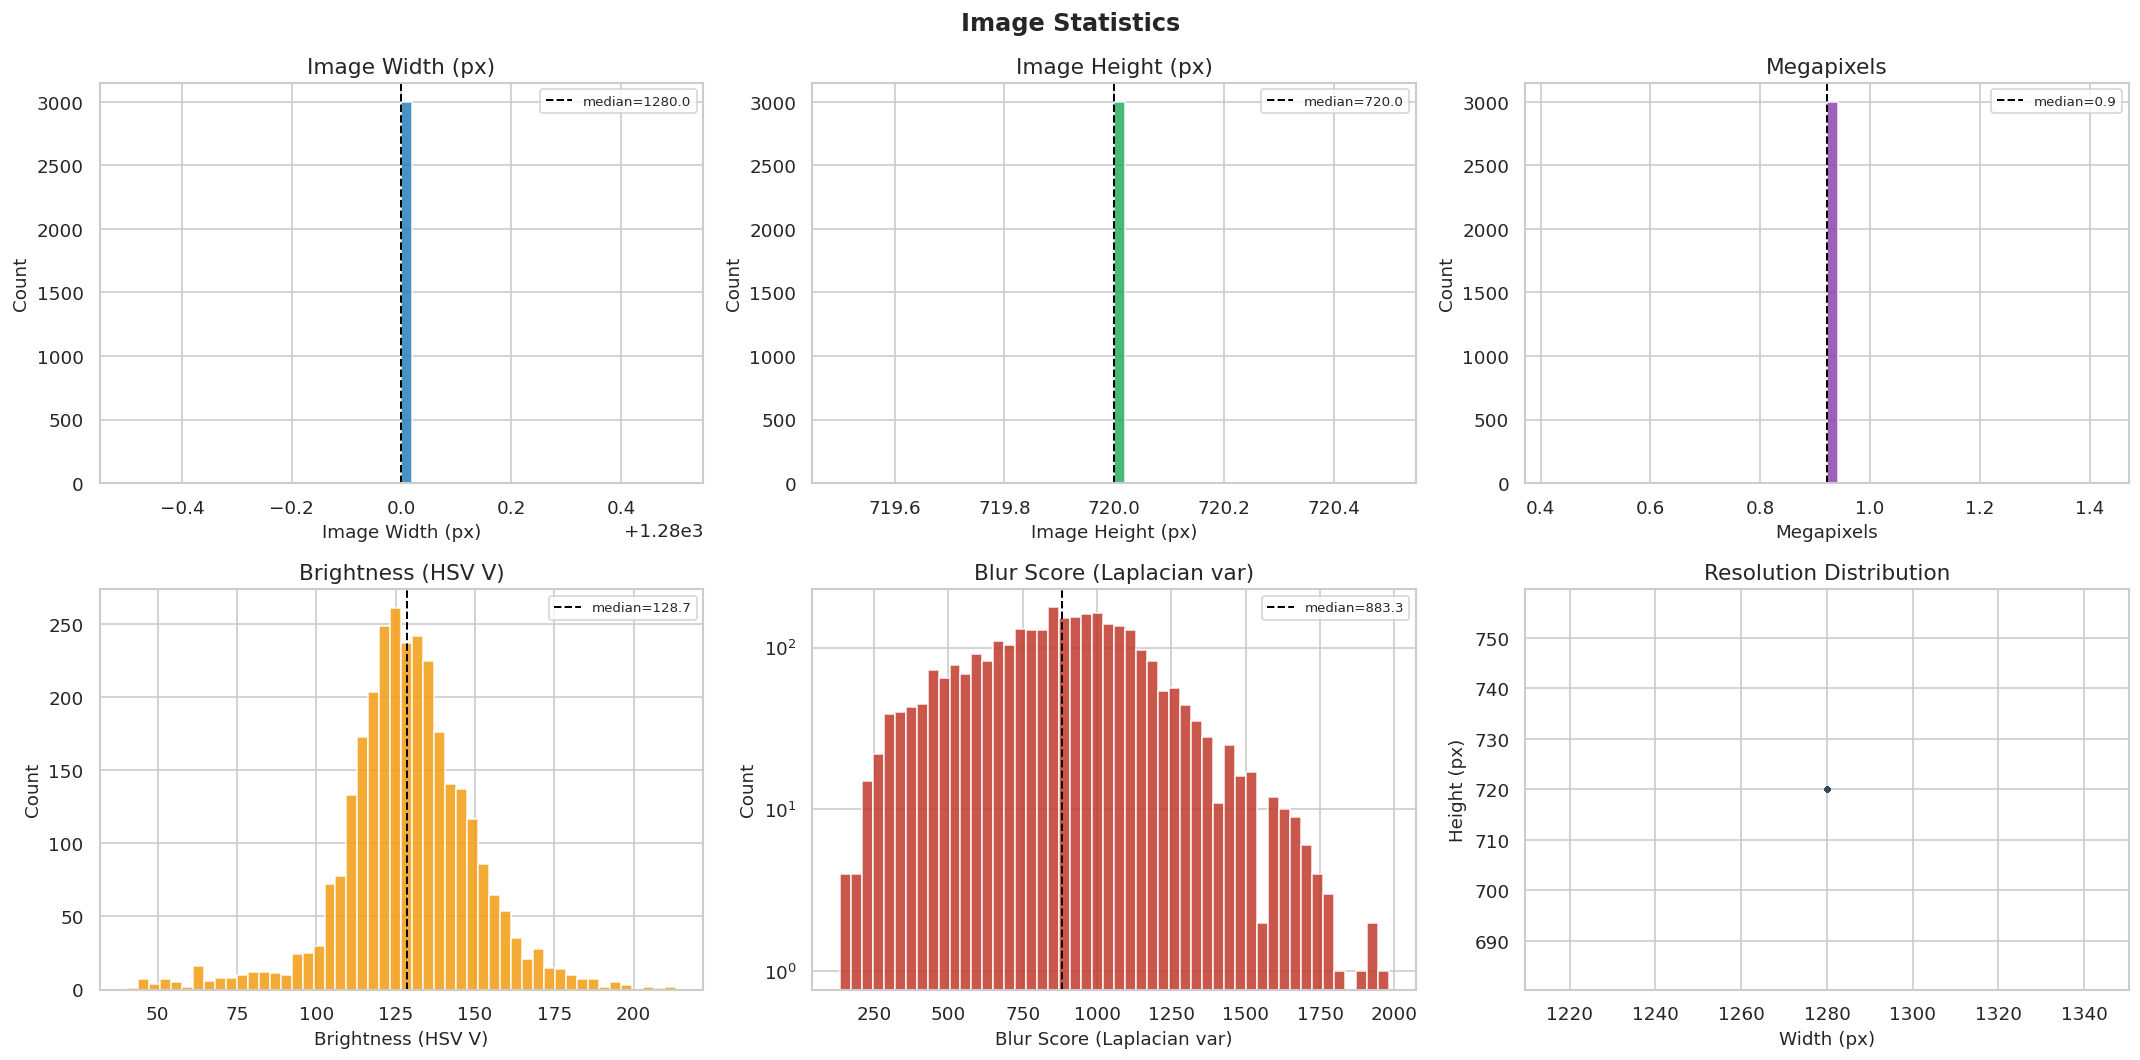

Image stats summary:
        width  height  megapixels  brightness  blur_score
count  3000.0  3000.0     3000.00     3000.00     3000.00
mean   1280.0   720.0        0.92      128.99      875.77
std       0.0     0.0        0.00       20.94      292.55
min    1280.0   720.0        0.92       40.34      134.49
25%    1280.0   720.0        0.92      118.03      680.17
50%    1280.0   720.0        0.92      128.72      883.27
75%    1280.0   720.0        0.92      140.75     1065.53
max    1280.0   720.0        0.92      213.25     1980.33
⚠️  Very dark images (brightness < 30): 0
⚠️  Potentially blurry images (bottom 5% blur): 150


In [ ]:
def compute_image_stats(df_all: pd.DataFrame,
                          max_images: int = 3000) -> pd.DataFrame:
    """
    For a sample of unique images compute:
      - resolution (width, height, megapixels)
      - mean brightness (HSV V channel)
      - blur score (Laplacian variance — higher = sharper)
    """
    img_paths = df_all["image_path"].unique()[:max_images]
    stats = []

    for p in tqdm(img_paths, desc="Image stats"):
        img = cv2.imread(p)
        if img is None:
            continue
        h, w = img.shape[:2]
        gray   = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        hsv    = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        bright = float(hsv[:,:,2].mean())
        blur   = float(cv2.Laplacian(gray, cv2.CV_64F).var())
        stats.append({"image_path": p, "width": w, "height": h,
                      "megapixels": w*h/1e6, "brightness": bright,
                      "blur_score": blur})

    return pd.DataFrame(stats)


def plot_image_stats(df_stats: pd.DataFrame):
    fig, axes = plt.subplots(2, 3, figsize=(18, 9))
    fig.suptitle("Image Statistics", fontweight="bold")

    def hist(ax, col, label, color, log=False):
        data = df_stats[col].dropna()
        ax.hist(data, bins=50, color=color, edgecolor="white", alpha=0.85,
                log=log)
        ax.set_title(label)
        ax.set_xlabel(label)
        ax.set_ylabel("Count")
        ax.axvline(data.median(), color="black", linestyle="--", linewidth=1.2,
                   label=f"median={data.median():.1f}")
        ax.legend(fontsize=8)

    hist(axes[0,0], "width",       "Image Width (px)",     "#2980b9")
    hist(axes[0,1], "height",      "Image Height (px)",    "#27ae60")
    hist(axes[0,2], "megapixels",  "Megapixels",           "#8e44ad")
    hist(axes[1,0], "brightness",  "Brightness (HSV V)",   "#f39c12")
    hist(axes[1,1], "blur_score",  "Blur Score (Laplacian var)", "#c0392b", log=True)

    # Resolution scatter
    axes[1,2].scatter(df_stats["width"], df_stats["height"],
                      alpha=0.25, s=6, color="#34495e")
    axes[1,2].set_title("Resolution Distribution")
    axes[1,2].set_xlabel("Width (px)"); axes[1,2].set_ylabel("Height (px)")

    plt.tight_layout()
    plt.show()

    print("Image stats summary:")
    print(df_stats[["width","height","megapixels","brightness","blur_score"]]
          .describe().round(2).to_string())

    # Flag very dark or very blurry images
    dark  = df_stats[df_stats["brightness"] < 30]
    blurry= df_stats[df_stats["blur_score"] < df_stats["blur_score"].quantile(0.05)]
    print(f"⚠️  Very dark images (brightness < 30): {len(dark)}")
    print(f"⚠️  Potentially blurry images (bottom 5% blur): {len(blurry)}")


df_img_stats = compute_image_stats(df_all)
plot_image_stats(df_img_stats)

**Comment**:

- The images in this dataset all have the same dimensions and resolutions.

- WARNING: It suffers from some blurriness, but considering the people in motion, this cannot be avoided.

### 6.11 · Annotated Sample Grid

In [ ]:
def draw_yolo_boxes(img_bgr: np.ndarray,
                     boxes_norm: list,
                     class_ids: list,
                     class_names=CLASS_NAMES,
                     colors_rgb=None) -> np.ndarray:
    """Draw YOLO normalised bboxes on a BGR image; returns RGB copy."""
    if colors_rgb is None:
        colors_rgb = [(46,204,113), (231,76,60), (52,152,219)]
    img = img_bgr.copy()
    h, w = img.shape[:2]
    for (xc, yc, bw, bh), cid in zip(boxes_norm, class_ids):
        x1 = int((xc - bw/2) * w); y1 = int((yc - bh/2) * h)
        x2 = int((xc + bw/2) * w); y2 = int((yc + bh/2) * h)
        color = colors_rgb[cid % len(colors_rgb)][::-1]   # RGB→BGR
        cv2.rectangle(img, (x1,y1), (x2,y2), color, 2)
        label = class_names[cid] if cid < len(class_names) else str(cid)
        cv2.putText(img, label, (x1, max(y1-5,10)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, color, 2)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def show_sample_grid(df_ann: pd.DataFrame,
                     n: int = 16,
                     ncols: int = 4,
                     title: str = "Random Annotated Samples",
                     filter_fn=None,
                     seed: int = 42):
    """
    Display a grid of n random images with bboxes drawn.
    Pass a filter_fn(df_subset) → bool mask for edge-case highlighting.
    """
    imgs_with_ann = df_ann["image_path"].unique()
    rng = random.Random(seed)
    sample = rng.sample(list(imgs_with_ann), min(n, len(imgs_with_ann)))

    nrows = int(np.ceil(len(sample) / ncols))
    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(5 * ncols, 4 * nrows))
    fig.suptitle(title, fontweight="bold", y=1.01)
    axes = np.array(axes).flatten()

    for ax, img_path in zip(axes, sample):
        img = cv2.imread(img_path)
        if img is None:
            ax.axis("off"); continue
        sub  = df_ann[df_ann["image_path"] == img_path]
        boxes = sub[["xc","yc","bw","bh"]].values.tolist()
        cids  = sub["class_id"].astype(int).tolist()
        rgb   = draw_yolo_boxes(img, boxes, cids)
        ax.imshow(rgb)
        ax.set_title(Path(img_path).name, fontsize=7)
        ax.axis("off")

    for ax in axes[len(sample):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


# Random samples
show_sample_grid(df_ann, n=16, ncols=4, title="Random Annotated Samples")

# Crowded / occluded edge cases
if not df_occlusion.empty:
    crowded_paths = df_occlusion.nlargest(12, "max_iou")["image_path"].tolist()
    crowded_df    = df_ann[df_ann["image_path"].isin(crowded_paths)]
    if not crowded_df.empty:
        show_sample_grid(crowded_df, n=12, ncols=4,
                         title="Edge Cases — Most Crowded / Occluded Frames")

Output hidden; open in https://colab.research.google.com to view.

**Comment**:
- The annotations in this example suggest that the dataset has been correctly annotated, although in the image IND_WAS_FMG_18_mp4-0004_jpg.rf... a referee has not been correctly annotated.

- As you can also see, there are images of a variety of teams wearing different colored jerseys, which is great for increasing variance and avoiding the risk of the model learning to identify a player based on color, which would therefore be ineffective on teams not present in the dataset.

### 6.12 · Analysis Summary

All quality checks completed. Review the outputs above before proceeding to training:

- **Severe class imbalance** → consider oversampling or weighted loss.
- **Many tiny bboxes** (area_ratio < 0.01) → train at higher `imgsz`.
- **High occlusion proxy IoU** → tune NMS `iou` threshold post-training.
- **Cross-split near-duplicates** → remove or quarantine leaked images.
- **Blurry / dark images** → consider filtering or targeted augmentation.

## 7 · TRAINING

### 7.1 · Look for checkpoints

In [ ]:
# ── Check for interrupted run ──────────────────────────────────────────────
_last_ckpt = (Path("/content/drive/MyDrive/DeepLearningProject") / (HYPERPARAMS["project"]) / HYPERPARAMS["name"] / "checkpoints" / "last.pt")
_resume    = _last_ckpt.exists()
if _resume:
    print(f"Interrupted run detected — resuming from {_last_ckpt}")
    model = YOLO(str(_last_ckpt))   # reload from checkpoint

### 7.2 · Callback that saves on Drive the checkpoints and the final results
This way, if the connection drops during a training session, I can pick up where I left off.
This section creates and adds callbacks to the model that take the partial saves automatically created by YOLO and save them to the corresponding folder on the drive.

#### 7.2.1 ·  Defining directories

In [ ]:
# ── Mount Drive (uncomment if needed) ─────────────────
# drive.mount('/content/drive')

# ── Source directories ────────────────────────────────
RUN_DIR = Path("/content/runs/detect") / HYPERPARAMS["project"] / HYPERPARAMS["name"]
WEIGHTS_DIR = RUN_DIR / "weights"

# ── Dove salvare su Drive checkpoints ─────────────────────────────
DRIVE_SAVE_DIR = (Path("/content/drive/MyDrive/DeepLearningProject" ) /  HYPERPARAMS["project"] /  HYPERPARAMS["name"]  / "checkpoints")
DRIVE_SAVE_DIR.mkdir(parents=True, exist_ok=True)

# ── Destination directory on Google Drive  completed────────────
MODEL_DRIVE_SAVE_DIR = (
    Path("/content/drive/MyDrive/DeepLearningProject")
    / HYPERPARAMS["project"]
    / HYPERPARAMS["name"]
    / "completed"
)
METRICS_DRIVE_SAVE_DIR= MODEL_DRIVE_SAVE_DIR / "metrics"

MODEL_DRIVE_SAVE_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DRIVE_SAVE_DIR.mkdir(parents=True, exist_ok=True)

#### 7.2.2 ·  Setting up the Drive and Backups

In [ ]:
#
#        GOOGLE DRIVE BACKUP SETUP (SAFE MODE)
#

# ── Backup function ────────────────────────────────────
def backup_checkpoints(run_dir: Path, drive_dir: Path):
    files = ["best.pt", "last.pt", "results.csv"]

    for f in files:
        # results.csv is one directory level up from the weights folder
        if f == "results.csv":
            src = run_dir.parent / f
        else:
            src = run_dir / f

        if src.exists():
            dst = drive_dir / f
            shutil.copy2(src, dst)
            print(f"✅ Backup: {f} → Drive")
        else:
            print(f"⚠️ Missing: {f}")

# ── Callback Ultralytics ──────────────────────────────
def on_train_epoch_end(trainer):
    epoch = trainer.epoch

    # salva ogni 10 epoche (modificabile)
    if epoch % 10 == 0 and epoch > 0:
        print(f"\nBackup checkpoint epoch {epoch}")
        try:
            backup_checkpoints(WEIGHTS_DIR, DRIVE_SAVE_DIR)
        except Exception as e:
            print("❌ Backup error:", e)

# ── Registra callback ──────────────────────────────────
model.add_callback("on_train_epoch_end", on_train_epoch_end)

print("✅ Auto-backup su Drive attivato")

✔ Auto-backup su Drive attivato


#### 7.2.3 ·  Final Backup

In [ ]:
#
#      GOOGLE DRIVE BACKUP AFTER TRAIN COMPLETION
#

# ── Backup function ───────────────────────────────────
def backup_training_results(run_dir: Path, drive_model_dir: Path, drive_metrics_dir: Path):
    """
    Backup:
      - from weights/: ONLY best.pt
      - from run_dir/: everything EXCEPT weights/
    """

    weights_dir = run_dir / "weights"


    # 1) Weights (filtered)

    if weights_dir.exists():
      for fname in ["best.pt"]:
          src = weights_dir / fname

          if src.exists():

            # ── Separate destinations ─────────────────────
            if fname == "best.pt":
                dst_model = drive_model_dir / "best.pt"

            shutil.copy2(src, dst_model)
            print(f"✅ Copied from weights: {fname}")

          else:
            print(f"⚠️ Missing in weights: {fname}")
    else:
        print(f"❌ Weights directory not found: {weights_dir}")


    # 2) Full run_dir backup excluding weights/

    for path in run_dir.rglob("*"):
        # skip weights folder entirely
        if weights_dir in path.parents or path == weights_dir:
            continue

        if path.is_file():
            relative_path = path.relative_to(run_dir)
            dst = drive_metrics_dir / relative_path
            dst.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(path, dst)
            print(f"✅ Copied: {relative_path}")

    print("\n✅ Backup completed successfully!")


# ── Callback: executes ONLY when training ends OK ────
def on_train_end(trainer):
    print("\nTraining completed — starting Drive backup...")

    try:
        backup_training_results(RUN_DIR, MODEL_DRIVE_SAVE_DIR, METRICS_DRIVE_SAVE_DIR)
    except Exception as e:
        print(f"❌ Backup error: {e}")


# ── Register callback ─────────────────────────────────
model.add_callback("on_train_end", on_train_end)

print("✅ Auto-backup on successful training completion activated")

✔ Auto-backup on successful training completion activated


### 7.3 · Loading dataset to local environment
To increase training performance, the dataset is loaded locally (on the machine that performs the training)

In [ ]:
logger = logging.getLogger(__name__)

def ensure_local_dataset_auto_zip(
    drive_base_path: str,
    dataset_name: str,
    local_base_path: str = "/content/dataset",
    force_copy: bool = False
) -> str:
    """
    Checks for a zipped dataset on Drive, creates it if missing,
    and extracts it to the local Colab SSD for maximum speed.
    """
    drive_folder = Path(drive_base_path) / dataset_name
    drive_zip = Path(drive_base_path) / f"{dataset_name}.zip"

    local_path = Path(local_base_path)
    local_zip_temp = Path(f"/content/{dataset_name}_temp.zip")

    # ==========================================
    # 1. Check if already extracted locally
    # ==========================================
    already_exists = local_path.exists() and (local_path / "data.yaml").exists()

    if already_exists and not force_copy:
        print(f"Local dataset already exists at {local_path} — skipping copy")
        return str(local_path)

    # Clean up existing local folder if forcing a re-copy
    if local_path.exists() and force_copy:
        print(f"Removing existing local dataset at {local_path}")
        shutil.rmtree(local_path)

    local_path.mkdir(parents=True, exist_ok=True)

    # ==========================================
    # 2. Ensure the ZIP exists on Google Drive
    # ==========================================
    if not drive_zip.exists():
        if not drive_folder.exists():
            raise FileNotFoundError(f"❌ Cannot find source dataset folder: {drive_folder}")

        print(f"ZIP file not found on Drive. Creating it now...")

        zip_cmd = f"cd '{drive_folder}' && zip -r -q '{drive_zip}' ."
        subprocess.run(zip_cmd, shell=True, check=True)
        print(f"✅ ZIP file created successfully on Drive at {drive_zip}")
    else:
        print(f"✅ Found existing ZIP file on Drive: {drive_zip}")

    # ==========================================
    # 3. Transfer and Extract
    # ==========================================
    print("Copying ZIP from Drive → local SSD...")
    shutil.copy2(drive_zip, local_zip_temp)

    print("Unzipping dataset locally...")
    subprocess.run(["unzip", "-q", str(local_zip_temp), "-d", str(local_path)], check=True)

    # Cleanup the temporary zip file to save Colab SSD space
    if local_zip_temp.exists():
        os.remove(local_zip_temp)

    print("✅ Dataset successfully copied and extracted to local SSD")
    return str(local_path)


drive_base_path= Path("/content/drive/MyDrive/DeepLearningProject/datasets")
DATASET_PATH = ensure_local_dataset_auto_zip(
    drive_base_path=drive_base_path,
    dataset_name=dataset_name,
    local_base_path="/content/dataset",
    force_copy=False
)

data_yaml_path = Path("/content/dataset")/dataset_name/"data.yaml"

✅ Found existing ZIP file on Drive: /content/drive/MyDrive/DeepLearningProject/datasets/pla_ref_bal_net_6870.yolo26.zip
🚀 Copying ZIP from Drive → local SSD...
📦 Unzipping dataset locally...
✅ Dataset successfully copied and extracted to local SSD


### 7.4 · Train

In [ ]:
def run_training(
    model: YOLO,
    data_yaml: Path,
    hyperparams: Dict[str, Any],
    resume: bool = False,
) -> Any:
    """
    Launch training.
    Pass resume=True to continue from an interrupted run (loads last.pt automatically).
    """
    logger.info("Starting training …")

    if resume:
        # When resuming, DO NOT pass **hyperparams.
        # YOLO extracts the original hyperparams from the checkpoint.
        results = model.train(
            data=str(data_yaml),
            resume=True
        )
    else:
        # Fresh start: pass the full hyperparams dictionary
        results = model.train(
            data=str(data_yaml),
            **hyperparams
        )

    logger.info("Training complete ✅")
    return results

train_results = run_training(model, data_yaml_path, REFINE_HYPERPARAMS, resume=_resume)

Ultralytics 8.4.60 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=True, auto_augment=randaugment, batch=12, bgr=0.0, box=11.186818225886567, cache=False, cfg=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.21406536956886552, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/pla_ref_bal_net_6870.yolo26/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=3.0044258325445217, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=8, erasing=0.0, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.01, hsv_s=0.2, hsv_v=0.2, imgsz=960, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/DeepLearningProject/yolo_npr/train_v4/completed/best.pt, momentum=0.937, m

## 8 · VALIDATION & EVALUATION

### 8.1 · Uploading the files needed to evaluate the model
This code is used to set the correct paths in Google Drive, in order to avoid uploading all the data manually.

In [ ]:
# -- USER CONFIG (change here to switch dataset) ----------------------
#dataset_name = 'pla_ref_bal_net_6870.yolo26'   # <- only thing to change

# -- Auto-derive dataset root -----------------------------------------
_DS_CANDIDATES = [
    Path('/content/dataset'),
    Path(f'/content/drive/MyDrive/DeepLearningProject/datasets/{dataset_name}'),
    Path(f'/content/drive/Shareddrives/DeepLearningProject/datasets/{dataset_name}'),
]
def _resolve_dataset_root():
    for p in _DS_CANDIDATES:
        if (p / 'data.yaml').exists():
            return p
    return _DS_CANDIDATES[0]

dataset_root   = _resolve_dataset_root()
data_yaml_auto = dataset_root / 'data.yaml'
print(f'dataset_root  -> {dataset_root}')
print(f'data.yaml     -> {data_yaml_auto}')
print(f'data.yaml ok  : {data_yaml_auto.exists()}')

# -- Drive mount -------------------------------------------------------
if not Path('/content/drive').exists():
    from google.colab import drive; drive.mount('/content/drive')

DRIVE_BASE  = Path('/content/drive/MyDrive/DeepLearningProject')
V2_RUN_NAME = HYPERPARAMS['name']
V1_RUN_NAME = 'train_v1'

def local_run_dir(run_name):
    return Path('/content/runs/detect') / HYPERPARAMS['project'] / run_name

def drive_run_dir(run_name):
    return DRIVE_BASE / HYPERPARAMS['project'] / run_name / 'completed'

def resolve_file(local_path, drive_path, label, copy_to_local=True):
    if local_path.exists():
        print(f'  [OK-local]  {label}\n              {local_path}')
        return local_path
    if drive_path.exists():
        print(f'  [OK-drive]  {label}\n              {drive_path}')
        if copy_to_local:
            local_path.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(str(drive_path), str(local_path))
            print(f'  [copied] -> {local_path}')
            return local_path
        return drive_path
    print(f'  [MISSING]   {label}\n    local: {local_path}\n    drive: {drive_path}')
    return None

print('\n' + '='*62)
print('  Section 7 -- File Resolution')
print('='*62)

metrics_path = resolve_file(
    local_run_dir(V2_RUN_NAME) / 'weights' / 'metrics_log.csv',
    drive_run_dir(V2_RUN_NAME) / 'metrics'  / 'metrics_log.csv',
    'metrics_log.csv',
)
best_weights = resolve_file(
    local_run_dir(V2_RUN_NAME) / 'weights' / 'best.pt',
    drive_run_dir(V2_RUN_NAME) / 'best.pt',
    'best.pt',
)
_local_json_v2  = local_run_dir(V2_RUN_NAME) / 'eval_metrics.json'
_drive_json_v2  = drive_run_dir(V2_RUN_NAME) / 'eval_metrics.json'
metrics_json_path = _local_json_v2
resolved_json_v2  = resolve_file(_local_json_v2, _drive_json_v2,
                                  f'eval_metrics.json ({V2_RUN_NAME})')
resolved_json_v1  = resolve_file(
    local_run_dir(V1_RUN_NAME) / 'eval_metrics.json',
    drive_run_dir(V1_RUN_NAME) / 'eval_metrics.json',
    f'eval_metrics.json ({V1_RUN_NAME})',
)

# -- All YOLO standard output images (Task 2) --------------------------
_YOLO_IMGS = [
    'results.png', 'confusion_matrix.png', 'confusion_matrix_normalized.png',
    'BoxF1_curve.png', 'BoxPR_curve.png', 'BoxP_curve.png', 'BoxR_curve.png',
    'labels.jpg', 'PR_curve.png', 'F1_curve.png',
]
plot_files = {}
for _pname in _YOLO_IMGS:
    plot_files[_pname] = resolve_file(
        local_run_dir(V2_RUN_NAME) / _pname,
        drive_run_dir(V2_RUN_NAME) / 'metrics' / _pname,
        _pname,
    )

results_csv_path = resolve_file(
    local_run_dir(V2_RUN_NAME) / 'results.csv',
    drive_run_dir(V2_RUN_NAME) / 'metrics' / 'results.csv',
    'results.csv',
)
data_yaml_path = resolve_file(
    data_yaml_auto,
    DRIVE_BASE / 'datasets' / dataset_name / 'data.yaml',
    'data.yaml', copy_to_local=False,
)

print('\n' + '='*62)
print('  Resolution complete')
print('='*62)
print(f'  metrics_log.csv  : {metrics_path}')
print(f'  results.csv      : {results_csv_path}')
print(f'  best.pt          : {best_weights}')
print(f'  data.yaml        : {data_yaml_path}')

dataset_root  -> /content/drive/MyDrive/DeepLearningProject/datasets/pla_ref_bal_net_6870.yolo26
data.yaml     -> /content/drive/MyDrive/DeepLearningProject/datasets/pla_ref_bal_net_6870.yolo26/data.yaml
data.yaml ok  : True

  Section 7 -- File Resolution
  [OK-local]  metrics_log.csv
              /content/runs/detect/yolo_npr/train_v1/weights/metrics_log.csv
  [OK-local]  best.pt
              /content/runs/detect/yolo_npr/train_v1/weights/best.pt
  [OK-local]  eval_metrics.json (train_v1)
              /content/runs/detect/yolo_npr/train_v1/eval_metrics.json
  [OK-local]  eval_metrics.json (train_v1)
              /content/runs/detect/yolo_npr/train_v1/eval_metrics.json
  [OK-local]  results.png
              /content/runs/detect/yolo_npr/train_v1/results.png
  [OK-local]  confusion_matrix.png
              /content/runs/detect/yolo_npr/train_v1/confusion_matrix.png
  [OK-local]  confusion_matrix_normalized.png
              /content/runs/detect/yolo_npr/train_v1/confusion_matrix_n

### 8.2 · Metrics measured during validation
Metrics generated during training and validation across epochs. The data is automatically generated by YOLO Ultralytics.

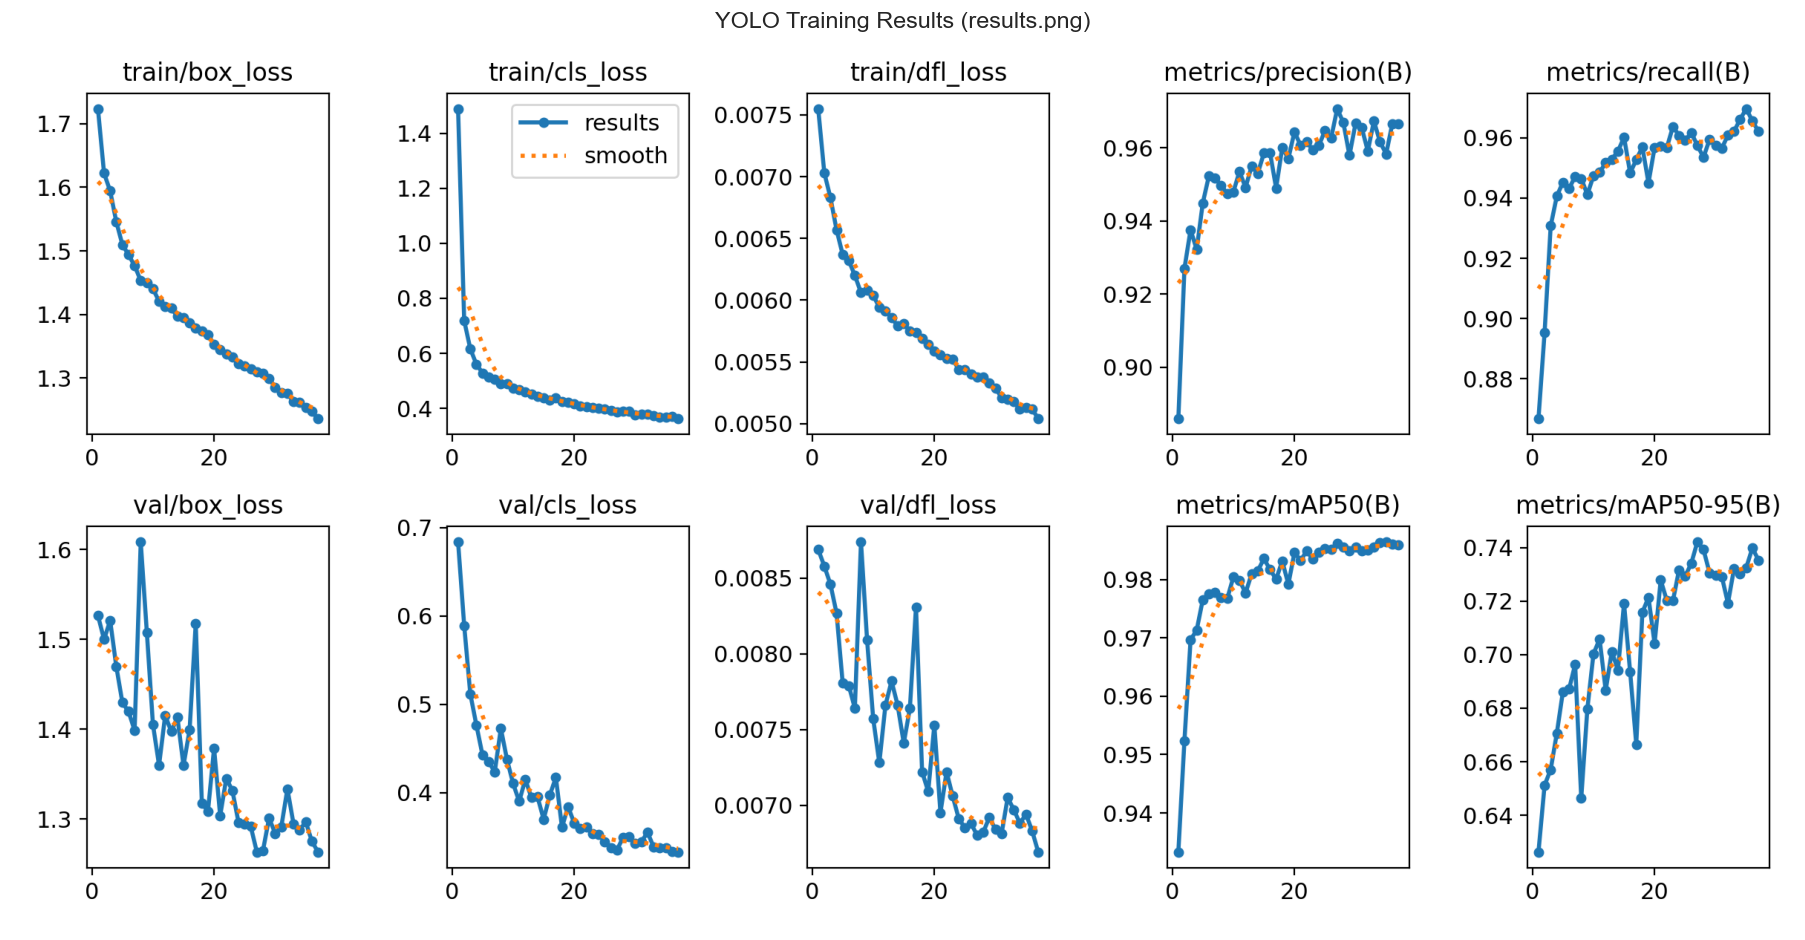

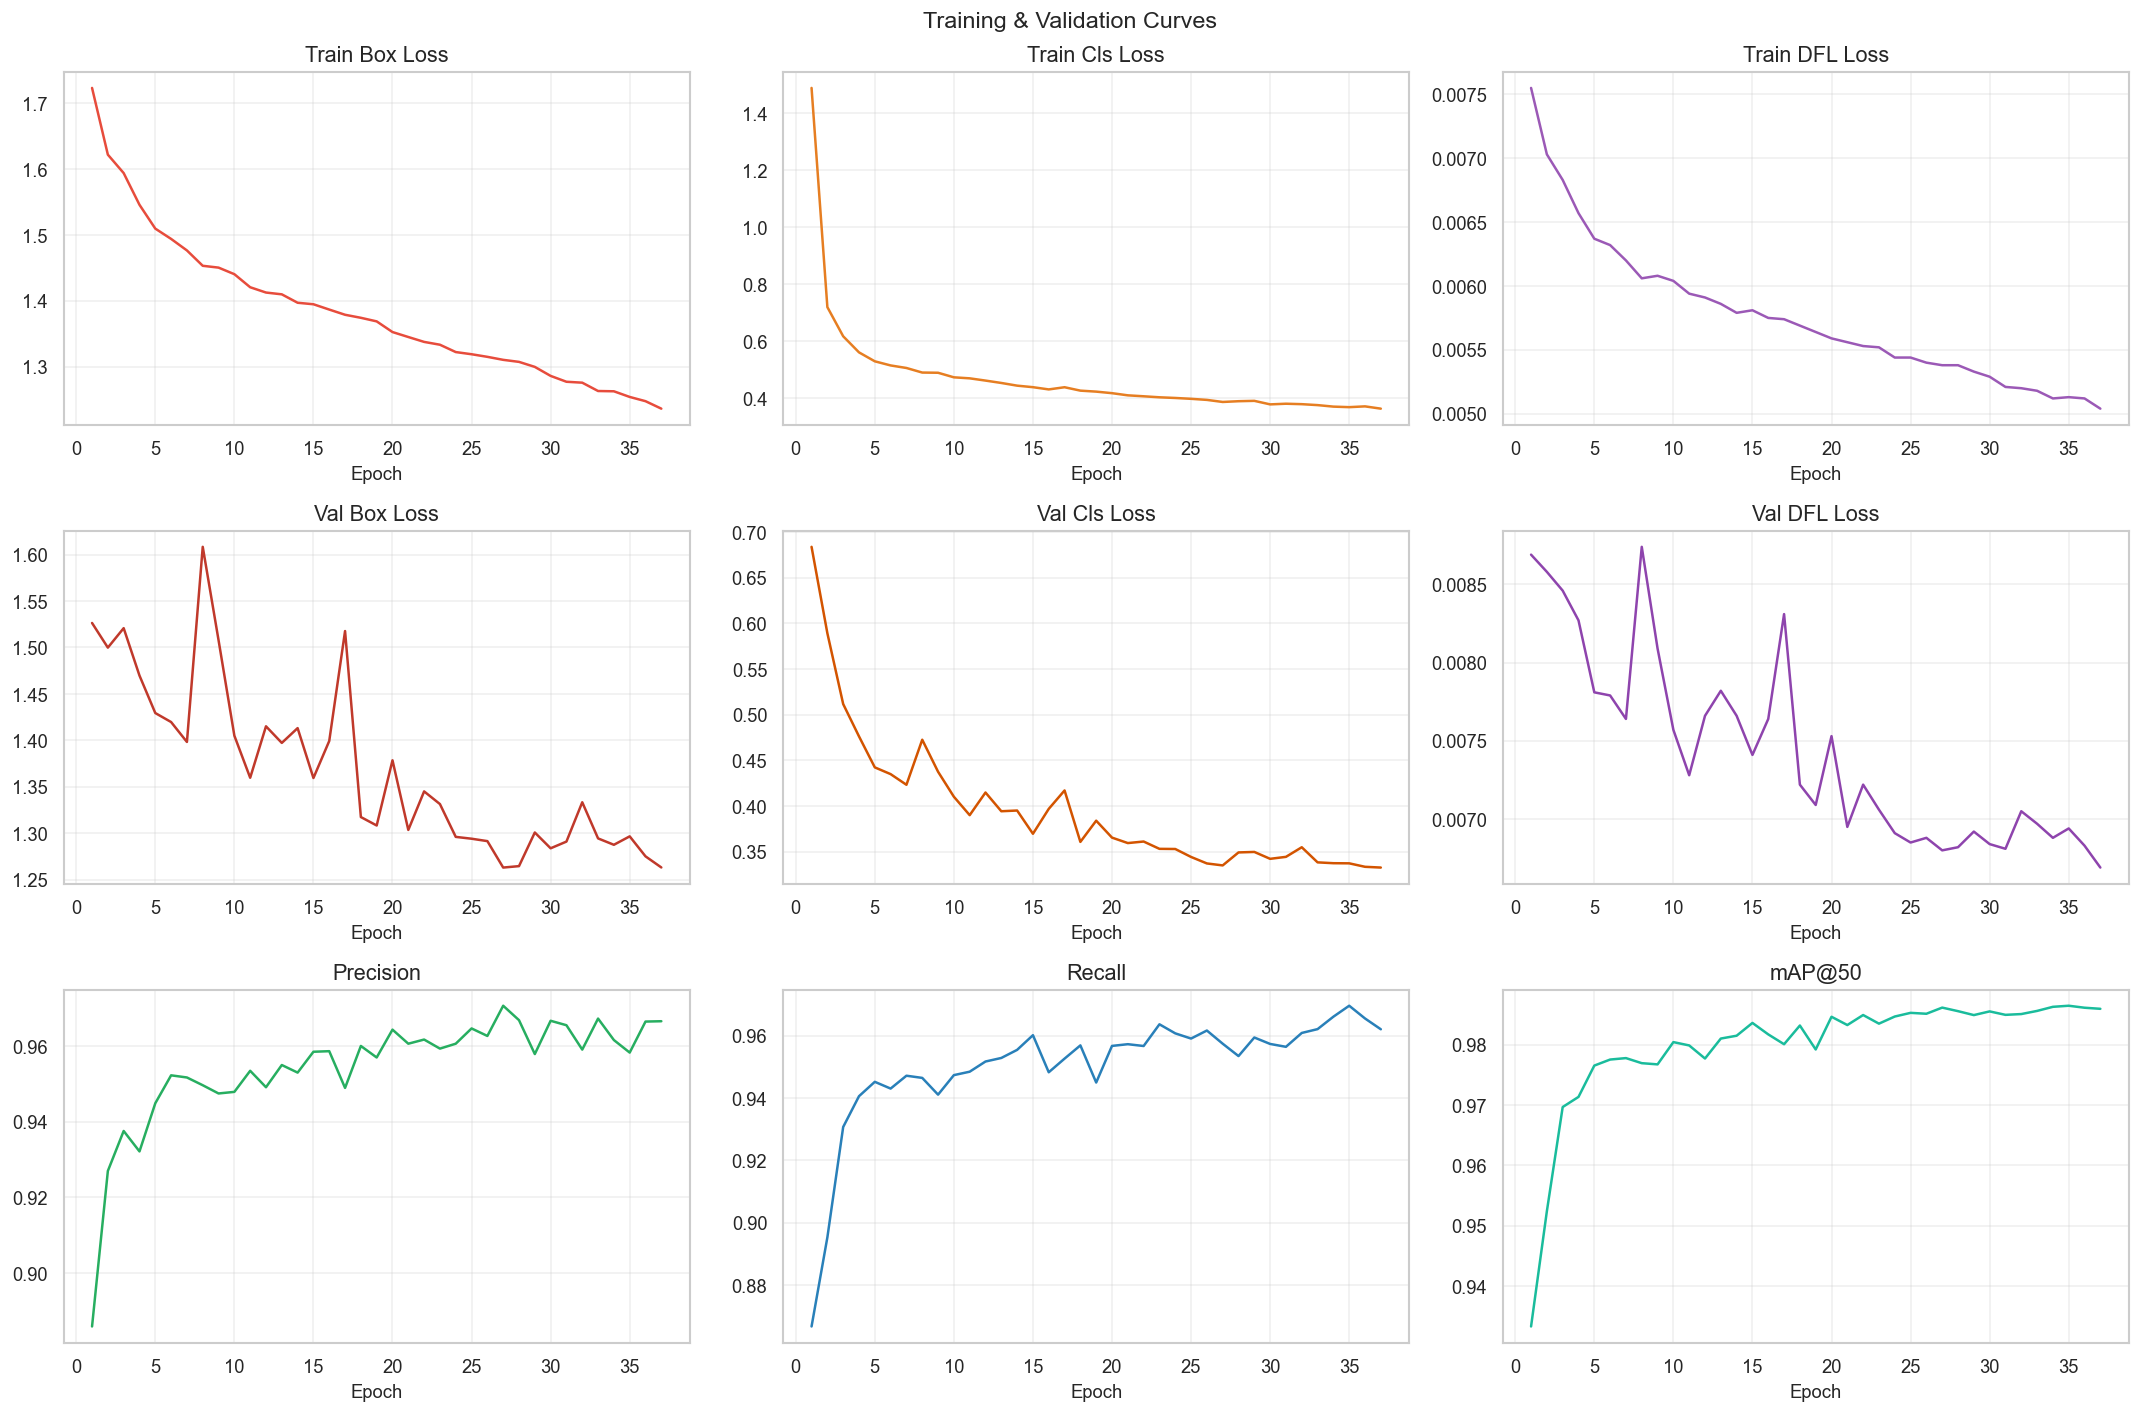

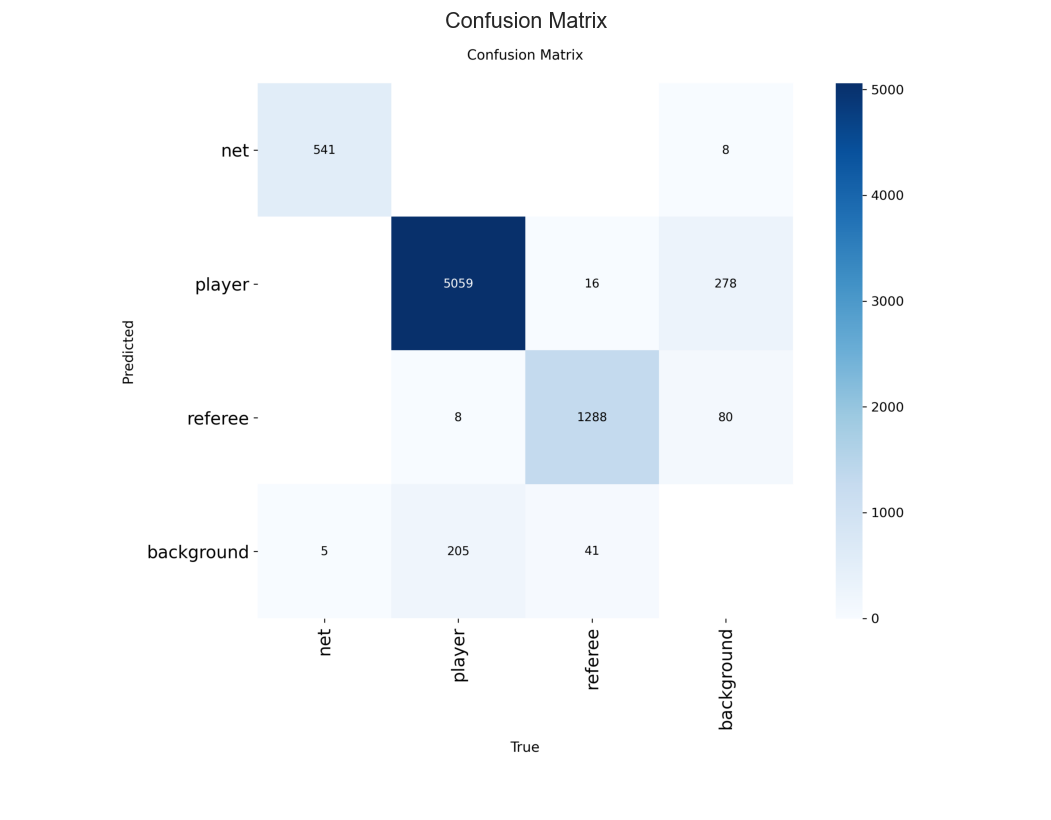

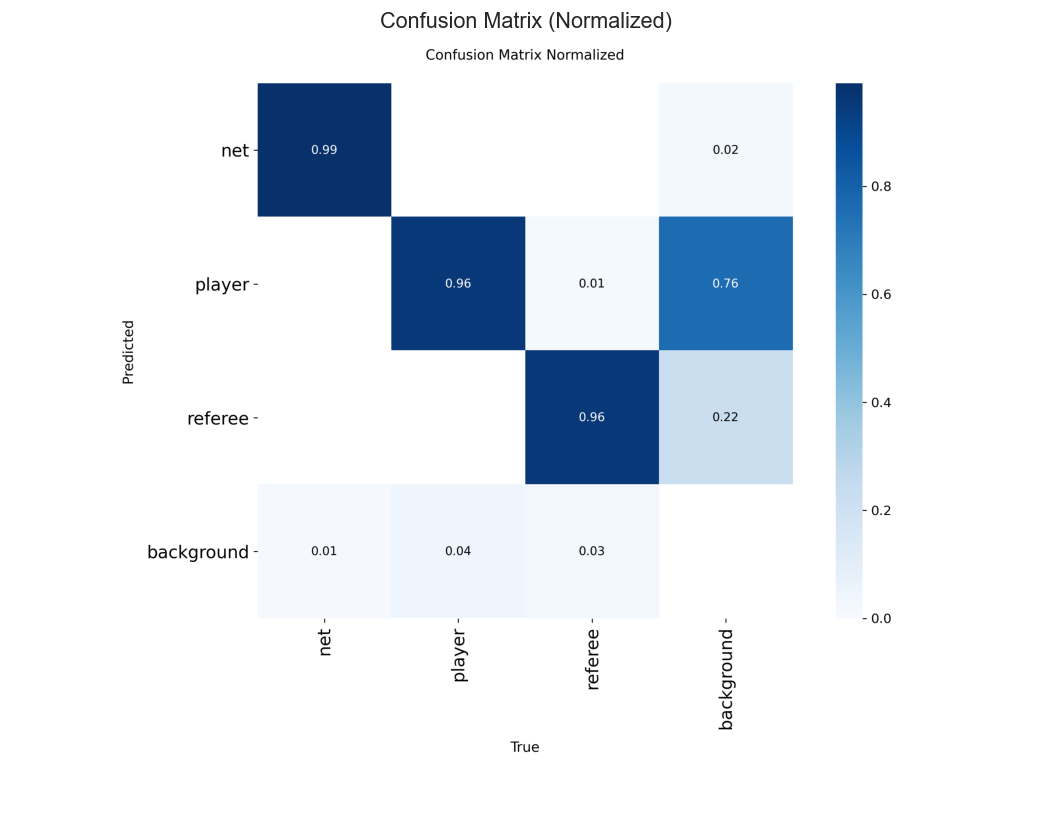

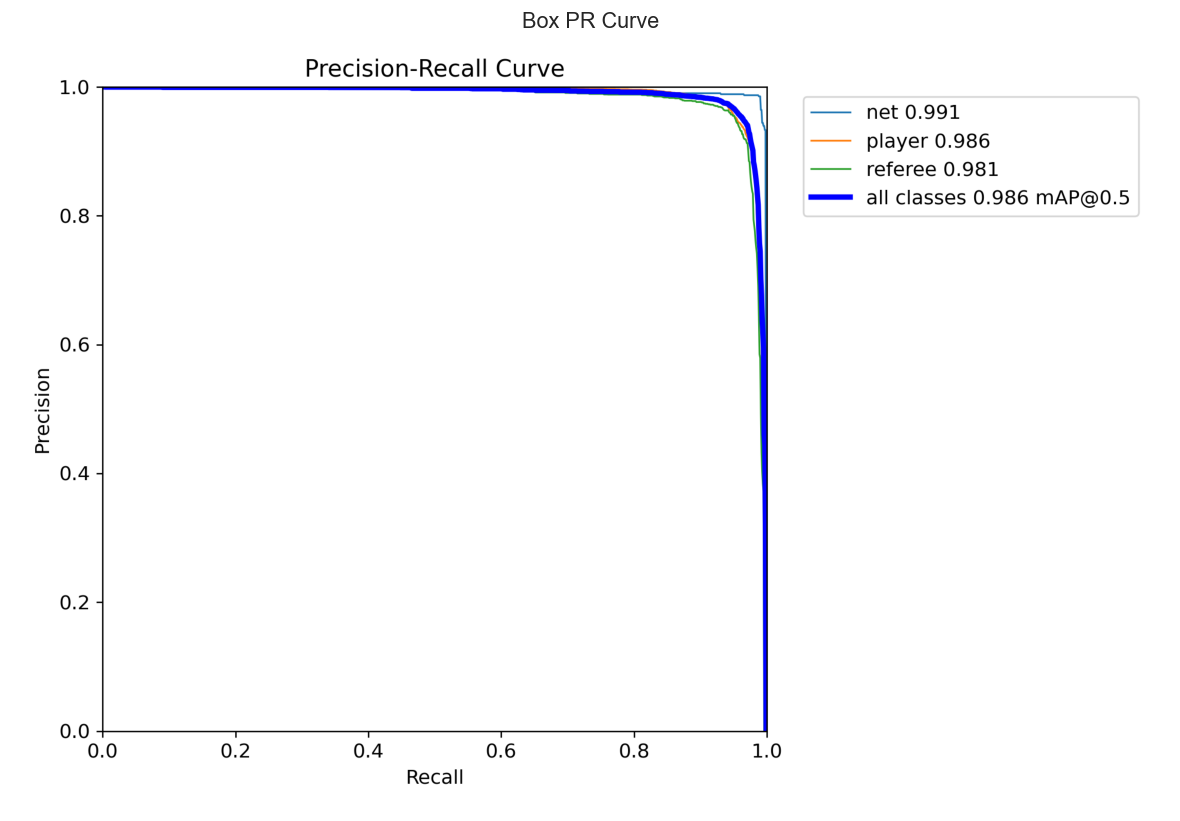

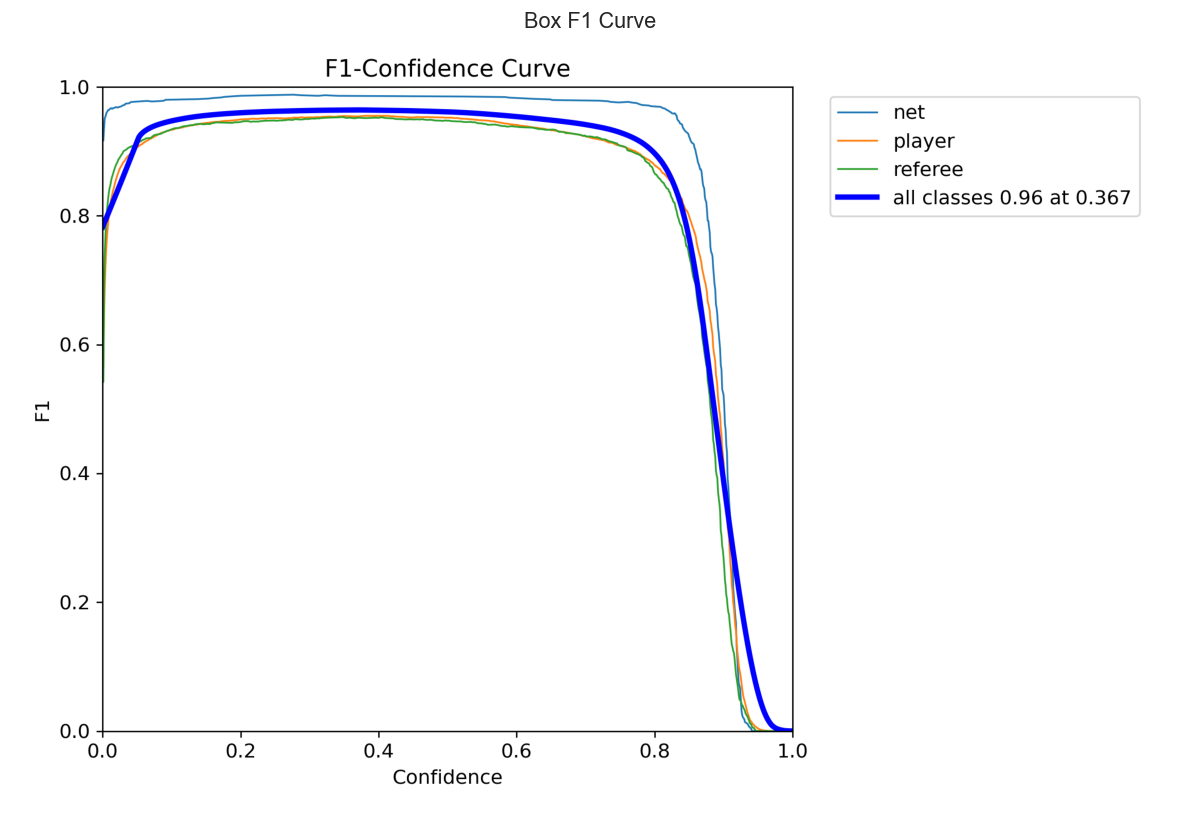

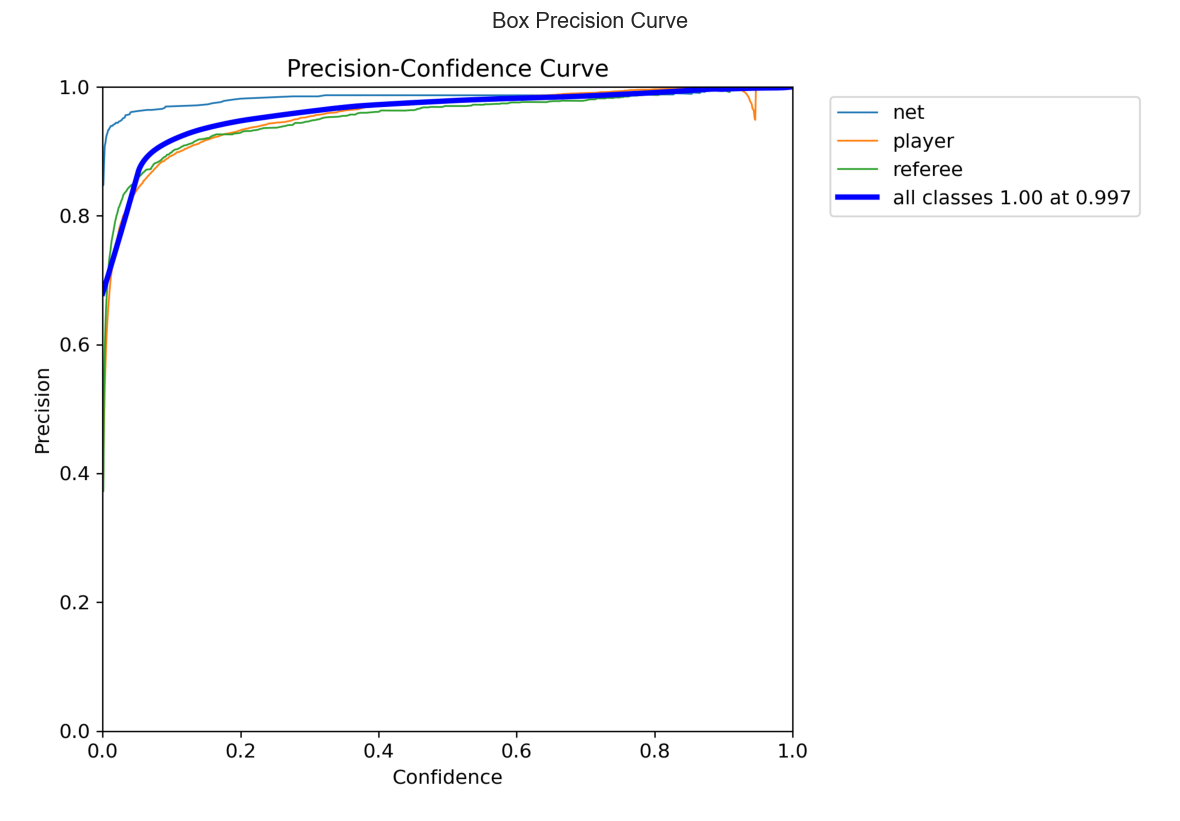

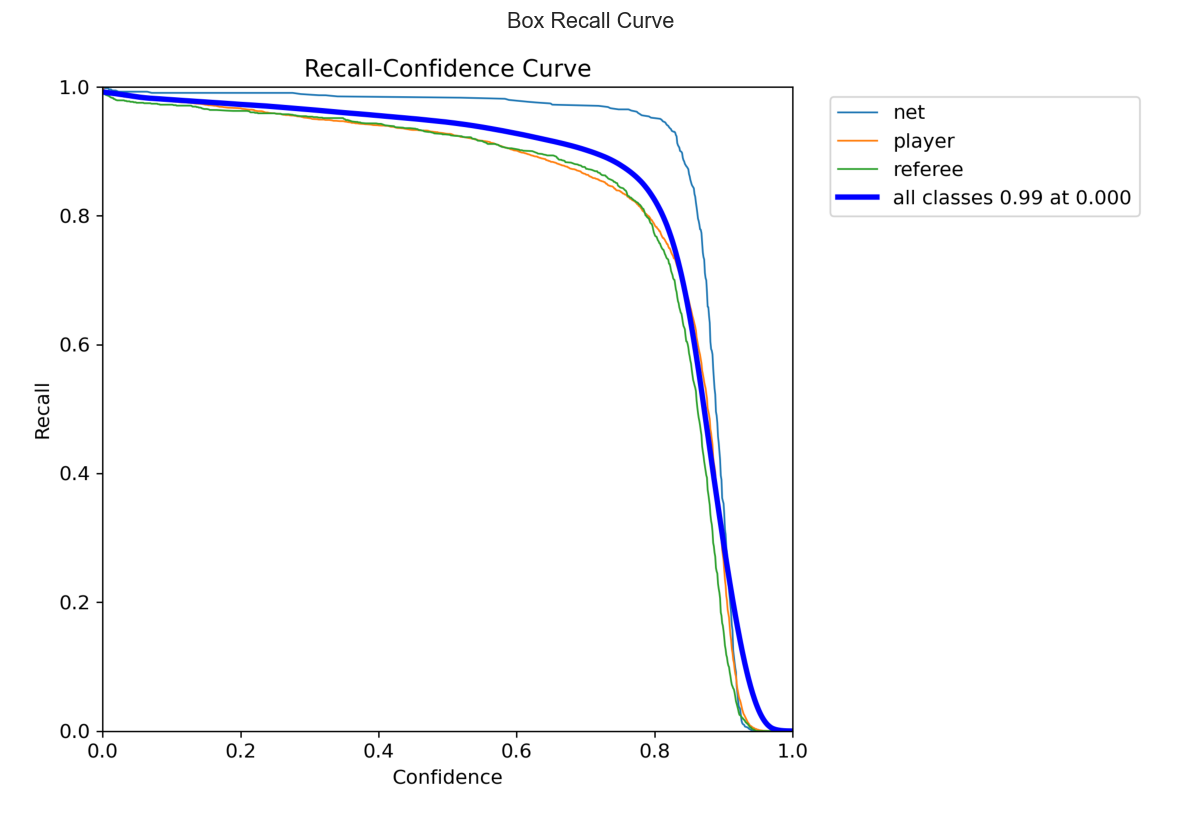

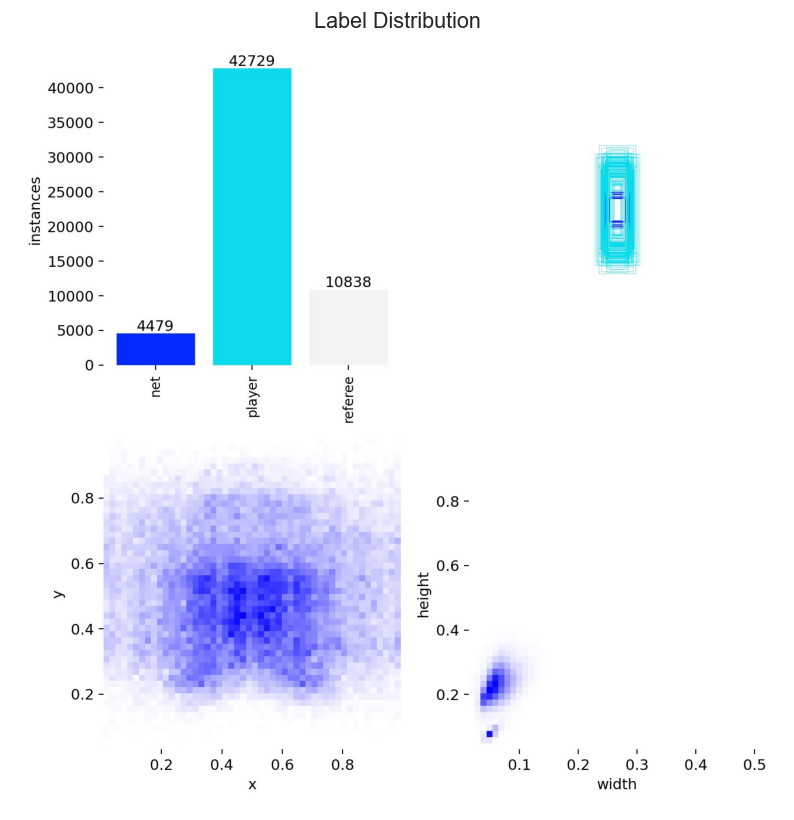

In [ ]:
# -- results.png (YOLO native) ----------------------------------
_rp = plot_files.get('results.png')
if _rp and Path(_rp).exists():
    fig, ax = plt.subplots(figsize=(16, 8))
    ax.imshow(mpimg.imread(str(_rp)))
    ax.set_title('YOLO Training Results (results.png)', fontsize=14, fontweight='bold')
    ax.axis('off'); plt.tight_layout(); plt.show()
else:
    logger.info('results.png not found -- will build from CSV below.')

# -- metrics_log.csv curves (also serves Task 5) ----------------
def _load_metrics_csv(csv_path):
    if csv_path is None or not Path(csv_path).exists():
        logger.warning('metrics CSV not found -- skipping.')
        return None
    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip()
    return df

def _render_curves(df, title='Training Curves', csv_path=None):
    if df is None or df.empty: return
    x = df['epoch'] if 'epoch' in df.columns else df.index
    fig, axes = plt.subplots(3, 3, figsize=(18, 12))
    fig.suptitle(title, fontsize=14, fontweight='bold')
    def sp(ax, col, t, color):
        if col in df.columns:
            ax.plot(x, df[col], color=color, linewidth=1.5)
            ax.set_title(t); ax.set_xlabel('Epoch'); ax.grid(True, alpha=0.3)
        else:
            ax.set_title(f'{t} (N/A)'); ax.axis('off')
    sp(axes[0,0], 'train/box_loss',       'Train Box Loss',  '#e74c3c')
    sp(axes[0,1], 'train/cls_loss',       'Train Cls Loss',  '#e67e22')
    sp(axes[0,2], 'train/dfl_loss',       'Train DFL Loss',  '#9b59b6')
    sp(axes[1,0], 'val/box_loss',         'Val Box Loss',    '#c0392b')
    sp(axes[1,1], 'val/cls_loss',         'Val Cls Loss',    '#d35400')
    sp(axes[1,2], 'val/dfl_loss',         'Val DFL Loss',    '#8e44ad')
    sp(axes[2,0], 'metrics/precision(B)', 'Precision',       '#27ae60')
    sp(axes[2,1], 'metrics/recall(B)',    'Recall',          '#2980b9')
    sp(axes[2,2], 'metrics/mAP50(B)',     'mAP@50',          '#1abc9c')
    plt.tight_layout()
    if csv_path:
        out = Path(csv_path).parent / 'training_curves_custom.png'
        plt.savefig(out, dpi=150); logger.info(f'Curves -> {out}')
    plt.show()

df_metrics = _load_metrics_csv(  results_csv_path or metrics_path )
_render_curves(df_metrics, 'Training & Validation Curves', metrics_path)

# -- 7.1-C Display all YOLO standard image outputs --------------------
_IMG_TITLES = {
    'confusion_matrix.png'           : 'Confusion Matrix',
    'confusion_matrix_normalized.png': 'Confusion Matrix (Normalized)',
    'BoxPR_curve.png'                : 'Box PR Curve',
    'BoxF1_curve.png'                : 'Box F1 Curve',
    'BoxP_curve.png'                 : 'Box Precision Curve',
    'BoxR_curve.png'                 : 'Box Recall Curve',
    'labels.jpg'                     : 'Label Distribution',
    'PR_curve.png'                   : 'PR Curve',
    'F1_curve.png'                   : 'F1 Curve',
}
for _pname, _title in _IMG_TITLES.items():
    _path = plot_files.get(_pname)
    if _path and Path(_path).exists():
        fig, ax = plt.subplots(figsize=(10, 7))
        ax.imshow(mpimg.imread(str(_path)))
        ax.set_title(_title, fontsize=13, fontweight='bold')
        ax.axis('off'); plt.tight_layout(); plt.show()
    else:
        logger.info(f'{_title} ({_pname}): not found.')

### 8.3 · Model evaluation on the test set

In [ ]:
def run_yolo_evaluation(weights_path, data_yaml, split='test'):
    if weights_path is None or not Path(weights_path).exists():
        logger.warning(f'Weights not found at {weights_path} -- skipping {split} eval.')
        return None, None
    logger.info(f'Running YOLO evaluation on split={split} ...')
    val_model   = YOLO(str(weights_path))
    val_results = val_model.val(
        data=str(data_yaml),
        split=split,
        imgsz=HYPERPARAMS['imgsz'],
        device=HYPERPARAMS['device'],
        plots=True,
        save_json=False,
        verbose=True,
    )
    box = val_results.box
    f1_global = 2 * box.mp * box.mr / (box.mp + box.mr + 1e-9)
    agg = {
        'split'    : split,
        'Precision': float(box.mp),
        'Recall'   : float(box.mr),
        'mAP50'    : float(box.map50),
        'mAP50-95' : float(box.map),
        'F1'       : float(f1_global),
    }
    # Per-class metrics
    per_class = {}
    names = val_results.names
    if hasattr(box, 'ap_class_index'):
        for i, cls_idx in enumerate(box.ap_class_index):
            cls_name = names.get(int(cls_idx), f'cls_{cls_idx}')
            p   = float(box.p[i])    if hasattr(box,'p')    else float('nan')
            r   = float(box.r[i])    if hasattr(box,'r')    else float('nan')
            m50 = float(box.ap50[i]) if hasattr(box,'ap50') else float('nan')
            m   = float(box.ap[i])   if hasattr(box,'ap')   else float('nan')
            per_class[cls_name] = {'Precision':p,'Recall':r,'mAP50':m50,'mAP50-95':m,'F1':2*p*r/(p+r+1e-9)}
    logger.info(f'[{split}] P={agg["Precision"]:.4f}  R={agg["Recall"]:.4f}  '
                f'mAP50={agg["mAP50"]:.4f}  mAP50-95={agg["mAP50-95"]:.4f}  F1={agg["F1"]:.4f}')
    return agg, per_class

# Run on TEST split
test_agg, test_per_class = run_yolo_evaluation(best_weights, data_yaml_path, split='test')

# Run on VAL split (for comparison)
val_agg, val_per_class   = run_yolo_evaluation(best_weights, data_yaml_path, split='val')
val_metrics = val_agg or {}

Ultralytics 8.4.60 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 122 layers, 9,466,341 parameters, 0 gradients, 20.5 GFLOPs
val: Fast image access ✅ (ping: 0.6±0.2 ms, read: 77.9±16.2 MB/s, size: 214.0 KB)
val: Scanning /content/drive/.shortcut-targets-by-id/1jblZrI00CBpsLdpQ4DTvH_ptH5p9Md2H/DeepLearningProject/datasets/pla_ref_bal_net_6870.yolo26/test/labels.cache... 661 images, 42 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 661/661 213.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 42/42 3.0it/s 13.9s
                   all        661       7229      0.959      0.957      0.984      0.741
                   net        566        566      0.988      0.993      0.991      0.773
                player        619       5319      0.955      0.931      0.981      0.731
               referee        606       1344      0.935      0.948      0.979      0.721
Speed: 1.4ms preproce

### 8.4 · Saving evaluation results (in 2 separate .json files)

In [ ]:
def _save_metrics_json(agg_dict, per_class_dict, out_path, run_name):
    if agg_dict is None:
        logger.warning(f'No metrics to save for {run_name}.'); return
    payload = {**agg_dict, 'run_name': run_name,
               'timestamp': datetime.datetime.utcnow().isoformat()}
    if per_class_dict:
        payload['per_class'] = per_class_dict
    out_path.parent.mkdir(parents=True, exist_ok=True)
    with open(out_path, 'w') as f:
        json.dump(payload, f, indent=2)
    print(f'Saved -> {out_path}')
    print(json.dumps(payload, indent=2))

_test_json_path = Path("/content/drive/MyDrive/DeepLearningProject/") / PROJECT / NAME/ "completed/test_metrics.json"
_eval_json_path = Path("/content/drive/MyDrive/DeepLearningProject/") / PROJECT / NAME/ "completed/eval_metrics.json"
_save_metrics_json(test_agg, test_per_class, _test_json_path, V2_RUN_NAME + '_test')

metrics_json_path.parent.mkdir(parents=True, exist_ok=True)
if val_agg:
    _save_metrics_json(val_agg, val_per_class, _eval_json_path, V2_RUN_NAME)
resolved_json_v2 = metrics_json_path

Saved -> /content/drive/MyDrive/DeepLearningProject/yolo_npr/train_v1/completed/test_metrics.json
{
  "split": "test",
  "Precision": 0.9590832852772803,
  "Recall": 0.9574820821173318,
  "mAP50": 0.9835765636513568,
  "mAP50-95": 0.7414963620315141,
  "F1": 0.958282014331114,
  "run_name": "train_v1_test",
  "timestamp": "2026-06-03T12:29:54.319728",
  "per_class": {
    "net": {
      "Precision": 0.9877003861725857,
      "Recall": 0.9931515010991284,
      "mAP50": 0.9906623331992316,
      "mAP50-95": 0.7730958003572237,
      "F1": 0.9904184426624196
    },
    "player": {
      "Precision": 0.9550364003556782,
      "Recall": 0.9313780785862004,
      "mAP50": 0.9809185030877958,
      "mAP50-95": 0.7308850220276569,
      "F1": 0.9430588844616574
    },
    "referee": {
      "Precision": 0.9345130693035771,
      "Recall": 0.9479166666666666,
      "mAP50": 0.9791488546670428,
      "mAP50-95": 0.7205082637096617,
      "F1": 0.9411671481947963
    }
  }
}
Saved -> /content/dr

### 8.5 · Comparing results obtained between validation and testing


  TRAIN/VAL (last epoch)  vs  VAL (best.pt)  vs  TEST (best.pt)
                Precision  Recall   mAP50  mAP50-95      F1
Val@last-epoch     0.9666  0.9621  0.9860    0.7353     NaN
Val@best-pt        0.9628  0.9491  0.9833    0.7368  0.9559
Test@best-pt       0.9591  0.9575  0.9836    0.7415  0.9583


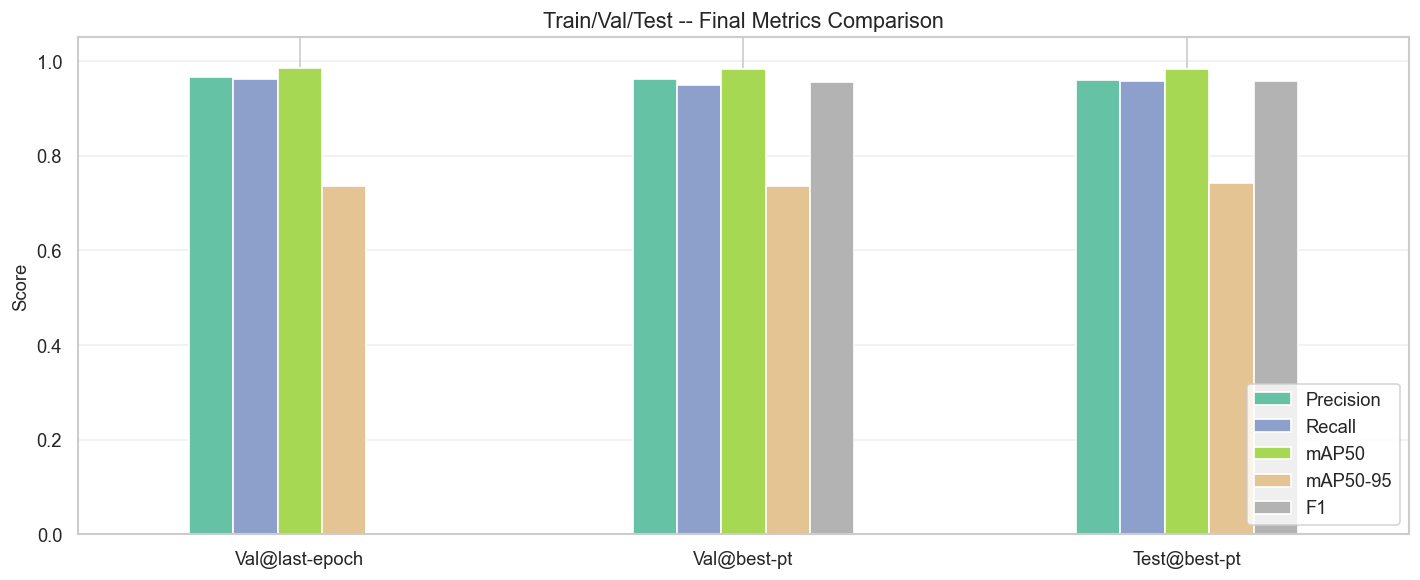

In [ ]:
def compare_train_test(df_train_csv, val_agg_dict, test_agg_dict):
    print('\n' + '='*70)
    print('  TRAIN/VAL (last epoch)  vs  VAL (best.pt)  vs  TEST (best.pt)')
    print('='*70)
    rows = {}
    # Last epoch from training CSV
    if df_train_csv is not None and not df_train_csv.empty:
        last = df_train_csv.iloc[-1]
        rows['Val@last-epoch'] = {
            'Precision' : last.get('metrics/precision(B)', float('nan')),
            'Recall'    : last.get('metrics/recall(B)',    float('nan')),
            'mAP50'     : last.get('metrics/mAP50(B)',     float('nan')),
            'mAP50-95'  : last.get('metrics/mAP50-95(B)',  float('nan')),
            'F1'        : float('nan'),
        }
    if val_agg_dict:
        rows['Val@best-pt'] = {k: val_agg_dict.get(k, float('nan'))
                                for k in ['Precision','Recall','mAP50','mAP50-95','F1']}
    if test_agg_dict:
        rows['Test@best-pt'] = {k: test_agg_dict.get(k, float('nan'))
                                 for k in ['Precision','Recall','mAP50','mAP50-95','F1']}
    df_cmp = pd.DataFrame(rows).T
    print(df_cmp.round(4).to_string())
    ax = df_cmp.astype(float).plot(
        kind='bar', figsize=(12, 5), rot=0,
        title='Train/Val/Test -- Final Metrics Comparison', colormap='Set2'
    )
    ax.set_ylabel('Score'); ax.set_ylim(0, 1.05)
    ax.legend(loc='lower right'); ax.grid(axis='y', alpha=0.3)
    plt.tight_layout(); plt.show()
    return df_cmp

df_comparison = compare_train_test(df_metrics, val_agg, test_agg)

### 8.6 Results analysis divided by class


  Per-Class Metrics -- TEST
Class            Precision   Recall    mAP50   mAP50-95       F1
----------------------------------------------------------------------
net                 0.9877   0.9932   0.9907     0.7731   0.9904
player              0.9550   0.9314   0.9809     0.7309   0.9431
referee <<          0.9345   0.9479   0.9791     0.7205   0.9412


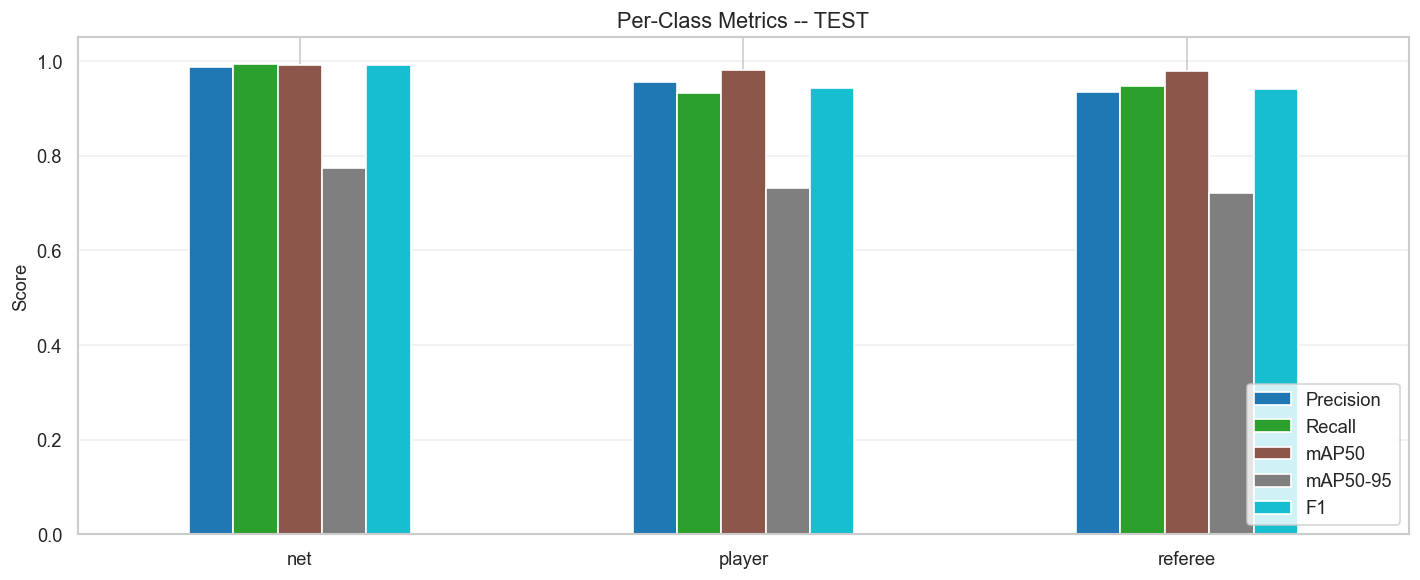


────────────────────────────────────────
  REFEREE CLASS ANALYSIS (test)
────────────────────────────────────────
  Precision   : 0.9345
  Recall      : 0.9479
  mAP50       : 0.9791
  mAP50-95    : 0.7205
  F1          : 0.9412


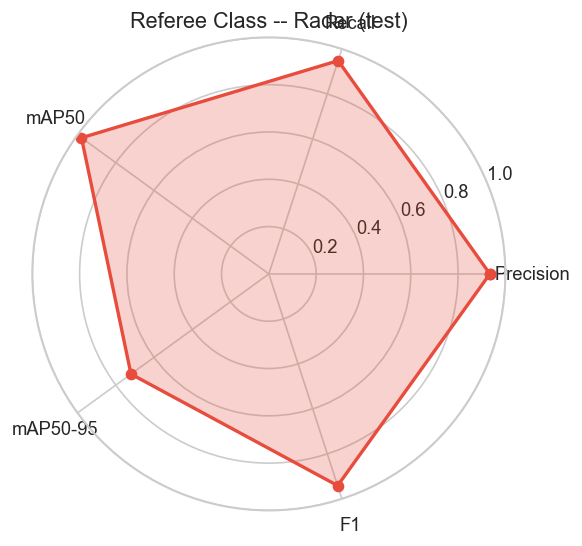


  Per-Class Metrics -- VAL
Class            Precision   Recall    mAP50   mAP50-95       F1
----------------------------------------------------------------------
net                 0.9871   0.9832   0.9902     0.7589   0.9852
player              0.9578   0.9303   0.9834     0.7358   0.9439
referee <<          0.9435   0.9338   0.9764     0.7156   0.9386


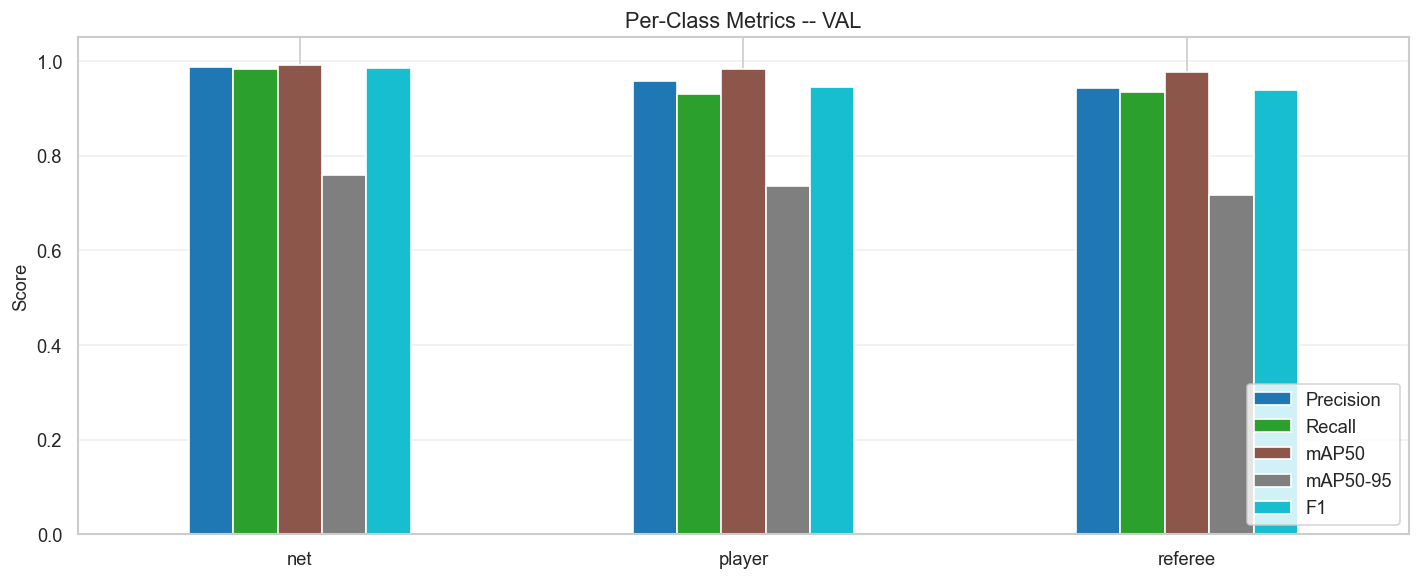


────────────────────────────────────────
  REFEREE CLASS ANALYSIS (val)
────────────────────────────────────────
  Precision   : 0.9435
  Recall      : 0.9338
  mAP50       : 0.9764
  mAP50-95    : 0.7156
  F1          : 0.9386


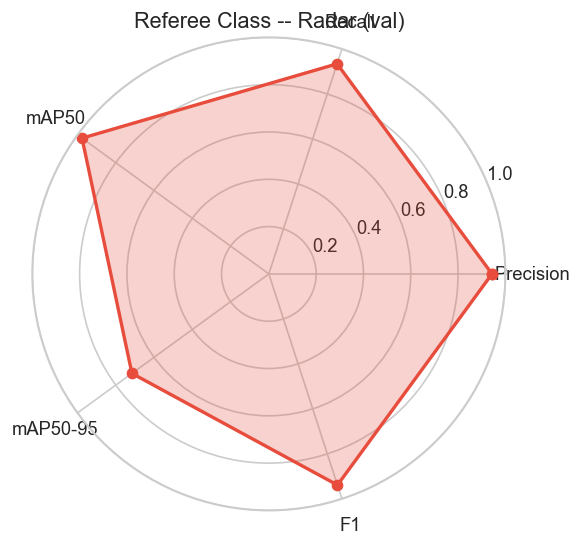

In [ ]:
REFEREE_CLASS = 'referee'   # special focus

def display_per_class_metrics(per_class_dict, split='test'):
    if not per_class_dict:
        logger.warning(f'No per-class metrics for split={split}.'); return
    print(f'\n{"="*70}')
    print(f'  Per-Class Metrics -- {split.upper()}')
    print(f'{"="*70}')
    print(f'{"Class":15s} {"Precision":>10s} {"Recall":>8s} {"mAP50":>8s} {"mAP50-95":>10s} {"F1":>8s}')
    print('-' * 70)
    for cls_name, m in per_class_dict.items():
        flag = ' <<' if cls_name == REFEREE_CLASS else ''
        print(f'{cls_name+flag:15s} {m["Precision"]:10.4f} {m["Recall"]:8.4f} '
              f'{m["mAP50"]:8.4f} {m["mAP50-95"]:10.4f} {m["F1"]:8.4f}')

    # Bar chart
    df_pc = pd.DataFrame(per_class_dict).T[['Precision','Recall','mAP50','mAP50-95','F1']]
    ax = df_pc.plot(kind='bar', figsize=(12, 5), rot=0, colormap='tab10',
                    title=f'Per-Class Metrics -- {split.upper()}')
    ax.set_ylabel('Score'); ax.set_ylim(0, 1.05)
    ax.legend(loc='lower right'); ax.grid(axis='y', alpha=0.3)
    plt.tight_layout(); plt.show()

    # Referee special analysis
    if REFEREE_CLASS in per_class_dict:
        ref = per_class_dict[REFEREE_CLASS]
        print(f'\n{"─"*40}')
        print(f'  REFEREE CLASS ANALYSIS ({split})')
        print(f'{"─"*40}')
        for k, v in ref.items():
            warn = '  << low' if (k=='Recall' and v<0.85) or (k=='Precision' and v<0.80) else ''
            print(f'  {k:12s}: {v:.4f}{warn}')
        # Radar chart
        cats   = list(ref.keys())
        vals   = [ref[c] for c in cats]
        N      = len(cats)
        angles = [n / float(N) * 2 * np.pi for n in range(N)]
        angles += angles[:1]; vals += vals[:1]
        fig, ax = plt.subplots(figsize=(5, 5), subplot_kw=dict(polar=True))
        ax.plot(angles, vals, 'o-', linewidth=2, color='#e74c3c')
        ax.fill(angles, vals, alpha=0.25, color='#e74c3c')
        ax.set_xticks(angles[:-1]); ax.set_xticklabels(cats)
        ax.set_ylim(0, 1)
        ax.set_title(f'Referee Class -- Radar ({split})', fontweight='bold')
        plt.tight_layout(); plt.show()

display_per_class_metrics(test_per_class, split='test')
display_per_class_metrics(val_per_class,  split='val')

## 9 · Analysis between different versions

### 9.1 · Loading .json files with the metric values ​​obtained from all trained models

In [ ]:
sns.set_theme(style='whitegrid', font_scale=1.1)

# ── Config ────────────────────────────────────────────────────────────────────
BASE_DIR = Path("/content/drive/MyDrive/DeepLearningProject/") / PROJECT
OUTPUT_DIR = BASE_DIR / "results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ── Discover all train_v* folders ─────────────────────────────────────────────
pattern = str(BASE_DIR / "train_v*" / "completed" / "test_metrics.json")
found_paths = sorted(glob.glob(pattern))

if not found_paths:
    raise FileNotFoundError(
        f"No test_metrics.json files found matching:\n  {pattern}\n"
        "Check that PROJECT is set correctly and the drive is mounted."
    )

print(f"✅ Found {len(found_paths)} model(s):")
for p in found_paths:
    print(f"   • {Path(p).parts[-3]}")   # prints e.g. train_v1, train_v2 …

# ── Parse each JSON into flat dicts ───────────────────────────────────────────
def parse_metrics_json(path: Path) -> tuple[dict, dict]:
    """
    Returns:
      model_row  – one dict of model-level metrics (for df_all)
      class_rows – list of per-class dicts (for df_class)
    """
    with open(path) as f:
        data = json.load(f)

    name = path.parts[-3]   # e.g. "train_v3"

    # ── Model-level ──────────────────────────────────────────────────────────
    # Adjust the key names below to match your actual JSON schema
    model_row = {"model": name}
    for key in ("mAP50-95", "mAP50", "Precision", "Recall", "F1",
                "FPS", "latency_ms", "params_M", "GFLOPs", "file_size_MB",
                "Size"):
        model_row[key] = data.get(key, np.nan)

    # ── Per-class ────────────────────────────────────────────────────────────
    class_rows = []
    per_class = data.get("per_class", {})
    for cls_name, mvals in per_class.items():
        row = {"model": name, "class": cls_name}
        row.update(mvals)
        class_rows.append(row)

    return model_row, class_rows

# ── Build dataframes ──────────────────────────────────────────────────────────
all_model_rows  = []
all_class_rows  = []

for p in found_paths:
    m_row, c_rows = parse_metrics_json(Path(p))
    all_model_rows.append(m_row)
    all_class_rows.extend(c_rows)

df_all   = pd.DataFrame(all_model_rows)
df_class = pd.DataFrame(all_class_rows) if all_class_rows else pd.DataFrame()

# ── Save ──────────────────────────────────────────────────────────────────────
df_all.to_csv(OUTPUT_DIR / "all_metrics.csv",   index=False)
df_class.to_csv(OUTPUT_DIR / "class_metrics.csv", index=False)

print("\nMODEL-LEVEL METRICS")
NUMERIC_METRICS = [c for c in
    ['mAP50-95','mAP50','Precision','Recall','F1']
    if c in df_all.columns]

print(tabulate(df_all[['model'] + NUMERIC_METRICS],
               headers='keys', tablefmt='rounded_outline',
               floatfmt='.4f', showindex=False))

if not df_class.empty:
    print("\nPER-CLASS METRICS")
    print(tabulate(df_class, headers='keys', tablefmt='rounded_outline',
                   floatfmt='.4f', showindex=False))

print(f"\nSaved → {OUTPUT_DIR / 'all_metrics.csv'}")
print(f"Saved → {OUTPUT_DIR / 'class_metrics.csv'}")

✅ Found 5 model(s):
   • train_v1
   • train_v2
   • train_v3
   • train_v4
   • train_v5

📋 MODEL-LEVEL METRICS
╭──────────┬────────────┬─────────┬─────────────┬──────────┬────────╮
│ model    │   mAP50-95 │   mAP50 │   Precision │   Recall │     F1 │
├──────────┼────────────┼─────────┼─────────────┼──────────┼────────┤
│ train_v1 │     0.7415 │  0.9836 │      0.9591 │   0.9575 │ 0.9583 │
│ train_v2 │     0.7537 │  0.9874 │      0.9665 │   0.9719 │ 0.9692 │
│ train_v3 │     0.7672 │  0.9885 │      0.9721 │   0.9754 │ 0.9738 │
│ train_v4 │     0.7640 │  0.9871 │      0.9729 │   0.9741 │ 0.9735 │
│ train_v5 │     0.7481 │  0.9736 │      0.9445 │   0.9592 │ 0.9518 │
╰──────────┴────────────┴─────────┴─────────────┴──────────┴────────╯

📋 PER-CLASS METRICS
╭──────────┬─────────┬─────────────┬──────────┬─────────┬────────────┬────────╮
│ model    │ class   │   Precision │   Recall │   mAP50 │   mAP50-95 │     F1 │
├──────────┼─────────┼─────────────┼──────────┼─────────┼────────────┼──────

### 9.2 · Final Benchmark Report

In [ ]:
print("=" * 70)
print("  FINAL BENCHMARK REPORT")
print("=" * 70)

essential = ["mAP50-95", 'mAP50', 'Precision', 'Recall']


e_cols = [m for m in essential if m in df_all.columns]


print("\n── METRICS ─────────────────────────────────────────")
print(tabulate(df_all[['model'] + e_cols],
               headers='keys', tablefmt='rounded_outline',
               floatfmt='.4f', showindex=False))

# ── Best model per metric ─────────────────────────────────────────────────────
print("\n── BEST MODEL PER METRIC ─────────────────────────────────────")
higher_better = {"mAP50-95", 'mAP50', 'Precision', 'Recall', 'F1'}
best_rows = []

for m in e_cols:
    col = df_all[m].dropna()
    if col.empty:
        continue
    else:
        best_idx  = col.idxmax()
        direction = "↑ higher is better"
    best_rows.append([
        m, direction,
        df_all.loc[best_idx, 'model'],
        round(df_all.loc[best_idx, m], 4)
    ])

print(tabulate(best_rows,
               headers=['Metric', 'Direction', 'Best Model', 'Value'],
               tablefmt='rounded_outline'))

# ── Best model per class ──────────────────────────────────────────────────────
print("\n── BEST MODEL PER CLASS ──────────────────────────────────────")
if not df_class.empty:
    class_metrics     = ['Precision', 'Recall', 'mAP50', "mAP50-95", 'F1']
    available_metrics = [m for m in class_metrics if m in df_class.columns]

    if available_metrics:
        for cls in df_class['class'].unique():
            print(f"\n Class: {cls}")
            cls_data       = df_class[df_class['class'] == cls]
            best_class_rows = []

            for metric in available_metrics:
                valid = cls_data.dropna(subset=[metric])
                if not valid.empty:
                    best_idx = valid[metric].idxmax()   # all class metrics ↑
                    best_class_rows.append([
                        metric,
                        valid.loc[best_idx, 'model'],
                        round(valid.loc[best_idx, metric], 4)
                    ])

            if best_class_rows:
                print(tabulate(best_class_rows,
                               headers=['Metric (↑)', 'Best Model', 'Value'],
                               tablefmt='rounded_outline'))
            else:
                print(f"   No valid metric data for {cls}.")
    else:
        print("Expected metrics not found in per-class data.")
else:
    print("No per-class data available.")

print(f"\nAll outputs saved in: {OUTPUT_DIR.resolve()}")
print("   Files:")
for f in sorted(OUTPUT_DIR.glob("*.csv")) + sorted(OUTPUT_DIR.glob("*.png")):
    print(f"   • {f.name}")

  📋 FINAL BENCHMARK REPORT

── METRICS ─────────────────────────────────────────
╭──────────┬────────────┬─────────┬─────────────┬──────────╮
│ model    │   mAP50-95 │   mAP50 │   Precision │   Recall │
├──────────┼────────────┼─────────┼─────────────┼──────────┤
│ train_v1 │     0.7415 │  0.9836 │      0.9591 │   0.9575 │
│ train_v2 │     0.7537 │  0.9874 │      0.9665 │   0.9719 │
│ train_v3 │     0.7672 │  0.9885 │      0.9721 │   0.9754 │
│ train_v4 │     0.7640 │  0.9871 │      0.9729 │   0.9741 │
│ train_v5 │     0.7481 │  0.9736 │      0.9445 │   0.9592 │
╰──────────┴────────────┴─────────┴─────────────┴──────────╯

── BEST MODEL PER METRIC ─────────────────────────────────────
╭───────────┬────────────────────┬──────────────┬─────────╮
│ Metric    │ Direction          │ Best Model   │   Value │
├───────────┼────────────────────┼──────────────┼─────────┤
│ mAP50-95  │ ↑ higher is better │ train_v3     │  0.7672 │
│ mAP50     │ ↑ higher is better │ train_v3     │  0.9885 │
│ Prec

### 9.3 · Results visualization

#### 9.3.1 · Bar charts

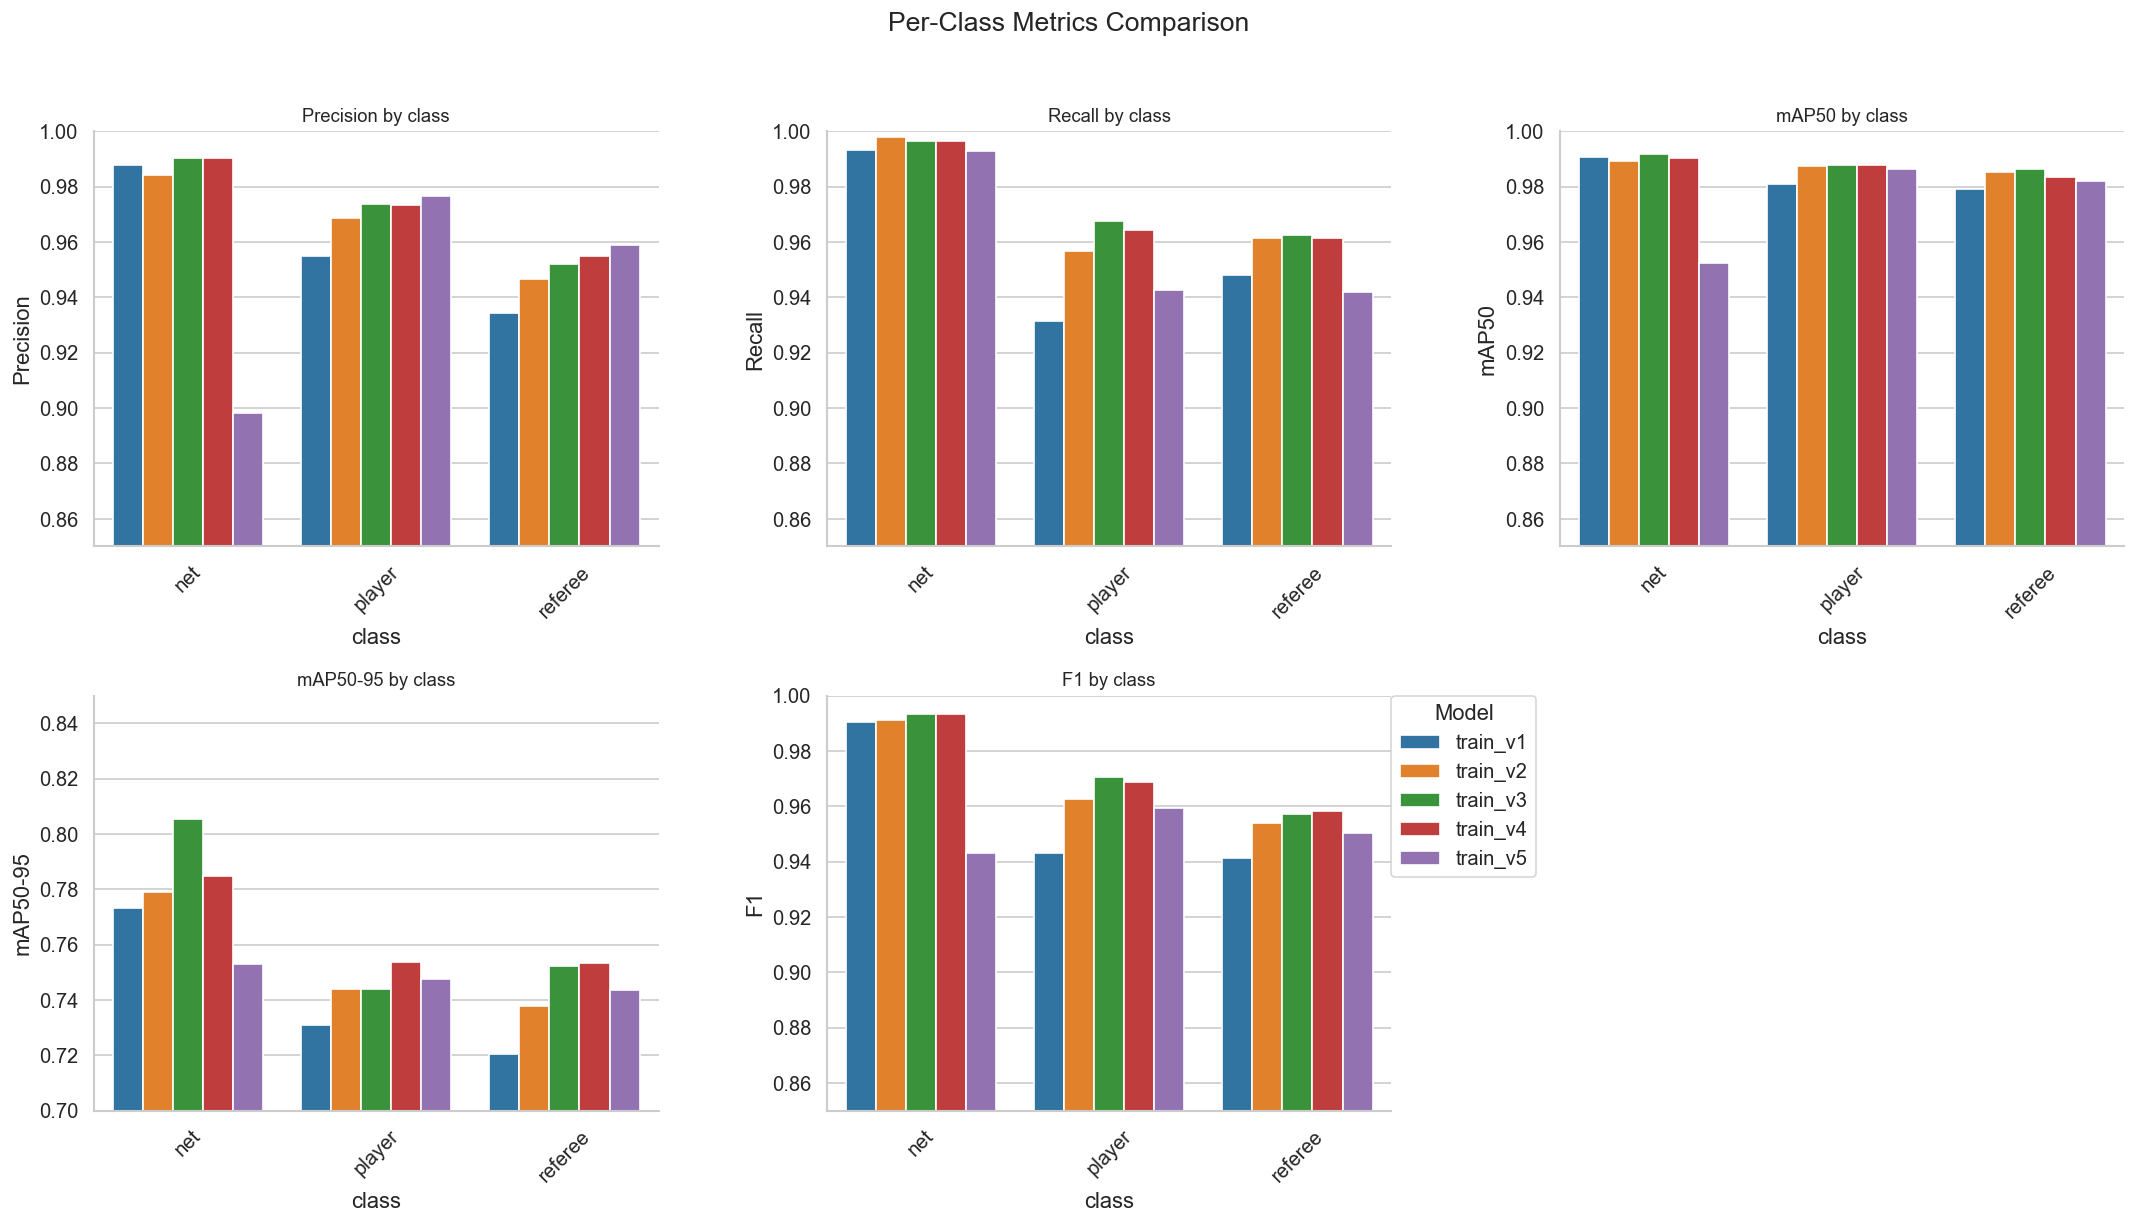

💾 Saved → /content/drive/MyDrive/DeepLearningProject/yolo_npr/results/class_metrics_comparison.png


In [ ]:
unique_models = df_all['model'].tolist()
palette       = sns.color_palette("tab10", len(unique_models))
MODEL_COLORS  = dict(zip(unique_models, palette))

# ── Per-class bar charts ───────────────────────────────────────────────────────
if not df_class.empty:

    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    fig.suptitle("Per-Class Metrics Comparison", fontsize=16, fontweight='bold', y=1.02)

    class_metrics  = ['Precision', 'Recall', 'mAP50', 'mAP50-95', 'F1']
    ax_flat_class  = axes.flatten()

    for idx, metric in enumerate(class_metrics):

        if metric in df_class.columns:

            ax = ax_flat_class[idx]

            sns.barplot(
                data=df_class,
                x='class',
                y=metric,
                hue='model',
                palette=MODEL_COLORS,
                ax=ax
            )

            ax.set_title(f'{metric} by class', fontsize=11, fontweight='bold')

            # ── Y-axis scaling logic ───────────────────────────────────────────
            if metric == 'mAP50-95':
                ax.set_ylim(0.7, 0.85)
            else:
                ax.set_ylim(0.85, 1)

            ax.tick_params(axis='x', rotation=45)
            ax.spines[['top', 'right']].set_visible(False)

            # ── Legend control ────────────────────────────────────────────────
            if metric == 'F1':
                ax.legend(
                    title="Model",
                    bbox_to_anchor=(1, 1),
                    loc='upper left',
                    borderaxespad=0
                )
            else:
                ax.get_legend().remove()

    # hide empty axes
    for idx in range(len([m for m in class_metrics if m in df_class.columns]),
                     len(ax_flat_class)):
        ax_flat_class[idx].set_visible(False)

    plt.tight_layout()
    out_path_class = OUTPUT_DIR / "class_metrics_comparison.png"
    plt.savefig(out_path_class, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"\nSaved → {out_path_class}")

#### 9.3.2 · Radar charts

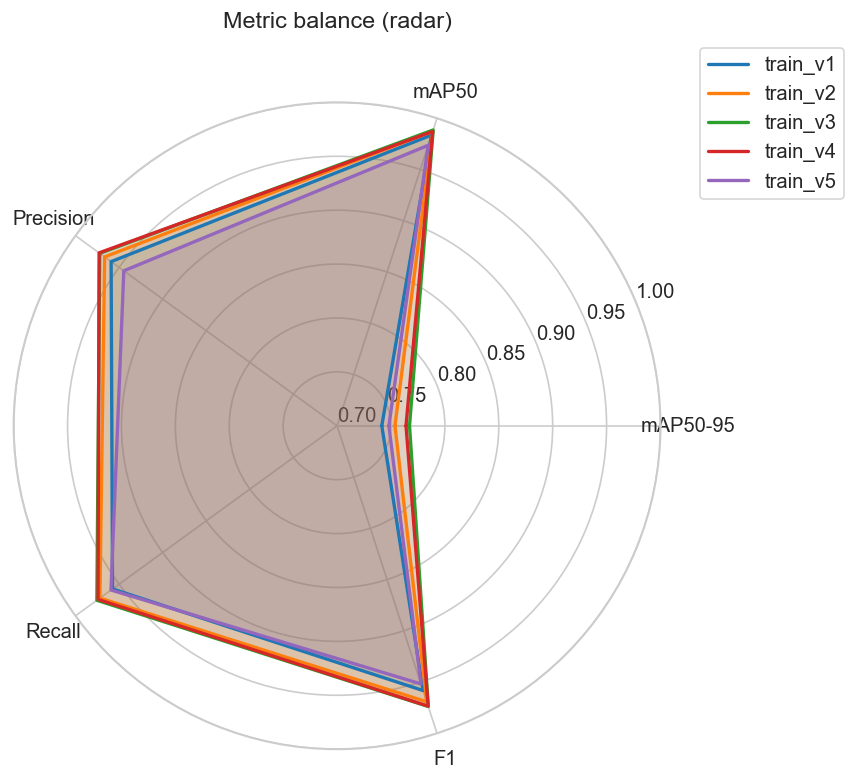

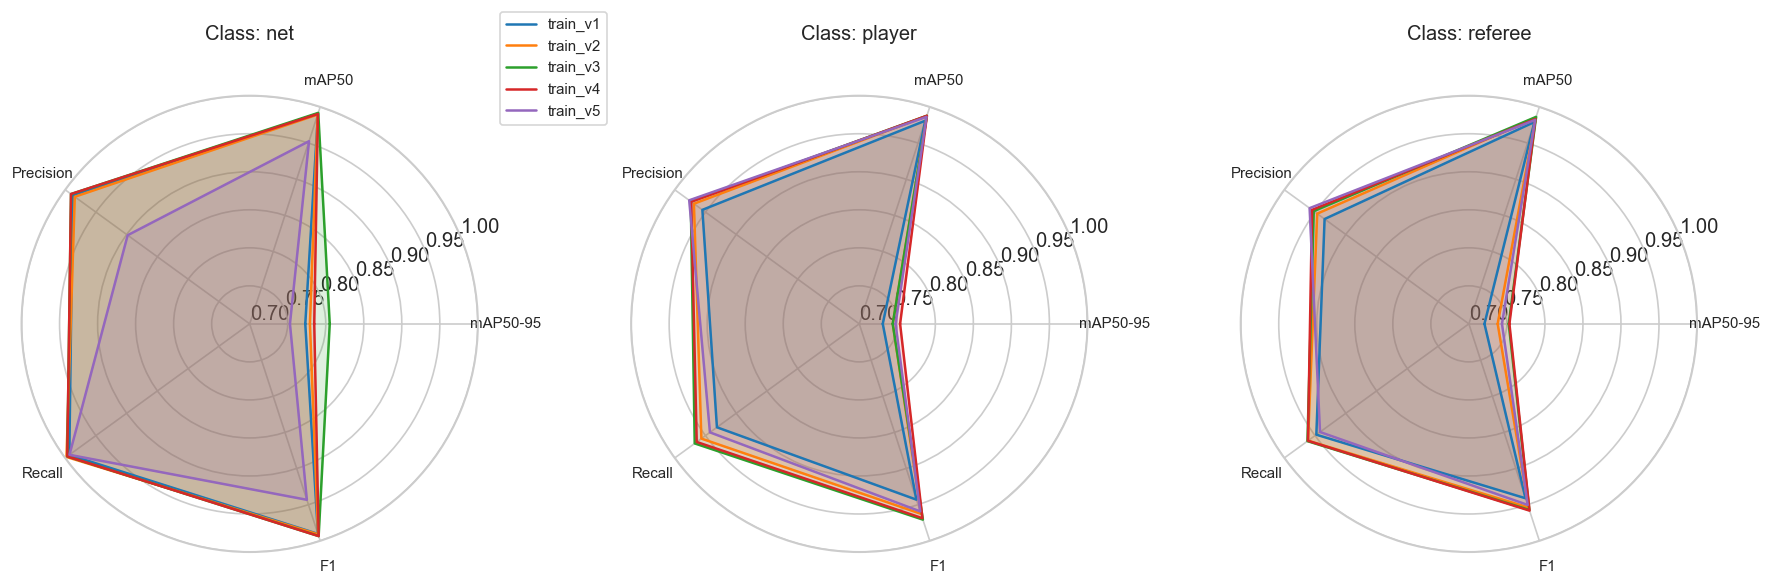

💾 Saved → /content/drive/MyDrive/DeepLearningProject/yolo_npr/results/per_class_radar_comparison.png


In [ ]:
fig = plt.figure(figsize=(16, 7))

# ── Radar (overall) ───────────────────────────────────────────────────────────
ax1 = fig.add_subplot(121, polar=True)

metrics_radar = ["mAP50-95", "mAP50", "Precision", "Recall", "F1"]
N      = len(metrics_radar)

angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]  # close loop

for _, row in df_all.iterrows():
    if all(m in row for m in metrics_radar) and not np.isnan(row['mAP50']):

        values = row[metrics_radar].values.flatten().tolist()
        values += values[:1]

        color = MODEL_COLORS.get(row['model'], "#333")

        ax1.plot(angles, values, linewidth=2, label=row['model'], color=color)
        ax1.fill(angles, values, color=color, alpha=0.15)

# axis styling
ax1.set_xticks(angles[:-1])
ax1.set_xticklabels(metrics_radar, fontsize=12, fontweight='bold')

# CHANGED RANGE
ax1.set_ylim(0.7, 1.0)

ax1.set_title('Metric balance (radar)', size=14, y=1.1, fontweight='bold')

ax1.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))


# ── Per-class radar charts ────────────────────────────────────────────────────
if not df_class.empty:

    classes  = df_class['class'].unique()
    cols     = 3
    rows     = int(np.ceil(len(classes) / cols))

    fig_cls, axes_cls = plt.subplots(
        rows, cols,
        figsize=(cols * 5, rows * 5),
        subplot_kw={'projection': 'polar'}
    )

    axes_flat = axes_cls.flatten() if len(classes) > 1 else [axes_cls]

    for idx, cls in enumerate(classes):

        ax = axes_flat[idx]
        cls_data = df_class[df_class['class'] == cls]

        for _, row in cls_data.iterrows():

            if all(m in row for m in metrics_radar) and not np.isnan(row.get('mAP50', np.nan)):

                values = row[metrics_radar].values.flatten().tolist()
                values += values[:1]

                color = MODEL_COLORS.get(row['model'], "#888")

                ax.plot(angles, values, linewidth=1.5, label=row['model'], color=color)
                ax.fill(angles, values, color=color, alpha=0.15)

        ax.set_xticks(angles[:-1])
        ax.set_xticklabels(metrics_radar, fontsize=9, fontweight='bold')

        # CHANGED RANGE
        ax.set_ylim(0.7, 1.0)

        ax.set_title(f'Class: {cls}', size=12, y=1.1, fontweight='bold')

        if idx == 0:
            ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.2), fontsize=9)

    for idx in range(len(classes), len(axes_flat)):
        axes_flat[idx].set_visible(False)

    plt.tight_layout()
    out_path_cls = OUTPUT_DIR / "per_class_radar_comparison.png"
    plt.savefig(out_path_cls, dpi=150, bbox_inches='tight')
    plt.show()

    print(f"\nSaved → {out_path_cls}")

## 10 · HYPERPARAMETERS TUNING

### 10.1 · Importing libraries for hyperparameter tuning

In [ ]:
# These packages are not included in the default Ultralytics installation.
# ray[tune] provides distributed hyperparameter tuning utilities.
# optuna is used as the Bayesian optimization backend.

subprocess.check_call([
    sys.executable, "-m", "pip", "install",
    "ray[tune]",   # Ray core + Tune scheduler/search API
    "optuna",      # Bayesian search backend used by Ray Tune
    "--quiet",
])
print("✅  ray[tune] and optuna installed.")


import ray
from ray import tune
from ray.tune.schedulers import ASHAScheduler
from ray.tune.search.optuna import OptunaSearch
from ray.tune import JupyterNotebookReporter

✅  ray[tune] and optuna installed.


### 10.2 · Paths definition

In [ ]:
# All Ray Tune trial checkpoints and results are written directly to Drive.

if not os.path.ismount('/content/drive'):
    drive.mount('/content/drive', force_remount=False)

# Root directory on Drive where the entire tuning experiment will be stored.
# Ray Tune creates one sub-folder per trial inside this directory.
DRIVE_STORAGE_DIR = Path("/content/drive/MyDrive/DeepLearningProject/") / PROJECT /"Tuning"
DRIVE_STORAGE_DIR.mkdir(parents=True, exist_ok=True)

print(f"✅  Drive mounted.  Storage → {DRIVE_STORAGE_DIR}")

✅  Drive mounted.  Storage → /content/drive/MyDrive/DeepLearningProject/yolo_npr/Tuning


### 10.3 · Loading on local device

In [ ]:
logger = logging.getLogger(__name__)

def ensure_local_dataset_auto_zip(
    drive_base_path: str,
    dataset_name: str,
    local_base_path: str = "/content/dataset",
    force_copy: bool = False
) -> str:
    """
    Checks for a zipped dataset on Drive, creates it if missing,
    and extracts it to the local Colab SSD for maximum speed.
    """
    drive_folder = Path(drive_base_path) / dataset_name
    drive_zip = Path(drive_base_path) / f"{dataset_name}.zip"

    local_path = Path(local_base_path)
    local_zip_temp = Path(f"/content/{dataset_name}_temp.zip")

    # ==========================================
    # 1. Check if already extracted locally
    # ==========================================
    already_exists = local_path.exists() and (local_path / "data.yaml").exists()

    if already_exists and not force_copy:
        print(f"Local dataset already exists at {local_path} — skipping copy")
        return str(local_path)

    # Clean up existing local folder if forcing a re-copy
    if local_path.exists() and force_copy:
        print(f"Removing existing local dataset at {local_path}")
        shutil.rmtree(local_path)

    local_path.mkdir(parents=True, exist_ok=True)

    # ==========================================
    # 2. Ensure the ZIP exists on Google Drive
    # ==========================================
    if not drive_zip.exists():
        if not drive_folder.exists():
            raise FileNotFoundError(f"❌ Cannot find source dataset folder: {drive_folder}")

        print(f"ZIP file not found on Drive. Creating it now...")
        print(f"   (This is a ONE-TIME process. It may take a few minutes but will make all future runs instant)")

        # We use the Linux zip command inside subprocess because it handles FUSE network
        # drives much faster than Python's shutil.make_archive.
        # We cd into the folder first so the zip doesn't contain absolute folder structures.
        zip_cmd = f"cd '{drive_folder}' && zip -r -q '{drive_zip}' ."
        subprocess.run(zip_cmd, shell=True, check=True)
        print(f"✅ ZIP file created successfully on Drive at {drive_zip}")
    else:
        print(f"✅ Found existing ZIP file on Drive: {drive_zip}")

    # ==========================================
    # 3. Transfer and Extract
    # ==========================================
    print("Copying ZIP from Drive → local SSD...")
    shutil.copy2(drive_zip, local_zip_temp)

    print("Unzipping dataset locally...")
    subprocess.run(["unzip", "-q", str(local_zip_temp), "-d", str(local_path)], check=True)

    # Cleanup the temporary zip file to save Colab SSD space
    if local_zip_temp.exists():
        os.remove(local_zip_temp)

    print("✅ Dataset successfully copied and extracted to local SSD")
    return str(local_path)

drive_base_path= Path("/content/drive/MyDrive/DeepLearningProject/datasets")
DATASET_PATH = ensure_local_dataset_auto_zip(
    drive_base_path=drive_base_path,
    dataset_name=dataset_name,
    local_base_path="/content/dataset",
    force_copy=False
)

data_yaml_path = Path("/content/dataset")/dataset_name/"data.yaml"

✅ Found existing ZIP file on Drive: /content/drive/MyDrive/DeepLearningProject/datasets/pla_ref_bal_net_6870.yolo26.zip
🚀 Copying ZIP from Drive → local SSD...
📦 Unzipping dataset locally...
✅ Dataset successfully copied and extracted to local SSD


### 10.4 · Configuration

In [ ]:
# Path to the dataset YAML (must already exist from the download cell above).
DATASET_YAML_PATH = data_yaml_path

# Model weights — reloaded fresh inside every trial to avoid shared state.
MODEL_WEIGHTS = "yolo26s.pt"

# Total wall-clock budget for the entire tuning session (seconds).
# 100 hours.
TOTAL_TIME_BUDGET_S = 100 * 60 * 60  #

# Maximum concurrent trials.
# run sequentially without VRAM contention.
MAX_CONCURRENT_TRIALS = 1

### 10.5 · Definition of the parameter space and the search function

In [ ]:
# Only the parameters specified are searched; everything else is locked
# to the values in HYPERPARAMS (imported from the training config cell).

SEARCH_SPACE = {

    # --- Bounding box precision ---
    "box":        tune.uniform(10.0, 20.0),
    "dfl":        tune.uniform(2.0,  4.0),

    # --- Recall & Class Imbalance ---
    # Penalizes False Negatives more heavily. Crucial for spotting missed referees.
   "cls_pw": tune.uniform(0.0, 1.0),

    # Pastes minority objects (nets, referees) onto new images to fix your class skew.
    "copy_paste": tune.uniform(0.1, 0.3),

    # --- Learning Rate ---
    # L2 regularization applied to the weights (weight decay) helps reduce
    # overfitting improving generalization.
    "lr0":        tune.loguniform(1e-4, 1e-2),
    "weight_decay": tune.loguniform(1e-4, 1e-2),

    # --- Small Object Preservation ---
    # Reduced from (0.3, 0.5). In YOLO, scale=0.5 means +/- 50% zooming.
    # Lowering this prevents small nets and distant players from shrinking out of existence.
    "scale":      tune.uniform(0.1, 0.3),

    # Mixup: Bumped the minimum slightly above 0 to ensure the network is forced
    # to learn occluded features (players blocking each other).
    # "mixup":      tune.uniform(0.05, 0.15),

    # --- Occlusion Handling ---
    # Randomly erases patches of the image. Forces the model to learn partial
    # features (e.g., recognizing a referee just by their legs or striped shirt
    # if a player is blocking them).
    "erasing":    tune.uniform(0.2, 0.6),

    # --- Context & Sizing ---
    # Mosaic stitches 4 images together. High mosaic gives great global context
    # but shrinks objects → Limit: still being able to detect the net.
    #"mosaic":     tune.uniform(0.3, 0.8),

    # --- Color & Lighting Robustness ---
    # Basketball courts have glare, shadows, and highly saturated jerseys.
    # Tuning saturation (hsv_s) and brightness/value (hsv_v) ensures the model
    # doesn't over-rely on exact jersey colors to find players.
    "hsv_s":      tune.uniform(0.3, 0.7),
    "hsv_v":      tune.uniform(0.2, 0.6),
}

### 10.6 · Define the train function

In [ ]:
# Ray Tune calls this function once per trial, passing a `config` dict
# sampled from SEARCH_SPACE.  We train for a short proxy task (20 epochs,
# 30 % of data) and report the mAP50-95(B) metric back to the scheduler.

def train_yolo_trial(config: dict) -> None:
    """
    Single Ray Tune trial.

    Parameters
    ----------
    config : dict
        Sampled hyperparameter values from SEARCH_SPACE.
    """
    # Fresh model per trial — never share a model object across trials.
    model = YOLO(MODEL_WEIGHTS)

    # Merge locked base hyperparameters with the sampled search values.
    # Sampled values deliberately override any matching keys in HYPERPARAMS.
    trial_kwargs = {
        # ── Locked proxy-task constraints (do NOT tune these) ──
        "data":     DATASET_YAML_PATH,
        "epochs":   20,          # Short proxy — enough signal for mAP50-95
        "fraction": 0.3,         # Use only 30 % of dataset → fast iterations
        "imgsz":    640,         # Fixed to avoid OOM on T4
        "batch":    16,          # Fixed to avoid OOM on T4
        "device":   0,           # GPU 0
        "verbose":  False,       # Suppress per-epoch stdout inside Ray workers
        "plots":    False,       # Skip plot generation to save I/O time
        "val":      True,        # Validation is required to get the metric

        # ── Inherited base hyperparameters ─────────────────────
        # Pull optimizer / regularisation / augmentation defaults from the
        # notebook's HYPERPARAMS dict (defined in the config cell above).
        # The four searched keys below will overwrite any matching entries.
        **{k: v for k, v in HYPERPARAMS.items()
           if k not in ("epochs", "batch", "imgsz", "device",
                        "project", "name", "exist_ok", "verbose",
                        "save_period", "fraction")},

        # ── Sampled search-space values ─────────────────────────
        "box":   config["box"],
        "dfl":   config["dfl"],
        "mixup": config["mixup"],
        "scale": config["scale"],
        "cls_pw": config["cls_pw"],
        "copy_paste": config["copy_paste"],
        "lr0": config["lr0"],
        "weight_decay": config["weight_decay"],
        "mosaic": config["mosaic"],
        "hsv_s": config["hsv_s"],
        "hsv_v": config["hsv_v"],
        "erasing": config["erasing"],
    }

    # Train the model.  results() returns a Results object with all metrics.
    results = model.train(**trial_kwargs)

    # ── Extract the target metric ──────────────────────────────────────────
    # Ultralytics stores metrics in results.results_dict.
    # Key: "metrics/mAP50-95(B)" — bounding-box mAP averaged over IoU 0.5:0.95.
    metrics_dict = results.results_dict if hasattr(results, "results_dict") else {}
    map_score = metrics_dict.get("metrics/mAP50-95(B)", 0.0)

    # Report the metric to Ray Tune.  The scheduler uses this to decide
    # whether to prune (stop early) or continue the trial.
    tune.report({"metrics/mAP50-95(B)": map_score})

### 10.7 · Configure the scheduler and search algorithm

In [ ]:
# ASHAScheduler — Asynchronous Successive Halving Algorithm.
# Aggressively terminates underperforming trials early, freeing time for
# more promising regions of the search space.
asha_scheduler = ASHAScheduler(
    # Maximum number of proxy epochs a single trial is ever allowed to run.
    # Must match or exceed the `epochs` value passed to model.train().
    max_t=20,

    # Grace period — every trial runs at least this many epochs before
    # ASHA is allowed to prune it.  Too low → kills trials prematurely.
    grace_period=5,

    # Halving factor: at each bracket level only 1/reduction_factor trials
    # survive.
    reduction_factor=3,
)

# OptunaSearch — Bayesian/TPE search backed by Optuna.
# Unlike random search, Optuna models the objective surface and proposes
# configs that are likely to improve on previous results.
optuna_search = OptunaSearch()

### 10.8 · Start searching

WARNING: Use this cell only to start a new search; otherwise, use cell 10.9 (to resume a previously interrupted search).

In [ ]:
# Ignore if Ray is already initialised (e.g. notebook was partially run).

# 1. Kill the stuck/zombie Ray cluster
ray.shutdown()
if not ray.is_initialized():
    # log_to_driver=False stops YOLO's progress bars from flooding the cell
    ray.init(ignore_reinit_error=True, log_to_driver=False)
    print("✅  Ray initialised.")


# ── Launch the tuning job ─────────────────────────────────────────

print(f"\nStarting 4-hour tuning session.  Results → {DRIVE_STORAGE_DIR}\n")
start_time = time.time()

tuner = tune.Tuner(
    # Trainable function — called once per trial.
    tune.with_resources(
        train_yolo_trial,
        resources={"gpu": 1, "cpu": 2},
    ),

    param_space=SEARCH_SPACE,

    tune_config=tune.TuneConfig(
        search_alg=optuna_search,
        scheduler=asha_scheduler,
        metric="metrics/mAP50-95(B)",
        mode="max",
        time_budget_s=TOTAL_TIME_BUDGET_S,
        max_concurrent_trials=MAX_CONCURRENT_TRIALS,
        num_samples=200,
    ),

    run_config=tune.RunConfig(
        name="yolo26s_hparam_search",
        storage_path=str(DRIVE_STORAGE_DIR),

        # ── CRITICAL: Use the notebook reporter to prevent table spam ──────
        progress_reporter=JupyterNotebookReporter(
            overwrite=True,
            max_report_frequency=10 # Updates the dashboard every 10 seconds
        ),
        verbose=2, # Required for JupyterNotebookReporter to show the table
    ),
)

# .fit() blocks until the time budget expires or all trials finish.
results = tuner.fit()

elapsed = (time.time() - start_time) / 60
print(f"\n✅  Tuning complete.  Wall time: {elapsed:.1f} min")

[I 2026-05-22 14:52:34,355] A new study created in memory with name: optuna
2026-05-22 14:52:34,361	WARNING tune.py:894 -- AIR_VERBOSITY is set, ignoring passed-in ProgressReporter for now.


Streaming output truncated to the last 5000 lines.
+-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+

Trial train_yolo_trial_ee51d6f4 finished iteration 11 at 2026-05-22 17:03:42. Total running time: 2hr 11min 7s
+----------------------------------------------------+
| Trial train_yolo_trial_ee51d6f4 result             |
+----------------------------------------------------+
| checkpoint_dir_name                                |
| time_this_iter_s                           62.3336 |
| time_total_s                               726.651 |
| training_iteration                              11 |
| epoch                                           11 |
| metrics/mAP50(B)                           0.96279 |
| metrics/mAP50-95(B)             

### 10.9 · Restore crashed session

WARNING: Run this section only to resume an interrupted search (if section 10.8 has not been started).
- Use the fit() command to resume training.
- Use the get_results() command to easily load search results for section 10.10.




In [ ]:
# Force Ray to use Jupyter-friendly formatting on restore
os.environ["RAY_TUNE_REPORTER"] = "jupyter"

# 1. Mount Drive
drive.mount("/content/drive", force_remount=False)

# 2. Re-Initialize Ray (Identical to Step 7 to prevent spam)
ray.shutdown()
if not ray.is_initialized():
    ray.init(ignore_reinit_error=True, log_to_driver=False)
    print("✅  Ray initialised.")

# Define paths (Ensure 'PROJECT' variable is defined in a previous cell)
DRIVE_STORAGE_DIR = Path("/content/drive/MyDrive/DeepLearningProject") / PROJECT / "Tuning"
EXPERIMENT_NAME   = "yolo26s_hparam_search_continued_continued2"
experiment_path   = str(DRIVE_STORAGE_DIR / EXPERIMENT_NAME)

print(f"\nRestoring crashed tuning session from → {experiment_path}\n")
start_time = time.time()

# 3. Restore the Tuner WITH GPU resources
restored_tuner = tune.Tuner.restore(
    path=experiment_path,

    # Explicitly demand GPU allocation again ──
    trainable=tune.with_resources(
        train_yolo_trial,
        resources={"gpu": 1, "cpu": 2}
    ),

    # Tells Ray to pick up interrupted trials and retry failed ones
    resume_unfinished=True,
    resume_errored=True,
)

# 4. Resume the training
results = restored_tuner.fit()

elapsed = (time.time() - start_time) / 60
print(f"\n✅  Restored tuning complete.  Wall time (this session): {elapsed:.1f} min")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


2026-05-27 12:04:08,744	INFO worker.py:2012 -- Started a local Ray instance.
Tip: In future versions of Ray, Ray will no longer override accelerator visible devices env var if num_gpus=0 or num_gpus=None (default). To enable this behavior and turn off this error message, set RAY_ACCEL_ENV_VAR_OVERRIDE_ON_ZERO=0


✅  Ray initialised.

🚀  Restoring crashed tuning session from → /content/drive/MyDrive/DeepLearningProject/yolo_npr/Tuning/yolo26s_hparam_search_continued_continued2



2026-05-27 12:04:42,044	WARNING tune.py:894 -- AIR_VERBOSITY is set, ignoring passed-in ProgressReporter for now.
2026-05-27 12:04:42,089	INFO tune_controller.py:441 -- Restoring the run from the latest experiment state file: experiment_state-2026-05-27_07-05-36.json


Streaming output truncated to the last 5000 lines.
| time_this_iter_s                           61.5901 |
| time_total_s                               228.534 |
| training_iteration                               3 |
| epoch                                            3 |
| metrics/mAP50(B)                           0.94586 |
| metrics/mAP50-95(B)                        0.63947 |
| metrics/precision(B)                       0.92108 |
| metrics/recall(B)                          0.88777 |
| val/box_loss                               1.66505 |
| val/cls_loss                               0.54814 |
| val/dfl_loss                               0.00978 |
+----------------------------------------------------+

Trial status: 87 TERMINATED | 1 RUNNING
Current time: 2026-05-27 15:52:16. Total running time: 3hr 47min 27s
Logical resource usage: 2.0/2 CPUs, 1.0/1 GPUs (0.0/1.0 accelerator_type:T4)
Current best trial: db370786 with metrics/mAP50-95(B)=0.71875 and params={'box': 11.186818225886567, '

2026-05-27 17:34:54,845	WARNING tune.py:219 -- Stop signal received (e.g. via SIGINT/Ctrl+C), ending Ray Tune run. This will try to checkpoint the experiment state one last time. Press CTRL+C (or send SIGINT/SIGKILL/SIGTERM) to skip. 
2026-05-27 17:34:56,729	INFO tune.py:1001 -- Wrote the latest version of all result files and experiment state to '/content/drive/MyDrive/DeepLearningProject/yolo_npr/Tuning/yolo26s_hparam_search_continued_continued2' in 1.8825s.



Trial status: 97 TERMINATED | 1 RUNNING
Current time: 2026-05-27 17:34:56. Total running time: 5hr 30min 7s
Logical resource usage: 2.0/2 CPUs, 1.0/1 GPUs (0.0/1.0 accelerator_type:T4)
Current best trial: db370786 with metrics/mAP50-95(B)=0.71875 and params={'box': 11.186818225886567, 'dfl': 3.0044258325445217, 'cls_pw': 0.21406536956886552, 'copy_paste': 0.18470321376991491, 'lr0': 0.008834728294932552, 'weight_decay': 0.002674334070427234, 'scale': 0.2976211904474125, 'mixup': 0.10924524530367041, 'erasing': 0.4084070605877672, 'mosaic': 0.4445828380599819, 'hsv_s': 0.4648425468530146, 'hsv_v': 0.5893485640054585}
+----------------------------------------------------------------------------------------------------------------------------------------------------------------+
| Trial name                  status         iter     total time (s)     metrics/precision(B)     metrics/recall(B)     metrics/mAP50(B)     metrics/mAP50-95(B) |
+------------------------------------------------

KeyboardInterrupt: 

### 10.10 · Results

#### 10.10.1 · Retrieve results

In [ ]:
DRIVE_STORAGE_DIR = Path("/content/drive/MyDrive/DeepLearningProject") / PROJECT / "Tuning"

# List of all the directories to combine, in chronological order
experiment_names = [
    "yolo26s_hparam_search",
    "yolo26s_hparam_search_continued",
    "yolo26s_hparam_search_continued_continued2"
]

TARGET_METRIC = "metrics/mAP50-95(B)"
all_results_dfs = []

print("Extracting and merging historical search data...\n")

for exp_name in experiment_names:
    exp_path = str(DRIVE_STORAGE_DIR / exp_name)
    try:
        # We only restore to read the results, but we need to define trainable/resources here
        tuner = tune.Tuner.restore(
            path=exp_path,
            trainable=tune.with_resources(
                train_yolo_trial,
                resources={"gpu": 1, "cpu": 2}
            )
        )
        results = tuner.get_results()

        print("Total trials:", len(results))

        for i, result in enumerate(results):

            metric = result.metrics.get("metrics/mAP50-95(B)")

            print(
                i,
                result.error,
                metric
            )

        # Extract to DataFrame
        df = results.get_dataframe(filter_metric=TARGET_METRIC, filter_mode="max")
        all_results_dfs.append(df)
        print(f"✅ Loaded {len(df)} trials from: {exp_name}")

    except Exception as e:
        print(f"❌ Could not load {exp_name}. Error: {e}")

# ── Concatenate into a single, unified search DataFrame ──
results_df = pd.concat(all_results_dfs, ignore_index=True)
print(f"\nSuccessfully unified {len(results_df)} total trials across all sessions!")

🚀 Extracting and merging historical search data...

✅ Loaded 18 trials from: yolo26s_hparam_search
✅ Loaded 20 trials from: yolo26s_hparam_search_continued
✅ Loaded 71 trials from: yolo26s_hparam_search_continued_continued2

🎉 Successfully unified 109 total trials across all sessions!


#### 10.10.2 · Print results

In [ ]:
# ── Print Top-3 hyperparameter configurations ──────────────────────────────

# Sort descending by the target metric
sorted_results_df = results_df.sort_values(TARGET_METRIC, ascending=False).reset_index(drop=True)

# 1. Get the absolute best configuration (Row 0)
best_row = sorted_results_df.iloc[0]
print("\nABSOLUTE BEST HYPERPARAMETERS FOUND (Across all 3 searches):")
print(f"   {TARGET_METRIC}: {best_row[TARGET_METRIC]:.5f}")
# Dynamically print all config columns for the winner
for col in sorted_results_df.columns:
    if col.startswith("config/"):
        print(f"   {col.replace('config/', '')}: {best_row[col]}")

print("\n" + "═" * 70)
print("  TOP-3 HYPERPARAMETER CONFIGURATIONS")
print("═" * 70)

# 2. Get the Top 3
top3_df = sorted_results_df.head(3)

SEARCH_KEYS  = ["config/box", "config/dfl", "config/mixup", "config/scale"]
DISPLAY_COLS = [TARGET_METRIC] + SEARCH_KEYS

for rank, (_, row) in enumerate(top3_df[DISPLAY_COLS].iterrows(), start=1):
    map_val = row[TARGET_METRIC]
    print(f"\n  Rank #{rank}  —  {TARGET_METRIC}: {map_val:.5f}")
    print("  " + "─" * 44)
    for key in SEARCH_KEYS:
        if key in row:
            param_name = key.replace("config/", "")
            print(f"    {param_name:10s}:  {row[key]:.6f}")

print("\n" + "═" * 70)

# Optionally persist the FULL UNIFIED results table as a CSV
csv_path = DRIVE_STORAGE_DIR / "tuning_results_all_trials_unified.csv"
sorted_results_df.to_csv(csv_path, index=False)
print(f"\n  Unified All-trial CSV saved → {csv_path}")


🏆 ABSOLUTE BEST HYPERPARAMETERS FOUND (Across all 3 searches):
   metrics/mAP50-95(B): 0.71875
   box: 11.186818225886567
   dfl: 3.0044258325445217
   cls_pw: 0.21406536956886552
   copy_paste: 0.18470321376991491
   lr0: 0.008834728294932552
   weight_decay: 0.002674334070427234
   scale: 0.2976211904474125
   mixup: 0.10924524530367041
   erasing: 0.4084070605877672
   mosaic: 0.4445828380599819
   hsv_s: 0.4648425468530146
   hsv_v: 0.5893485640054585

══════════════════════════════════════════════════════════════════════
  TOP-3 HYPERPARAMETER CONFIGURATIONS
══════════════════════════════════════════════════════════════════════

  Rank #1  —  metrics/mAP50-95(B): 0.71875
  ────────────────────────────────────────────
    box       :  11.186818
    dfl       :  3.004426
    mixup     :  0.109245
    scale     :  0.297621

  Rank #2  —  metrics/mAP50-95(B): 0.71731
  ────────────────────────────────────────────
    box       :  10.685459
    dfl       :  3.633215
    mixup     :  0